# Run if on Google Colab

In [ ]:
%pip install git+https://github.com/deepmind/dm-haiku
%pip install jaxopt
%pip install optax

  Cloning https://github.com/deepmind/dm-haiku to /tmp/pip-req-build-xo4oa829
  Running command git clone --filter=blob:none --quiet https://github.com/deepmind/dm-haiku /tmp/pip-req-build-xo4oa829
  Resolved https://github.com/deepmind/dm-haiku to commit 47500fbd438565b73508e3f443cdda85be26f39d
  Preparing metadata (setup.py) ... done
  Created wheel for dm-haiku: filename=dm_haiku-0.0.17.dev0-py3-none-any.whl size=374528 sha256=7b9b2476351e8d96ea912ed72db098c212d8b2bb13f723cf6067d1d400eec36e
  Stored in directory: /tmp/pip-ephem-wheel-cache-pou3gyc9/wheels/9e/61/4f/80a3533070997bbf330ff52c178cc780d5e60ad222899e2924
Successfully built dm-haiku
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.4/172.4 kB 15.0 MB/s eta 0:00:00


In [ ]:
# Set-up google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/My Research/Dynamic Mechanism Design

/content/drive/MyDrive/My Research/Dynamic Mechanism Design


# Set up Environment

In [ ]:
# Import packages
from typing import NamedTuple, Callable, Dict, List, Tuple
import functools
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import haiku as hk
import numpy as np
import optax
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import time
from itertools import product
import pickle
from flax import struct
# from mynetworks import *
# from myjaxutil import *
import os
import itertools


#Set seed
SEED = 42
ZERO_CLIP_MIN = 1e-4

# Plotting Method

In [ ]:
def plot_loss_dict(losses, title = ""):
    num_losses = len(losses)
    num_rows = (num_losses - 1) // 3 + 1
    fig, axs = plt.subplots(num_rows, 3, figsize=(10, 3*num_rows))
    for i, (name, loss) in enumerate(losses.items()):
        row = i // 3
        col = i % 3
        if num_rows == 1:
            axs[col].plot(loss)
            axs[col].set_title(name, fontsize=8)
            continue
        axs[row, col].plot(loss)
        axs[row, col].set_title(name, fontsize=8)

    fig.suptitle(title, fontsize=16)  # Customize the title and font size
    plt.tight_layout(rect=[0, 0, 1, 1])

    plt.show()

def plot_loss_overlay_dict(losses, print_iter, title = ""):
    num_plots = len(losses)  # Number of subplots needed
    num_cols = 3  # Number of columns per row
    num_rows = (num_plots - 1) // num_cols + 1

    fig, axs = plt.subplots(num_rows, num_cols, figsize=(10, 3 * num_rows))

    # Flatten axs array for easy indexing and handle cases where axs is not an array
    if num_rows * num_cols == 1:
        axs = [axs]
    else:
        axs = axs.flatten()

    # Iterate over the plots and their corresponding data
    for i, (plot_title, curves_dict) in enumerate(losses.items()):
        ax = axs[i]
        for legend_title, loss_values in curves_dict.items():
            x_axis = np.array(range(0, len(loss_values)))* print_iter
            ax.plot(x_axis, loss_values, label=legend_title)
        ax.set_title(plot_title)
        ax.legend()
        ax.set_xlabel("Iterations")  # Default x-axis label
        ax.set_ylabel("Normalized Values")  # Default y-axis label

    # Remove any unused subplots
    for j in range(num_plots, len(axs)):
        fig.delaxes(axs[j])

    fig.suptitle(title, fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 1])
    plt.show()


def plot_loss_dicts(loss_dicts, print_iter = 50, dict_names=None, title="",
                    row_label_pos="above",   # "above" or "below"
                    label_pad=0.06):         # fraction of that row's height
    """
    Grid: rows = loss keys, cols = dictionaries.
    Row labels are placed using the actual axes positions after layout,
    so they align perfectly with each row.

    label_pad is a fraction of the row height (not the whole figure).
    """
    if not loss_dicts:
        raise ValueError("loss_dicts must be non-empty")

    n = len(loss_dicts)
    if dict_names is None:
        dict_names = [f"Dict {i+1}" for i in range(n)]
    if len(dict_names) != n:
        raise ValueError("dict_names length must match number of dictionaries")

    # common keys, preserving first dict's order
    first_keys = list(loss_dicts[0].keys())
    common_keys = [k for k in first_keys if all(k in d for d in loss_dicts)]
    if not common_keys:
        raise ValueError("No common keys across dictionaries")

    rows, cols = len(common_keys), n
    fig, axs = plt.subplots(rows, cols, figsize=(4.0*cols, 2.3*rows), sharex="col")

    # make axs a (rows, cols) array
    if rows == 1 and cols == 1:
        axs = np.array([[axs]])
    elif rows == 1:
        axs = np.array([axs])
    elif cols == 1:
        axs = np.array([[ax] for ax in axs])

    # plot
    for r, key in enumerate(common_keys):
        for c, (name, dct) in enumerate(zip(dict_names, loss_dicts)):
            ax = axs[r, c]
            y = dct[key]
            # SCALE X BY print_iter SO TICKS SHOW TRUE EPOCHS
            x = np.arange(len(y)) * print_iter
            ax.plot(x, y)
            ax.grid(True, alpha=0.25)
            if r == 0:  # column titles on first row
                ax.set_title(name, fontsize=10)
            if r == rows - 1:
                ax.set_xlabel("epoch")

    if title:
        fig.suptitle(title, fontsize=14, y=0.995)

    # layout first, so axes positions are final
    fig.tight_layout(rect=[0.03, 0.03, 0.97, 0.96])
    fig.canvas.draw()  # ensure positions are updated

    # place a centered label per row using actual axes bounds
    for r in range(rows):
        row_axes = axs[r, :].ravel()
        # bounds in figure coords
        row_left   = min(ax.get_position().x0 for ax in row_axes)
        row_right  = max(ax.get_position().x1 for ax in row_axes)
        row_bottom = min(ax.get_position().y0 for ax in row_axes)
        row_top    = max(ax.get_position().y1 for ax in row_axes)
        row_height = row_top - row_bottom

        x_center = 0.5 * (row_left + row_right)
        if row_label_pos.lower() in ("above", "top"):
            y = row_top + label_pad * row_height
            va = "bottom"
        else:  # "below"
            y = row_bottom - label_pad * row_height
            va = "top"

        # clamp a bit to avoid clipping
        y = max(0.002, min(0.998, y))

        fig.text(x_center, y, common_keys[r],
                 ha="center", va=va, fontsize=11, fontweight="bold",
                 transform=fig.transFigure)

    plt.show()


def plot_loss_overlay_dict(losses, print_iter, title = ""):
    num_plots = len(losses)  # Number of subplots needed
    num_cols = 3  # Number of columns per row
    num_rows = (num_plots - 1) // num_cols + 1

    fig, axs = plt.subplots(num_rows, num_cols, figsize=(10, 3 * num_rows))

    # Flatten axs array for easy indexing and handle cases where axs is not an array
    if num_rows * num_cols == 1:
        axs = [axs]
    else:
        axs = axs.flatten()

    # Iterate over the plots and their corresponding data
    for i, (plot_title, curves_dict) in enumerate(losses.items()):
        ax = axs[i]
        for legend_title, loss_values in curves_dict.items():
            x_axis = np.array(range(0, len(loss_values)))* print_iter
            ax.plot(x_axis, loss_values, label=legend_title)
        ax.set_title(plot_title)
        ax.legend()
        ax.set_xlabel("Iterations")  # Default x-axis label
        ax.set_ylabel("Normalized Values")  # Default y-axis label

    # Remove any unused subplots
    for j in range(num_plots, len(axs)):
        fig.delaxes(axs[j])

    fig.suptitle(title, fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 1])
    plt.show()

# Bandit Auction

- Option A: Explicit Belief Tracking

  - Maintain a probability distribution $ b_t(s) = P(s_t \mid h_t) $ over latent states.
  - Update beliefs using a **Bayes filter**:

    $$
    b_{t+1}(s') \propto \sum_s P(s' \mid s, a_t) \cdot P(o_{t+1} \mid s') \cdot b_t(s)
    $$

  - This requires known dynamics $ P $.

- Option B: Implicit Belief via Recurrent Networks

- Use an Transformer/RNN to encode observation-action history into a belief embedding:

  $$
  b_t = \text{Trans/RNN}_\phi(b_{t-1}, o_t, a_{t-1})
  $$


## Bandit Auction Class

In [ ]:
@struct.dataclass
class State:
    """A class that stores the state of the auction."""
    time_step: int
    allocation_history: jnp.ndarray # (num_horizons, num_buyers, num_goods)
    current_type: jnp.ndarray # (num_buyers, num_goods)
    report_history: jnp.ndarray # (num_horizons, num_buyers, num_goods)

    def replace_state(self, new_time_step, new_allocation_history, new_current_type, new_report_history):
        new_state = self.replace(time_step = new_time_step, allocation_history = new_allocation_history, current_type = new_current_type, report_history = new_report_history) # type: ignore
        return new_state

    def replace_buyer_type(self, buyer, buyer_type):
        new_type = self.current_type.at[buyer].set(buyer_type)
        new_state = self.replace(current_type = new_type)
        return new_state


    def __eq__(self, other):
        return (
            self.time_step == other.time_step and
            jnp.all(self.allocation_history == other.allocation_history) and
            jnp.all(self.current_type == other.current_type) and
            jnp.all(self.report_history == other.report_history)
        )


    def _hash_array(self, arr: jnp.ndarray):
        return hash(arr.tobytes()) ^ hash(arr.shape) ^ hash(arr.dtype)


    def __hash__(self):
        return hash((
            self.time_step,
            self._hash_array(self.allocation_history),
            self._hash_array(self.current_type),
            self._hash_array(self.report_history),
        ))


@struct.dataclass
class BeliefState:
    """A class that represents the joint belief state of all buyers."""
    time_step: int
    allocation_history: jnp.ndarray
    beliefs: jnp.ndarray  # shape (num_buyers, num_profiles)
    report_history: jnp.ndarray

    def replace_state(self, new_time_step, new_allocation_history, new_beliefs, new_report_history):
        new_state = self.replace(time_step = new_time_step, allocation_history = new_allocation_history, beliefs = new_beliefs, report_history = new_report_history) # type: ignore
        return new_state



@struct.dataclass
class BanditAuction:
    """A class that stores the parameters of a bandit auction."""
    num_horizons: int = struct.field(pytree_node=False)
    num_buyers: int = struct.field(pytree_node=False)
    num_types: int = struct.field(pytree_node=False)
    num_goods: int = struct.field(pytree_node=False)
    init_state_function: Callable[["BanditAuction", jax.random.PRNGKey], State] = struct.field(pytree_node=False)
    init_belief_state_function: Callable[["BanditAuction", State], BeliefState] = struct.field(pytree_node=False)
    get_transition_prob: Callable = struct.field(pytree_node=False)
    transition_function: Callable[["BanditAuction", int, jnp.ndarray, jnp.ndarray, jax.random.PRNGKey], State] = struct.field(pytree_node=False) # p(t, type, alloc_hist, key) -> type'
    discount: float = struct.field(pytree_node=False)
    buyer_types: jnp.ndarray = struct.field(pytree_node=False)
    type_profiles: List[jnp.ndarray] = struct.field(pytree_node=False)
    allocation_profiles: List[jnp.ndarray] = struct.field(pytree_node=False)
    type_profile_keys: List[Tuple[float]] = struct.field(pytree_node=False)
    allocation_profile_keys: List[Tuple[float]] = struct.field(pytree_node=False)
    type_profile_index_map: dict = struct.field(pytree_node=False)
    allocation_index_map: dict = struct.field(pytree_node=False)
    allocation_cost: jnp.ndarray = struct.field(pytree_node=False)
    compute_hazard_rates: Callable = struct.field(pytree_node=False)

    def get_initial_state(self, key):
        return self.init_state_function(self, key)

    def get_initial_belief_state(self, state):
        return self.init_belief_state_function(self, state)

    def get_next_state(self, state, report, allocation, key):
        time_step = state.time_step
        new_time_step = time_step + 1
        new_allocation_history = state.allocation_history.at[time_step].set(allocation)
        new_current_type = self.transition_function(self, time_step, state.current_type, new_allocation_history, key)
        new_report_history = state.report_history.at[time_step].set(report)
        return state.replace_state(new_time_step, new_allocation_history, new_current_type, new_report_history)


    def get_next_belief_state(self, belief_state, report, allocation, next_state):
        """Update belief state based on report, allocation, and next state.
        Now includes total past allocations in transition probability calculation.
        """
        time_step = belief_state.time_step
        new_time_step = time_step + 1
        new_allocation_history = belief_state.allocation_history.at[time_step].set(allocation)


        def update_buyer_belief(buyer: int, buyer_belief: jnp.ndarray, allocation_history, next_state):

            def compute_next_profile_prob(next_profile):
                ## maps from t_{\tau} to P(t_{\tau+1} | t_{\tau}, x^{\tau}) * b(t_{\tau})
                def compute_current_profile_prob(current_profile):
                    # Get transition probability P(s' | s, a_t)
                    transition_prob = self.get_transition_prob(
                        self,
                        time_step,
                        current_profile,
                        allocation_history,
                        next_profile
                    )
                    # Find matching index using boolean mask
                    current_profile_mask = jnp.all(jnp.stack(self.type_profiles) == current_profile, axis=(1,2))
                    # Multiply by current belief b_t(s)
                    return transition_prob * jnp.sum(buyer_belief * current_profile_mask)

                observation_prob = (next_profile[buyer] == next_state.current_type[buyer]).astype(jnp.float32)
                ## maps from t_{\tau+1} to O(o_{\tau+1} | t_{\tau+1}) * \sum_{t'} P(t_{\tau+1} | t', x^{\tau}) * b(t_{\tau})
                return jnp.sum(jax.vmap(compute_current_profile_prob)(jnp.stack(self.type_profiles))) * observation_prob


            next_profile_probs = jax.vmap(compute_next_profile_prob)(jnp.stack(self.type_profiles))
            normalized_probs = next_profile_probs / (jnp.sum(next_profile_probs) + 1e-10)

            return normalized_probs.squeeze()


        new_beliefs = jax.vmap(
        lambda buyer: update_buyer_belief(
                buyer,
                belief_state.beliefs[buyer],
                new_allocation_history,
                next_state
            )
        )(jnp.arange(self.num_buyers))

        # print(f"new_beliefs shape: {new_beliefs.shape}")
        new_report_history = belief_state.report_history.at[time_step].set(report)

        return belief_state.replace_state(new_time_step, new_allocation_history, new_beliefs, new_report_history)



@struct.dataclass
class Mechanism:
    """A class that stores the network and parameters of a mechanism, and applies the mechanism to a state.
    Attributes:
        network: A Haiku network.
        params: The parameters of the network.
    """

    network: hk.Transformed = struct.field(pytree_node=False)
    params: hk.Params

    def __call__(self, state: State, report: jnp.ndarray, auction: BanditAuction, *args) -> jnp.ndarray:
        """Applies the mechanism to a state.
        Args:
            state: A state of the economy.
            reprot: The report of the consumer.
        Returns:
            The output (allocation probability and payment) of the network for the given state.
        """
        allocation_probs, payment = self.network.apply(self.params, state, report, auction, *args)

        return allocation_probs[:-1], payment




@struct.dataclass
class Policy:
    """A class that stores network and parameters for a policy, and applies the policy to a belief state.
    Attributes:
        network: A Haiku network.
        params: The parameters of the network.
    """

    network: hk.Transformed = struct.field(pytree_node=False)
    params: hk.Params

    def __call__(self, belief_state: BeliefState, auction: BanditAuction, key: jax.random.PRNGKey, *args) -> jnp.ndarray:
        """Applies the policy to a belief state.
        Args:
            belief state: A belief state of the economy.
        Returns:
            The output (report) of the network for the given belief state.
        """
        logits = self.network.apply(self.params, belief_state, auction, *args)
        report_indices = jax.vmap(lambda l: jax.random.categorical(key, l))(logits)
        report = jnp.stack([auction.buyer_types[i][report_indices[i]] for i in range(len(auction.buyer_types))])

        # Compute log probabilities using log_softmax and gathering the probabilities of chosen actions
        log_probs = jax.vmap(jax.nn.log_softmax)(logits)
        chosen_log_probs = jnp.array([log_probs[i, report_indices[i]] for i in range(len(auction.buyer_types))])
        chosen_log_prob = jnp.sum(chosen_log_probs)
        return report, chosen_log_prob

@struct.dataclass
class DiffPolicy:
    """A class that stores network and parameters for a policy, and applies the policy to a belief state.
    Attributes:
        network: A Haiku network.
        params: The parameters of the network.
        temperature: The temperature of the softmax.
    """

    network: hk.Transformed = struct.field(pytree_node=False)
    params: hk.Params
    temperature: float

    def __call__(self, belief_state: BeliefState, auction: BanditAuction, key: jax.random.PRNGKey, *args) -> jnp.ndarray:
        """Applies the policy to a belief state.
        Args:
            belief state: A belief state of the economy.
        Returns:
            The output (report) of the network for the given belief state.
        """
        key1, key2 = jax.random.split(key)
        logits = self.network.apply(self.params, belief_state, auction, *args)
        gumbel_noise = -jnp.log(-jnp.log(jax.random.uniform(key1, shape=logits.shape)))
        y = (logits + gumbel_noise) / self.temperature
        y_soft = jax.vmap(jax.nn.softmax)(y)
        report = jnp.einsum("bt,btd->bd", y_soft, auction.buyer_types)

        return report


@struct.dataclass
class Value:
    """A class that stores network and parameters for a cumulative regret value function, and applies the cumulative regret value function to a belief state.
    Attributes:
        network: A Haiku network.
        params: The parameters of the network.
    """
    network: hk.Transformed = struct.field(pytree_node=False)
    params: hk.Params

    def __call__(self, belief_state: BeliefState, auction: BanditAuction, *args) -> jnp.ndarray:
        """Applies the cumulative regret value function to a belief state.
        Args:
            belief state: A belief state of the economy.
        Returns:
            The output (cumulative regret value) of the network for the given belief state.
        """
        return self.network.apply(self.params, belief_state, auction, *args)



@struct.dataclass
class Episode:
    state: State
    belief_state: BeliefState
    report: jnp.ndarray
    log_prob: float
    allocation: jnp.ndarray
    payments: jnp.ndarray
    value: float
    rewards: jnp.ndarray = struct.field(default_factory=jnp.ndarray)
    regret: float = struct.field(default=0.0)

## Auction Simulator

In [ ]:
class AuctionSimulator:


    @staticmethod
    @jax.jit
    def get_rewards(auction: BanditAuction, state: State, allocation: jnp.ndarray, payment: jnp.ndarray) -> jnp.ndarray:
        """A function that takes the allocation and returns the instantaneous rewards of the buyer.
        Args:
            auction: An instance of the BanditAuction class.
            state: The current state of the auction.
            allocation: The allocation of the good.
            payment: The payment of the buyers.
        Returns:
            The rewards, which is a vector of length num_buyers.
        """
        # return jnp.sum(allocation*state.current_type, axis = 1).clip(ZERO_CLIP_MIN)
        return jnp.sum(allocation*state.current_type, axis = 1) - payment


    @staticmethod
    @jax.jit
    def get_profit(auction: BanditAuction, state: State, allocation: jnp.ndarray, payment: jnp.ndarray) -> float:
        """A function that takes the allocation and returns the instantaneous profit of the seller.
        Args:
            auction: An instance of the BanditAuction class.
            state: The current state of the auction.
            allocation: The allocation of the good.
            payment: The payment of the buyers.
        Returns:
            The profit, which is a real number, which is the profit of the seller.
        """
        return jnp.sum(payment) - jnp.sum(allocation*auction.allocation_cost)



    @staticmethod
    @jax.jit
    def get_regret(auction: BanditAuction, state: State, mechanism: Mechanism, report: jnp.ndarray, key: jax.random.PRNGKey) -> float:
        """A function that takes the state, the belief state, and the mechanism, and returns the instantaeous total regret.
        Args:
            auction: An instance of the BanditAuction class.
            state: The current state of the auction.
            belief_state: The current belief state of the auction.
            mechanism: The mechanism of the auction.
        Returns:
            The total regret, which is a real number, which is the sum of the regrets of the current report against truth-revealing strategy profile.
        """
        true_types = state.current_type
        # key1, key2 = jax.random.split(key)
        # Compute rewards for each buyer under truthful report
        truthful_allocation, truthful_payment = mechanism(state, true_types, auction)
        truthful_rewards = AuctionSimulator.get_rewards(auction, state, truthful_allocation, truthful_payment)


        # Compute rewards for each buyer's deviation while others report truthfully
        def construct_row(true_types, report, i):
            row = true_types
            return jax.lax.dynamic_update_index_in_dim(row, report[i], i, axis=0)

        # get deviated reports, where ith row is report under policy profiles (\pi_i, \pi_{-i}*)
        deviated_reports = jax.vmap(lambda i: construct_row(true_types, report, i))(jnp.arange(auction.num_buyers))
        deviated_rewards = jax.vmap(
            lambda deviated_report: AuctionSimulator.get_rewards(
                auction,
                state,
                *mechanism(state, deviated_report, auction)
            )
        )(deviated_reports)
        # Extract just the deviating buyer's reward from each row
        deviated_rewards = jnp.diag(deviated_rewards)


        return jnp.sum(deviated_rewards) - jnp.sum(truthful_rewards)



    @staticmethod
    @jax.jit
    def step(auction: BanditAuction, state: State, belief_state:BeliefState, report: jnp.ndarray, allocation: jnp.ndarray, key: jax.random.PRNGKey) -> State:
        """A function that takes the allocation and returns the next state.
        Args:
            auction: An instance of the BanditAuction class.
            state: The current state of the auction.
            belief_state: The current belief state of the auction.
            report: The report of the consumers.
            allocation: The allocation of the good.
            key: A JAX random key.
        Returns:
            next_state: The next state of the auction.
            next_belief_state: The next belief state of the auction.
        """

        next_state = auction.get_next_state(state, report, allocation, key)
        next_belief_state = auction.get_next_belief_state(belief_state, report, allocation, next_state)

        return next_state, next_belief_state


    @staticmethod
    # @jax.jit
    def sample_complete_initial_states(auction: BanditAuction):
        init_states = []
        for type_profile in auction.type_profiles:
            init_state = State(
                        time_step=0,
                        allocation_history=jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods)),
                        current_type=type_profile,
                        report_history=jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods))
                    )
            init_states.append(init_state)

        return init_states


    @staticmethod
    def sample_complete_batch(auction: BanditAuction, mechanism: Mechanism, policy: Policy, key: jax.random.PRNGKey):
        discount = auction.discount
        horizon = auction.num_horizons
        init_states = AuctionSimulator.sample_complete_initial_states(auction)
        batched_episodes = []
        for state in init_states:
            episodes = []
            belief_state = auction.get_initial_belief_state(state)
            for _ in range(horizon):
                key1, key2 = jax.random.split(key)
                # Sample the reports
                report, log_prob = policy(belief_state, auction, key1)
                # Sample allocation and payment
                allocation, payment = mechanism(state, report, auction)
                rewards = AuctionSimulator.get_rewards(auction, state, allocation, payment)
                regret = AuctionSimulator.get_regret(auction, state, mechanism, report, key)

                episode = Episode(
                    state=state,
                    belief_state=belief_state,
                    report=report,
                    log_prob=log_prob,
                    allocation=allocation,
                    payments=payment,
                    value=None,
                    rewards=rewards,
                    regret=regret,
                )
                episodes.append(episode)
                state, belief_state = AuctionSimulator.step(auction, state, belief_state, report, allocation, key)
            batched_episodes.extend(episodes)

        return batched_episodes


    @staticmethod
    def sample_complete_batch_withvalue(auction: BanditAuction, mechanism: Mechanism, policy: Policy, value: Value, key: jax.random.PRNGKey):
        discount = auction.discount
        horizon = auction.num_horizons
        init_states = AuctionSimulator.sample_complete_initial_states(auction)
        batched_episodes = []
        for state in init_states:
            episodes = []
            belief_state = auction.get_initial_belief_state(state)
            for _ in range(horizon):
                key1, key2 = jax.random.split(key)
                # Sample the reports
                report, log_prob = policy(belief_state, auction, key1)
                # Sample allocation and payment
                allocation, payment = mechanism(state, report, auction)
                value_estimate = value(belief_state, auction)
                rewards = AuctionSimulator.get_rewards(auction, state, allocation, payment)
                regret = AuctionSimulator.get_regret(auction, state, mechanism, report, key)

                episode = Episode(
                    state=state,
                    belief_state=belief_state,
                    report=report,
                    log_prob=log_prob,
                    allocation=allocation,
                    payments=payment,
                    value=value_estimate,
                    rewards=rewards,
                    regret=regret,
                )
                episodes.append(episode)
                state, belief_state = AuctionSimulator.step(auction, state, belief_state, report, allocation, key)
            batched_episodes.extend(episodes)

        return batched_episodes


    @staticmethod
    # @jax.jit
    def sample_trajectory(auction: BanditAuction, mechanism: Mechanism, policy: Policy, horizon: int, key: jax.random.PRNGKey):
        discount = auction.discount
        state = auction.get_initial_state(key)
        belief_state = auction.get_initial_belief_state(state)

        episodes = []

        for _ in range(horizon):
            key1, key2 = jax.random.split(key)
            # Sample the reports
            report, log_prob = policy(belief_state, auction, key1)
            # Sample allocation and payment
            allocation, payment = mechanism(state, report, auction)
            # value = value_network(belief_state)
            rewards = AuctionSimulator.get_rewards(auction, state, allocation, payment)
            regret = AuctionSimulator.get_regret(auction, state, mechanism, report, key)

            episode = Episode(
                state=state,
                belief_state=belief_state,
                report=report,
                log_prob=log_prob,
                allocation=allocation,
                payments=payment,
                value=None,
                rewards=rewards,
                regret=regret,
            )
            episodes.append(episode)

            state, belief_state = AuctionSimulator.step(auction, state, belief_state, report, allocation, key)

        return episodes


    @staticmethod
    def sample_trajectory_withvalue(auction: BanditAuction, mechanism: Mechanism, policy: Policy, value: Value, horizon: int, key: jax.random.PRNGKey):
        discount = auction.discount
        buyer_types = auction.buyer_types
        state = auction.get_initial_state(key)
        belief_state = auction.get_initial_belief_state(state)

        episodes = []

        for _ in range(horizon):
            key1, key2 = jax.random.split(key)
            # Sample the reports
            report, log_prob = policy(belief_state, auction, key1)
            # Sample allocation and payment
            allocation, payment = mechanism(state, report, auction)

            value_estimate = value(belief_state, auction)
            rewards = AuctionSimulator.get_rewards(auction, state, allocation, payment)
            regret = AuctionSimulator.get_regret(auction, state, mechanism, report, key)

            episode = Episode(
                state=state,
                belief_state=belief_state,
                report=report,
                log_prob=log_prob,
                allocation=allocation,
                payments=payment,
                value=value_estimate,
                rewards=rewards,
                regret=regret,
            )
            episodes.append(episode)

            state, belief_state = AuctionSimulator.step(auction, state, belief_state, report, allocation, key)

        return episodes



    @staticmethod
    @functools.partial(jax.jit, static_argnames=["num_samples"])
    def sample_init_state(auction: BanditAuction, num_samples, key: jax.random.PRNGKey):
        keys = jax.random.split(key, num_samples)
        init_state_samples = jax.vmap(auction.get_initial_state)(keys)
        return init_state_samples



    @staticmethod
    @jax.jit
    def sample_state_value(auction:BanditAuction, state: State, belief_state: BeliefState, mechanism: Mechanism, policy: Policy, key: jax.random.PRNGKey) -> jnp.ndarray:
        discount = auction.discount
        init_cumul_rewards = jnp.repeat(0.0, repeats = auction.num_buyers)
        init_state = (state, belief_state)
        init_val  = (init_cumul_rewards, init_state, key)

        @jax.jit
        def episode_step(episode_num, episode_state):
            cumul_rewards, (state, belief_state), key = episode_state
            key1, key2 = jax.random.split(key)
            report, log_prob = policy(belief_state, auction, key1)
            allocation, payment = mechanism(state, report, auction)
            rewards = AuctionSimulator.get_rewards(auction, state, allocation, payment)
            cumul_rewards += (discount**episode_num)*rewards
            next_state = AuctionSimulator.step(auction, state, belief_state, report, allocation, key)

            return (cumul_rewards, next_state, key)

        cumul_rewards, state, key = jax.lax.fori_loop(0, auction.num_horizons, episode_step, init_val)

        return cumul_rewards


    @staticmethod
    @functools.partial(jax.jit, static_argnames=["num_samples"])
    def estimate_payoff(auction: BanditAuction, mechanism: Mechanism, policy: Policy, num_samples, key: jax.random.PRNGKey):
        key1, key2 = jax.random.split(key)
        init_state_samples = AuctionSimulator.sample_init_state(auction, num_samples, key1)

        def value_fn(state):
            belief_state = auction.get_initial_belief_state(state)
            return AuctionSimulator.sample_state_value(auction, state, belief_state, mechanism, policy, key2)

        state_value_samples = jax.vmap(value_fn)(init_state_samples)
        mean_state_value = jnp.mean(state_value_samples, axis=0)
        return mean_state_value

    @staticmethod
    @jax.jit
    def sample_cumulative_regret(
        auction: BanditAuction,
        state: State,
        belief_state: BeliefState,
        mechanism: Mechanism,
        policy: DiffPolicy,
        key: jax.random.PRNGKey,
    ):
        discount = auction.discount

        def episode_step(t, carry):
            cumul_regret, (state, belief_state), key = carry
            key, k_report, k_regret, k_step = jax.random.split(key, 4)  # advance key

            report = policy(belief_state, auction, k_report)
            allocation, payment = mechanism(state, report, auction)

            regret = AuctionSimulator.get_regret(auction, state, mechanism, report, k_regret)
            cumul_regret = cumul_regret + (discount ** t) * regret

            next_state = AuctionSimulator.step(auction, state, belief_state, report, allocation, k_step)
            return (cumul_regret, next_state, key)

        init = (0.0, (state, belief_state), key)
        cumul_regret, _, _ = jax.lax.fori_loop(0, auction.num_horizons, episode_step, init)
        return cumul_regret




    @staticmethod
    @functools.partial(jax.jit, static_argnames=["num_samples"])
    def estimate_cumulative_regret(
        auction: BanditAuction,
        mechanism: Mechanism,
        policy: DiffPolicy,
        num_samples: int,
        key: jax.random.PRNGKey,
    ):
        # Split for (i) initial state sampling and (ii) per-trajectory rollouts
        key_init, key_roll = jax.random.split(key, 2)

        # Sample independent initial states
        init_state_samples = AuctionSimulator.sample_init_state(auction, num_samples, key_init)

        # One independent rollout key per trajectory
        rollout_keys = jax.random.split(key_roll, num_samples)

        # One-trajectory regret (NO num_samples here; that belongs to this estimator)
        def regret_one(state, k):
            belief_state = auction.get_initial_belief_state(state)
            return AuctionSimulator.sample_cumulative_regret(
                auction, state, belief_state, mechanism, policy, k
            )

        regret_samples = jax.vmap(regret_one)(init_state_samples, rollout_keys)
        return jnp.mean(regret_samples)

    @staticmethod
    @jax.jit
    def sample_cumulative_profit(auction: BanditAuction, state: State, mechanism: Mechanism, key: jax.random.PRNGKey):
        discount = auction.discount

        def episode_step(t, carry):
            cumul_profit, state, key = carry
            key, k_next = jax.random.split(key)  # advance key

            report = state.current_type  # truthful
            allocation, payment = mechanism(state, report, auction)
            profit = AuctionSimulator.get_profit(auction, state, allocation, payment)
            cumul_profit = cumul_profit + (discount ** t) * profit

            next_state = auction.get_next_state(state, report, allocation, k_next)
            return (cumul_profit, next_state, key)

        init = (0.0, state, key)
        cumul_profit, _, _ = jax.lax.fori_loop(0, auction.num_horizons, episode_step, init)
        return cumul_profit


    @staticmethod
    @functools.partial(jax.jit, static_argnames=["num_samples"])
    def estimate_cumulative_profit(
        auction: BanditAuction,
        mechanism: Mechanism,
        num_samples: int,
        key: jax.random.PRNGKey,
    ):
        # Split for (i) initial state sampling and (ii) per-trajectory rollouts
        key_init, key_roll = jax.random.split(key, 2)

        # Sample independent initial states
        init_state_samples = AuctionSimulator.sample_init_state(auction, num_samples, key_init)

        # One independent rollout key per trajectory
        rollout_keys = jax.random.split(key_roll, num_samples)

        def cumul_profit_fn(state, k):
            return AuctionSimulator.sample_cumulative_profit(auction, state, mechanism, k)

        cumul_profit_samples = jax.vmap(cumul_profit_fn)(init_state_samples, rollout_keys)
        mean_cumul_profit = jnp.mean(cumul_profit_samples)
        return mean_cumul_profit


    @staticmethod
    @jax.jit
    def sample_cumulative_rewards(auction: BanditAuction, state: State, mechanism: Mechanism, key: jax.random.PRNGKey):
        discount = auction.discount

        def episode_step(t, carry):
            cumul_rewards, state, key = carry
            key, k_next = jax.random.split(key)  # advance key

            report = state.current_type  # truthful
            allocation, payment = mechanism(state, report, auction)
            rewards = AuctionSimulator.get_rewards(auction, state, allocation, payment)
            cumul_rewards = cumul_rewards + (discount ** t) * rewards

            next_state = auction.get_next_state(state, report, allocation, k_next)
            return (cumul_rewards, next_state, key)

        init = (jnp.zeros((auction.num_buyers,)), state, key)
        cumul_rewards, _, _ = jax.lax.fori_loop(0, auction.num_horizons, episode_step, init)
        return cumul_rewards


    @staticmethod
    @functools.partial(jax.jit, static_argnames=["num_samples"])
    def estimate_cumulative_rewards(
        auction: BanditAuction,
        mechanism: Mechanism,
        num_samples: int,
        key: jax.random.PRNGKey,
    ):
        key_init, key_roll = jax.random.split(key, 2)

        init_state_samples = AuctionSimulator.sample_init_state(auction, num_samples, key_init)
        rollout_keys = jax.random.split(key_roll, num_samples)

        def cumul_rewards_fn(state, k):
            return AuctionSimulator.sample_cumulative_rewards(auction, state, mechanism, k)

        cumul_rewards_samples = jax.vmap(cumul_rewards_fn)(init_state_samples, rollout_keys)
        mean_cumul_rewards = jnp.mean(cumul_rewards_samples, axis=0)
        return mean_cumul_rewards



    @staticmethod
    @functools.partial(jax.jit, static_argnames=["num_samples"])
    def estimate_relu_cumulative_rewards(
        auction,
        mechanism,
        num_samples,
        key,
    ):
        key_init, key_roll = jax.random.split(key, 2)
        init_states = AuctionSimulator.sample_init_state(
            auction, num_samples, key_init
        )
        rollout_keys = jax.random.split(key_roll, num_samples)

        def one_traj(state, k):
            rewards = AuctionSimulator.sample_cumulative_rewards(
                auction, state, mechanism, k
            )
            return jax.nn.relu(-rewards)

        abs_rewards = jax.vmap(one_traj)(init_states, rollout_keys)
        return jnp.mean(abs_rewards, axis=0)



## Networks

### Mechanism Network

In [ ]:
def _mechanism_network(state: State, report: jnp.ndarray, auction: BanditAuction):
    """An improved mechanism network that processes features based on their importance:
    1. current_type (highest importance) - 64 dims
    2. report (high importance) - 64 dims
    3. total allocation history (high importance) - 48 dims
    4. report history sequence (lower importance) - 32 dims

    Returns:
        - allocation_probs: shape (num_buyers+1, num_goods) where last row is NULL buyer
        - payment: shape (num_buyers,) representing payment per buyer
    """
    num_buyers = auction.num_buyers
    num_goods = auction.num_goods

    # 1. Process current type (highest importance)
    current_type = state.current_type.reshape(num_buyers, num_goods)
    type_hidden = hk.Sequential([
        hk.Linear(128), jax.nn.relu,
        hk.Linear(64)
    ])(current_type)

    # 2. Process current report (high importance)
    report_reshaped = report.reshape(num_buyers, num_goods)
    report_hidden = hk.Sequential([
        hk.Linear(128), jax.nn.relu,
        hk.Linear(64)
    ])(report_reshaped)

    # 3. Process total allocation history (high importance)
    total_allocations = jnp.sum(state.allocation_history, axis=0)  # shape: (num_buyers, num_goods)
    alloc_features = hk.Sequential([
        hk.Linear(96), jax.nn.relu,
        hk.Linear(48)
    ])(total_allocations)

    # 4. Process report history as a sequence (lower importance)
    valid_history = state.report_history  # shape: (num_horizons, num_buyers, num_goods)

    # Process each timestep's report through a shared network
    def process_timestep(report_t):
        return hk.Sequential([
            hk.Linear(48), jax.nn.relu,
            hk.Linear(32)
        ])(report_t)

    # Map over timesteps
    sequence_features = jax.vmap(process_timestep)(valid_history)  # shape: (num_horizons, num_buyers, 32)

    # Apply simple attention mechanism
    attention_weights = hk.Sequential([
        hk.Linear(1),
        jax.nn.softmax
    ])(sequence_features)  # shape: (num_horizons, num_buyers, 1)

    # Weighted sum of sequence features
    report_history_features = jnp.sum(sequence_features * attention_weights, axis=0)  # shape: (num_buyers, 32)


    # Combine all features with appropriate dimensionality reflecting importance
    combined_features = jnp.concatenate([
        type_hidden,              # (num_buyers, 64) - highest importance
        report_hidden,            # (num_buyers, 64) - high importance
        alloc_features,          # (num_buyers, 48) - high importance
        report_history_features   # (num_buyers, 32) - lower importance
    ], axis=-1)

    # Process combined features
    hidden = hk.Sequential([
        hk.Linear(128), jax.nn.relu,
        hk.Linear(64), jax.nn.relu,
    ])(combined_features)

    # Generate allocation logits for each good
    allocation_logits = []
    for g in range(num_goods):
        # For each good, generate logits for all buyers plus NULL buyer
        good_specific = hk.Linear(num_buyers + 1)(hidden)  # shape: (num_buyers, num_buyers + 1)
        # Take mean across buyer dimension to get one logit per buyer plus NULL
        good_logits = jnp.mean(good_specific, axis=0)  # shape: (num_buyers + 1,)
        allocation_logits.append(good_logits)

    # Stack logits for all goods
    allocation_logits = jnp.stack(allocation_logits, axis=1)  # shape: (num_buyers + 1, num_goods)

    # Apply softmax to ensure sum-to-1 constraint per good
    allocation_probs = jax.nn.softmax(allocation_logits, axis=0)

    # Generate payments using combined features
    payment_hidden = hk.Sequential([
        hk.Linear(64), jax.nn.relu,
        hk.Linear(32), jax.nn.relu,
    ])(combined_features)

    # Generate one payment per buyer
    payment = hk.Linear(1)(payment_hidden).squeeze(-1)  # shape: (num_buyers,)

    return allocation_probs, payment






def _dummy_value_network(belief_state: BeliefState, auction: BanditAuction):
    """A dummy value network that returns a scalar value."""
    # Process belief state
    belief_features = belief_state.beliefs.flatten()
    time_features = jnp.array([belief_state.time_step], dtype=jnp.float32)

    # Combine features
    combined_features = jnp.concatenate([belief_features, time_features])

    # Process through MLP
    hidden = hk.Linear(64)(combined_features)
    hidden = jax.nn.relu(hidden)
    hidden = hk.Linear(32)(hidden)
    hidden = jax.nn.relu(hidden)

    # Output scalar value
    value = hk.Linear(1)(hidden)
    return value.squeeze()


def _value_network(belief_state: BeliefState, auction: BanditAuction):
    # Extract components from belief state
    beliefs = belief_state.beliefs  # Shape: (num_buyers, num_types)
    allocation_history = belief_state.allocation_history  # Shape: (H, num_buyers)
    report_history = belief_state.report_history  # Shape: (H, num_buyers)

    # Process beliefs - most important feature
    x = hk.Linear(64)(beliefs)  # Shape: (num_buyers, 64)
    x = jax.nn.relu(x)

    # Process allocation history - sum to get total allocations per buyer
    total_allocations = jnp.sum(allocation_history, axis=0)  # Shape: (num_buyers,)
    total_allocations = total_allocations.reshape(-1, 1)  # Shape: (num_buyers, 1)
    allocation_features = hk.Linear(32)(total_allocations)  # Shape: (num_buyers, 32)
    allocation_features = jax.nn.relu(allocation_features)

    # Process report history - use last few reports
    last_reports = report_history[-3:]  # Take last 3 reports, shape: (3, num_buyers)
    last_reports = last_reports.reshape(-1, 3)  # Shape: (num_buyers, 3)
    report_features = hk.Linear(32)(last_reports)  # Shape: (num_buyers, 32)
    report_features = jax.nn.relu(report_features)

    # Combine all features
    combined = jnp.concatenate([x, allocation_features, report_features], axis=-1)  # Shape: (num_buyers, 128)

    # Process combined features
    x = hk.Linear(64)(combined)
    x = jax.nn.relu(x)

    # Final value prediction
    value = hk.Linear(1)(x)  # Shape: (num_buyers, 1)

    return jnp.sum(value.squeeze())


# Create dummy networks
def _dummy_mechanism_network(state: State, report: jnp.ndarray, auction: BanditAuction):
    """A dummy mechanism network that returns random allocation probabilities and real-valued payments.
        The allocation probabilities have shape (num_buyers+1, num_goods) where the last row
        represents the NULL buyer (goods not assigned). Each column sums to 1.
    """
    num_buyers = auction.num_buyers
    num_goods = auction.num_goods

    # Flatten and concatenate inputs
    state_features = state.current_type.flatten()  # shape: (num_buyers * num_goods,)
    report_features = report.flatten()  # shape: (num_buyers * num_goods,)
    combined_features = jnp.concatenate([state_features, report_features])  # shape: (2 * num_buyers * num_goods,)

    # Create allocation logits for all buyers including NULL buyer
    allocation_logits = hk.Linear((num_buyers + 1) * num_goods)(combined_features)
    allocation_logits = allocation_logits.reshape(num_buyers + 1, num_goods)

    # Apply softmax along the buyer dimension (including NULL buyer) to ensure each column sums to 1
    allocation_probs = jax.nn.softmax(allocation_logits, axis=0)  # shape: (num_buyers + 1, num_goods)

    # Create real-valued payments (excluding NULL buyer)
    payment = hk.Linear(num_buyers)(combined_features)

    return allocation_probs, payment


def _dummy_mechanism_network_proportional(state: State, report: jnp.ndarray, auction: BanditAuction):
    """A dummy mechanism network that allocates proportionally to buyer's report.
    """
    num_buyers = auction.num_buyers
    num_goods = auction.num_goods

    # 1. Normalize the reports to create allocation probabilities:
    report_sum = jnp.sum(report, axis=0)  # Sum reports across buyers for each good
    allocation_probs = report / (report_sum[None, :] + 1e-8)  # Normalize, add small value to avoid division by zero

    # 2. Create allocation probabilities for the NULL buyer:
    null_probs = 1 - jnp.sum(allocation_probs, axis=0)  # Probability of no allocation for each good

    # 3. Stack allocation probabilities for all buyers (including NULL):
    allocation_probs = jnp.vstack([allocation_probs, null_probs])  # Shape: (num_buyers + 1, num_goods)

    # 4. Create real-valued payments (excluding NULL buyer) - proportional to allocation:
    payment = jnp.sum(allocation_probs[:-1] * report, axis=1)  # Payment for each buyer

    return allocation_probs, payment

def _dummy_policy_network(belief_state: BeliefState, auction: BanditAuction):
    """A dummy policy network that returns random action probabilities."""
    num_buyers = auction.num_buyers
    num_types = auction.num_types

    # Create random action probabilities for each buyer
    logits = hk.Linear(num_buyers * num_types)(belief_state.beliefs.flatten())
    return logits.reshape(num_buyers, num_types)


### Policy network

In [ ]:
# def _policy_network(belief_state: BeliefState, auction: BanditAuction):
#     """Policy network that uses all information from the belief state.

#     Args:
#         belief_state: Contains time_step, allocation_history, beliefs, report_history
#         auction: The auction instance

#     Returns:
#         logits: Action probabilities for each buyer
#     """
#     num_buyers = auction.num_buyers
#     num_types = auction.num_types

#     # 1. Process belief state components
#     # Time step embedding
#     time_embedding = hk.Linear(32)(jnp.array([belief_state.time_step], dtype=jnp.float32))

#     # Process allocation history
#     # Shape: (horizon, num_buyers, num_goods) -> (horizon * num_buyers * num_goods)
#     # alloc_history = belief_state.allocation_history.flatten()
#     # alloc_features = hk.Linear(64)(alloc_history)

#     total_allocations = jnp.sum(belief_state.allocation_history, axis=0).flatten()  # Shape: (num_buyers, num_goods)
#     alloc_features = hk.Linear(64)(total_allocations)

#     # Process report history
#     # Shape: (horizon, num_buyers, num_goods) -> (horizon * num_buyers * num_goods)
#     report_history = belief_state.report_history.flatten()
#     report_features = hk.Linear(64)(report_history)

#     # Process beliefs
#     # Shape: (num_buyers, num_profiles) -> (num_buyers * num_profiles)
#     belief_features = hk.Linear(128)(belief_state.beliefs.flatten())

#     # 2. Combine all features
#     combined_features = jnp.concatenate([
#         time_embedding,
#         alloc_features,
#         report_features,
#         belief_features
#     ])

#     # 3. Process through shared layers
#     hidden = combined_features
#     for hidden_size in [256, 128]:
#         hidden = hk.Linear(hidden_size)(hidden)
#         hidden = jax.nn.relu(hidden)

#     # 4. Generate action logits for each buyer
#     # First generate shared features
#     shared_features = hk.Linear(64)(hidden)

#     # Then generate buyer-specific logits
#     buyer_logits = []
#     for i in range(num_buyers):
#         # Extract buyer-specific belief information
#         buyer_beliefs = belief_state.beliefs[i]  # shape: (num_profiles,)
#         buyer_beliefs = buyer_beliefs.reshape(1, -1)  # reshape to (1, num_profiles)

#         # Combine shared features with buyer-specific beliefs
#         buyer_features = jnp.concatenate([
#             shared_features.reshape(1, -1),
#             hk.Linear(32)(buyer_beliefs)
#         ], axis=1)

#         # Generate logits for this buyer
#         buyer_hidden = hk.Linear(64)(buyer_features)
#         buyer_hidden = jax.nn.relu(buyer_hidden)
#         buyer_logit = hk.Linear(num_types)(buyer_hidden)
#         buyer_logits.append(buyer_logit.squeeze())

#     # Stack logits for all buyers
#     logits = jnp.stack(buyer_logits)  # shape: (num_buyers, num_types)

#     return logits


def _policy_network(belief_state: BeliefState, auction: BanditAuction):
    """Policy network that uses marginal beliefs for each buyer as part of the input."""
    num_buyers = auction.num_buyers
    num_types = auction.num_types
    num_profiles = len(auction.type_profiles)

    # === 1. Preprocess belief components ===
    # Compute per-buyer marginals from belief_state.beliefs
    type_profiles = jnp.stack(auction.type_profiles)  # (num_profiles, num_buyers)

    def marginal_for_buyer(i):
        def marginal_for_type(t):
            beliefs = belief_state.beliefs[i].reshape(num_profiles, -1)
            mask = (type_profiles[:, i] == auction.buyer_types[i, t]).astype(jnp.float32)
            return jnp.sum(beliefs * mask)
        return jnp.array([marginal_for_type(t) for t in range(num_types)])

    marginals = jnp.stack([marginal_for_buyer(i) for i in range(num_buyers)])  # (num_buyers, num_types)

    # === 2. Shared feature extraction ===
    time_embedding = hk.Linear(32)(jnp.array([belief_state.time_step], dtype=jnp.float32))

    total_allocations = jnp.sum(belief_state.allocation_history, axis=0).flatten()
    alloc_features = hk.Linear(64)(total_allocations)

    report_history = belief_state.report_history.flatten()
    report_features = hk.Linear(64)(report_history)

    belief_features = hk.Linear(128)(belief_state.beliefs.flatten())

    combined_features = jnp.concatenate([
        time_embedding,
        alloc_features,
        report_features,
        belief_features
    ])

    hidden = combined_features
    for hidden_size in [256, 128]:
        hidden = hk.Linear(hidden_size)(hidden)
        hidden = jax.nn.relu(hidden)

    shared_features = hk.Linear(64)(hidden)

    # === 3. Buyer-specific logic using marginals ===
    buyer_logits = []
    for i in range(num_buyers):
        buyer_marginal = marginals[i].reshape(1, -1)  # shape (1, num_types)
        buyer_belief = belief_state.beliefs[i].reshape(1, -1)
        buyer_features = jnp.concatenate([
            shared_features.reshape(1, -1),                  # shape (1, 64)
            hk.Linear(32)(buyer_marginal),     # shape (1, 32)
            hk.Linear(32)(buyer_belief)        # shape (1, 32)
        ], axis=1)
        # → buyer_features shape: (1, 96)

        buyer_hidden = hk.Linear(64)(buyer_features)
        # buyer_hidden = jax.nn.relu(buyer_hidden)
        buyer_logit = hk.Linear(num_types)(buyer_hidden)
        buyer_logits.append(buyer_logit.squeeze())
        # print("buyer_marginal", buyer_marginal)
        # print("logit before output layer", buyer_hidden)
    logits = jnp.stack(buyer_logits)
    return logits

### New Policy Network

In [ ]:
import haiku as hk
import jax
import jax.numpy as jnp

class DiscreteProtoResidualHeadSimple(hk.Module):
    """
    final_logits[i, :] = k * one_hot_truth[i, :] + residual[i, :]
    - one_hot_truth comes from your (already one-hot) marginals
    - k (proto_strength) is a learnable >=0 scalar (shared); init with proto_strength_init
    - residual last layer is zero-init (start truthful) or small-random if you want slight deviation
    """
    def __init__(self,
                 proto_strength_init: float = 10.0,   # how strongly truthful stands out at init
                 residual_init_std: float = 0.0,      # 0 => exact truthful start
                 stop_grad_truth: bool = True,
                 name=None):
        super().__init__(name=name)
        self.proto_strength_init = float(proto_strength_init)
        self.residual_init_std = float(residual_init_std)
        self.stop_grad_truth = stop_grad_truth

    def __call__(self, belief_state, auction):
        eps = 1e-12
        B, T = auction.num_buyers, auction.num_types

        # --- one-hot truth register from beliefs/profiles (your marginals are already one-hot) ---
        type_profiles = jnp.stack(auction.type_profiles)   # (P,B,G)
        buyer_types   = auction.buyer_types                # (B,T,G)

        def mask_for_buyer_type(i, t):
            return jnp.all(type_profiles[:, i, :] == buyer_types[i, t, :], axis=-1).astype(jnp.float32)  # (P,)

        mask = jax.vmap(lambda i: jax.vmap(lambda t: mask_for_buyer_type(i, t))(jnp.arange(T)))(jnp.arange(B))  # (B,T,P)
        marginals = jnp.einsum("bp,btp->bt", belief_state.beliefs, mask)  # (B,T)
        one_hot = marginals / (jnp.sum(marginals, axis=-1, keepdims=True) + eps)
        if self.stop_grad_truth:
            one_hot = jax.lax.stop_gradient(one_hot)

        # --- prototype logits: k * one_hot (k >= 0 via softplus) ---
        proto_strength_raw = hk.get_parameter("proto_strength_raw", shape=(1,),
                                              init=hk.initializers.Constant(jnp.log(jnp.expm1(self.proto_strength_init))))
        k = jax.nn.softplus(proto_strength_raw)  # scalar >= 0
        proto_logits = k * one_hot  # (B,T)

        # --- super-compact shared feature ---
        time_feat   = hk.Linear(32)(jnp.array([belief_state.time_step], dtype=jnp.float32))
        alloc_feat  = hk.Linear(64)(jnp.sum(belief_state.allocation_history, axis=0).flatten())
        # report_feat = hk.Linear(64)(belief_state.report_history.flatten())
        # belief_feat = hk.Linear(128)(belief_state.beliefs.flatten())
        shared = jnp.concatenate([time_feat, alloc_feat], axis=0)
        shared = jax.nn.relu(hk.Linear(64)(shared))  # (64,)

        # --- buyer-specific residual (last layer zero- or small-random-init) ---
        def buyer_head(i):
            bf = jnp.concatenate([
                shared.reshape(1, -1),
                hk.Linear(32)(belief_state.report_history[i].reshape(1, -1)),
                hk.Linear(32)(one_hot[i].reshape(1, -1)),             # truth register
                hk.Linear(32)(belief_state.beliefs[i].reshape(1, -1)),
            ], axis=1)

            h = jax.nn.relu(hk.Linear(64)(bf))
            w_init = (hk.initializers.RandomNormal(self.residual_init_std)
                      if self.residual_init_std > 0.0 else hk.initializers.Constant(0.0))
            res = hk.Linear(T, w_init=w_init, b_init=hk.initializers.Constant(0.0))(h).squeeze(0)  # (T,)
            return res

        residual_logits = jax.vmap(buyer_head)(jnp.arange(B))  # (B,T)
        return proto_logits + residual_logits  # (B,T)


def build_discrete_policy_net_minimal(*,
                                      proto_strength_init: float = 10.0,
                                      residual_init_std: float = 0.0,
                                      stop_grad_truth: bool = True):
    def f(belief_state, auction):
        head = DiscreteProtoResidualHeadSimple(
            proto_strength_init=proto_strength_init,
            residual_init_std=residual_init_std,
            stop_grad_truth=stop_grad_truth,
        )
        return head(belief_state, auction)
    return hk.without_apply_rng(hk.transform(f))


# Bandit Auction (Single Item)
The *bandit auction* is a setting in which a profit-maximizing seller wants to design a sequence of auctions to sell, at each time step $\tau = 0, 1, \ldots, T - 1$, an indivisible, non-storable good to a fixed set of $n$ buyers whose valuations evolve upon winning the auction. This setting captures novel applications such as repeated sponsored search auctions, where advertisers privately learn and update their valuations based on the observed profitability of clicks on their ads.

At each time step $0 \le \tau \le T - 1$, the seller owns one unit of the good, and each buyer $i$ has a valuation $v_i^{\tau} \in \mathcal{V}_i$ for the good, where $\mathcal{V}_i$ is a finite set of valuations. Each buyer reports their bid $\hat{v}_i^{(\tau)} \in \mathcal{V}_i$ to the seller, and the seller computes a (randomized) allocation $x_i^{\tau} \in [0, 1]$ and payment $p_i^{(\tau)} \in \mathbb{R}$ to the buyer $i$.

We assume quasi-linear utilities, so that the (instantaneous) utility of buyer $i$ at time step $\tau$ is given by $x_i^{\tau} v_i^{\tau} - p_i^{(\tau)}$, and the (instantaneous) utility of the seller is given by

$$
\sum_{i \in [n]} p_i^{(\tau)} - x_i^{\tau} c_i^{\tau},
$$

where $c_i^{\tau} \in \mathbb{R}$ is the cost of allocating the object to buyer $i$ at time step $\tau$.

At time step $\tau = 0$, each buyer’s valuation is drawn independently from a distribution $F_i$. For each $i \in [n]$, let $\{ R_i(\cdot \mid k) \}_{k \in \mathbb{N}}$ be a sequence of absolutely continuous, strictly increasing c.d.f.’s with mean bounded in absolute value uniformly in $k$. Then, at each time step $\tau = 1, \ldots, T - 1$, the buyer $i$’s valuation evolves according to

$$
P_i(v_i^{\tau} \mid v_i^{\tau - 1}, x_i^{\tau - 1}) = R_i\left(v_i^{\tau} - v_i^{\tau - 1} \mid \sum_{t = 0}^{\tau - 1} x_{i, t}\right),
$$

if $x_{i, \tau - 1} = 1$, i.e., if buyer $i$ is assigned with the good, and if $x_{i, \tau - 1} = 0$, i.e., the buyer $i$ is not assigned with the good, then $v_i^{\tau} = v_i^{\tau - 1}$.

## Define Auction Example

### Initial states

In [ ]:
# Example setup for a Bandit Auction with one good
def auction_init_state(auction, key):
    """Initialize state for bandit auction.
    Each buyer starts with a random type from their type space.
    """
    key, *subkeys = jax.random.split(key, auction.num_buyers + 1)
    initial_types = []
    for i in range(auction.num_buyers):
        type_idx = jax.random.categorical(subkeys[i], jnp.ones(auction.num_types))
        initial_types.append(auction.buyer_types[i, type_idx])

    return State(
        time_step=0,
        allocation_history=jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods)),
        current_type=jnp.stack(initial_types),
        report_history=jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods))
    )

def auction_init_belief_state(auction, initial_state):
    """Initialize belief state for bandit auction.
    Start with uniform belief over type profiles for each buyer.
    """
    num_profiles = len(auction.type_profiles)
    temp_beliefs = jnp.ones((auction.num_buyers, num_profiles)) / num_profiles
    temp_belef_state = BeliefState(
        time_step=-1,
        allocation_history=jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods)),
        beliefs=temp_beliefs,
        report_history=jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods))
    )

    initial_belief_state = auction.get_next_belief_state(temp_belef_state, jnp.zeros((auction.num_buyers, auction.num_goods)), jnp.zeros((auction.num_buyers, auction.num_goods)), initial_state)

    return initial_belief_state



### Compute Hazard Rates

In [ ]:
def compute_hazard_rates(auction, state):
    """Compute hazard rates for all buyers for the given initial report."""
    hazard_rates = []
    for i in range(auction.num_buyers):
        type_index = jnp.where(auction.buyer_types[i, :, 0] == state.current_type[i, 0])[0][0]
        hazard_rate = (1/auction.num_types) / (1 - (type_index+1)/auction.num_types)
        hazard_rates.append(hazard_rate)
    return jnp.array(hazard_rates)


def compute_inverse_hazard_rates(auction, state):
    """Compute inverse hazard rates for all buyers for the given initial report."""
    inverse_hazard_rates = []
    for i in range(auction.num_buyers):
        type_index = jnp.where(auction.buyer_types[i, :, 0] == state.current_type[i, 0])[0][0]
        inverse_hazard_rate = (1 - (type_index+1)/auction.num_types) / (1/auction.num_types)
        inverse_hazard_rates.append(inverse_hazard_rate)
    return jnp.array(inverse_hazard_rates)

### Create Type and allocation profiles

In [ ]:
def build_allocation_index_map(alloc_profiles):
    alloc_keys = [tuple(a.flatten().tolist()) for a in alloc_profiles]
    alloc_index_map = {key: i for i, key in enumerate(alloc_keys)}
    return alloc_keys, alloc_index_map

def create_type_and_allocation_profiles(num_buyers, num_types, num_goods):
    """Create type profiles and allocation profiles."""
    # Define buyer types (values for the single good)
    buyer_types = jnp.array([
        [[1.0], [2.0], [3.0]],  # Buyer 1's possible values
        [[1.0], [2.0], [3.0]]   # Buyer 2's possible values
    ])

    # Generate type profiles
    buyer_type_indices = list(itertools.product(range(num_types), repeat=num_buyers))
    type_profiles = []
    for indices in buyer_type_indices:
        profile = jnp.stack([buyer_types[i, idx] for i, idx in enumerate(indices)])
        type_profiles.append(profile)
    type_profiles = jnp.stack(type_profiles)

    # Create type profile mapping
    type_profile_keys = [tuple(profile.flatten().tolist()) for profile in type_profiles]
    type_profile_index_map = {key: i for i, key in enumerate(type_profile_keys)}

    # Generate allocation profiles
    alloc_profiles = [
        jnp.array([[0.0], [0.0]]),  # No allocation
        jnp.array([[1.0], [0.0]]),  # Allocated to buyer 1
        jnp.array([[0.0], [1.0]])   # Allocated to buyer 2
    ]
    alloc_keys, alloc_index_map = build_allocation_index_map(alloc_profiles)
    alloc_profiles = jnp.stack(alloc_profiles)

    return (buyer_types, type_profiles, type_profile_keys, type_profile_index_map,
            alloc_profiles, alloc_keys, alloc_index_map)



### Transition Prob

Simple transition prob:
$$ P(t_{i,\tau+1}|t_{i,\tau}, x_{i}^{\tau}) = \frac{e^{-\alpha |t_{i,\tau+1}-t_{i,\tau}|}}{\sum_{t_i'} e^{-\alpha |t_{i}'-t_{i,\tau}|}} $$
Larger $\alpha$=smaller changes, so set $\alpha = (\sum_{h=1}^\tau x_{i,h})/2$  be the total number of allocations before, so the more you get, the more you are sure aboout the value, so less likely you change.

In [ ]:
def get_transition_prob(auction: BanditAuction, time_step: int, current_type_profile, allocation_history, next_type_profile):
    def get_single_transition_prob(buyer: int, time_step: int, auction: BanditAuction, current_type: jnp.ndarray, own_alloc_history: jnp.array, next_type: jnp.ndarray):
        types = auction.buyer_types[buyer]
        past_alloc_count = jnp.sum(own_alloc_history)
        got_good = own_alloc_history[time_step, 0]

        # Compute transition probabilities using exponential decay
        diffs = jnp.abs(types - current_type)
        alpha = past_alloc_count / 2
        unnorm_probs = jnp.exp(-alpha * diffs)
        norm_probs = unnorm_probs / jnp.sum(unnorm_probs)
        # Use masking to select the probability for next_type
        mask = (types == next_type).astype(jnp.float32)
        got_good_prob = jnp.sum(norm_probs * mask)

        # If didn't get good, stay at same type
        no_change_mask = (next_type == current_type).astype(jnp.float32)
        no_change_prob = no_change_mask

        # Combine probabilities based on whether got good
        return got_good * got_good_prob + (1 - got_good) * no_change_prob

    buyer_probs = jax.vmap(
    lambda buyer: get_single_transition_prob(
        buyer,
        time_step,
        auction,
        current_type_profile[buyer],
        allocation_history[:, buyer],
        next_type_profile[buyer]
    )
    )(jnp.arange(auction.num_buyers))

    total_prob = jnp.prod(buyer_probs)

    return total_prob

### Transition Func

In [ ]:
def auction_transition_fn(auction, time_step, types, allocation_history, key):
    """Transition function for bandit auction using transition probabilities.

    Args:
        auction: The BanditAuction instance
        time_step: Current time step
        types: Current types of all buyers, shape (num_buyers, 1)
        allocation_history: History of allocations up to t (including current allocation), shape (T, num_buyers, 1)
        key: Random key for sampling

    Returns:
        new_types: New types for all buyers, shape (num_buyers, 1)
    """
    # Get all possible next type profiles
    next_profiles = jnp.stack(auction.type_profiles)

    # Compute transition probabilities for all possible next profiles
    def compute_profile_prob(next_profile):
        return auction.get_transition_prob(auction, time_step, types, allocation_history, next_profile)

    # Vectorize over all possible next profiles
    profile_probs = jax.vmap(compute_profile_prob)(next_profiles)
    # Normalize probabilities
    profile_probs = profile_probs / (jnp.sum(profile_probs) + 1e-10)
    # for i in range(len(auction.type_profiles)):
    #   profile = auction.type_profiles[i]
    #   print(f"Profile {i}: {profile}")
    #   print(f"Probability: {profile_probs[i]}")

    # Sample next profile index
    logits = jnp.where(profile_probs > 0, jnp.log(profile_probs), -jnp.inf)
    next_profile_idx = jax.random.categorical(key, logits)

    # Get the sampled next profile
    next_profile = auction.type_profiles[next_profile_idx]
    # print(f"Picked next profile is {next_profile.flatten()} with prob {profile_probs[next_profile_idx]}")

    return next_profile

### Create Auction

In [ ]:
def create_bandit_auction():
    """Create a bandit auction with 2 buyers and 3 types."""
    BANDIT_NUM_BUYERS = 2
    BANDIT_NUM_TYPES = 3
    BANDIT_NUM_GOODS = 1
    BANDIT_HORIZON = 5
    BANDIT_DISCOUNT = 0.9


    (buyer_types, type_profiles, type_profile_keys, type_profile_index_map,
     alloc_profiles, alloc_keys, alloc_index_map) = create_type_and_allocation_profiles(BANDIT_NUM_BUYERS, BANDIT_NUM_TYPES, BANDIT_NUM_GOODS)

    return BanditAuction(
        num_horizons=BANDIT_HORIZON,
        num_buyers=BANDIT_NUM_BUYERS,
        num_types=BANDIT_NUM_TYPES,
        num_goods=BANDIT_NUM_GOODS,
        init_state_function=auction_init_state,
        init_belief_state_function=auction_init_belief_state,
        get_transition_prob=get_transition_prob,
        transition_function=auction_transition_fn,
        discount=BANDIT_DISCOUNT,
        buyer_types=buyer_types,
        type_profiles=type_profiles,
        allocation_profiles=alloc_profiles,
        type_profile_keys=type_profile_keys,
        allocation_profile_keys=alloc_keys,
        type_profile_index_map=type_profile_index_map,
        allocation_index_map=alloc_index_map,
        allocation_cost=jnp.zeros((BANDIT_NUM_BUYERS, BANDIT_NUM_GOODS)) + 0.1,
        compute_hazard_rates=compute_hazard_rates
    )

auction = create_bandit_auction()

### Create Auction 2

In [ ]:
def create_type_and_allocation_profiles_2(num_buyers, num_types, num_goods):
    """Create type profiles and allocation profiles."""
    # Define buyer types (values for the single good)
    buyer_types = jnp.array([
        [[1.0], [1.333], [1.667], [2.0], [2.333], [2.667],  [3.0]],  # Buyer 1's possible values
        [[1.0], [1.333], [1.667], [2.0], [2.333], [2.667],  [3.0]]   # Buyer 2's possible values
    ])

    # Generate type profiles
    buyer_type_indices = list(itertools.product(range(num_types), repeat=num_buyers))
    type_profiles = []
    for indices in buyer_type_indices:
        profile = jnp.stack([buyer_types[i, idx] for i, idx in enumerate(indices)])
        type_profiles.append(profile)
    type_profiles = jnp.stack(type_profiles)

    # Create type profile mapping
    type_profile_keys = [tuple(profile.flatten().tolist()) for profile in type_profiles]
    type_profile_index_map = {key: i for i, key in enumerate(type_profile_keys)}

    # Generate allocation profiles
    alloc_profiles = [
        jnp.array([[0.0], [0.0]]),  # No allocation
        jnp.array([[1.0], [0.0]]),  # Allocated to buyer 1
        jnp.array([[0.0], [1.0]])   # Allocated to buyer 2
    ]
    alloc_keys, alloc_index_map = build_allocation_index_map(alloc_profiles)
    alloc_profiles = jnp.stack(alloc_profiles)

    return (buyer_types, type_profiles, type_profile_keys, type_profile_index_map,
            alloc_profiles, alloc_keys, alloc_index_map)

def create_bandit_auction_2():
    """Create a bandit auction with 2 buyers and 3 types."""
    BANDIT_NUM_BUYERS = 2
    BANDIT_NUM_TYPES = 7
    BANDIT_NUM_GOODS = 1
    BANDIT_HORIZON = 5
    BANDIT_DISCOUNT = 0.9


    (buyer_types, type_profiles, type_profile_keys, type_profile_index_map,
     alloc_profiles, alloc_keys, alloc_index_map) = create_type_and_allocation_profiles_2(BANDIT_NUM_BUYERS, BANDIT_NUM_TYPES, BANDIT_NUM_GOODS)

    return BanditAuction(
        num_horizons=BANDIT_HORIZON,
        num_buyers=BANDIT_NUM_BUYERS,
        num_types=BANDIT_NUM_TYPES,
        num_goods=BANDIT_NUM_GOODS,
        init_state_function=auction_init_state,
        init_belief_state_function=auction_init_belief_state,
        get_transition_prob=get_transition_prob,
        transition_function=auction_transition_fn,
        discount=BANDIT_DISCOUNT,
        buyer_types=buyer_types,
        type_profiles=type_profiles,
        allocation_profiles=alloc_profiles,
        type_profile_keys=type_profile_keys,
        allocation_profile_keys=alloc_keys,
        type_profile_index_map=type_profile_index_map,
        allocation_index_map=alloc_index_map,
        allocation_cost=jnp.zeros((BANDIT_NUM_BUYERS, BANDIT_NUM_GOODS)) + 0.1,
        compute_hazard_rates=compute_hazard_rates
    )

auction_2 = create_bandit_auction_2()

## Test transition consistency

In [ ]:
def test_transition_consistency(auction):
    """Test consistency between transition probability and transition function."""
    key = jax.random.PRNGKey(42)
    n_samples = 1000  # Number of samples for empirical distribution

    print("Testing transition consistency...")

    # Test Case 1: Low type, no past allocations
    print("\nTest Case 1: Buyer 1 starts at low type (1.0), gets good, no past allocations")
    t = 0
    current_types = jnp.array([[1.0], [2.0]])  # Buyer 1 at low, Buyer 2 at middle
    allocation_history = jnp.zeros((t+1, 2, 1))
    allocation_history = allocation_history.at[t].set(jnp.array([[1.0], [0.0]]))  # Buyer 1 gets good

    # Get theoretical probabilities
    current_profile = current_types

    print("\nTheoretical probabilities for Buyer 1:")
    for next_type in auction.buyer_types[0]:
        next_profile = jnp.vstack([next_type, jnp.array([2.0])])
        prob = auction.get_transition_prob(auction, t, current_types, allocation_history, next_profile)
        print(f"P(v_1^{t+1} = {next_type[0]:.3f} | v_1^{t} = 1.0) = {prob:.3f}")



    # Get empirical probabilities
    new_types_samples = []
    for _ in range(n_samples):
        key, subkey = jax.random.split(key)
        new_types = auction.transition_function(auction, t, current_types, allocation_history, subkey)
        new_types_samples.append(new_types)

    new_types_samples = jnp.stack(new_types_samples)
    unique_values, counts = jnp.unique(new_types_samples[:, 0, 0], return_counts=True)
    empirical_probs = counts / n_samples

    print("\nEmpirical probabilities for Buyer 1:")
    for val, prob in zip(unique_values, empirical_probs):
        print(f"P(v_1^{t+1} = {val:.3f} | v_1^{t} = 1.0) ≈ {prob:.3f}")




   # Test Case 2: Low type, with past allocations
    print("\nTest Case 2: Buyer 1 starts at low type (1.0), gets good, with past allocations")
    t = 1  # Using t=1 to have room for past allocation
    current_types = jnp.array([[1.0], [2.0]])  # Buyer 1 at low, Buyer 2 at middle
    allocation_history = jnp.zeros((t+1, 2, 1))
    # Set past allocation: Buyer 1 got good in previous step
    allocation_history = allocation_history.at[0].set(jnp.array([[1.0], [0.0]]))
    # Set current allocation: Buyer 1 gets good again
    allocation_history = allocation_history.at[t].set(jnp.array([[1.0], [0.0]]))

    # Get theoretical probabilities
    current_profile = current_types

    print("\nTheoretical probabilities for Buyer 1:")
    for next_type in auction.buyer_types[0]:
        next_profile = jnp.vstack([next_type, jnp.array([2.0])])
        prob = auction.get_transition_prob(auction, t, current_types, allocation_history, next_profile)
        print(f"P(v_1^{t+1} = {next_type[0]:.3f} | v_1^{t} = 1.0) = {prob:.3f}")


    # Get empirical probabilities
    new_types_samples = []
    for _ in range(n_samples):
        key, subkey = jax.random.split(key)
        new_types = auction.transition_function(auction, t, current_types, allocation_history, subkey)
        new_types_samples.append(new_types)

    new_types_samples = jnp.stack(new_types_samples)
    unique_values, counts = jnp.unique(new_types_samples[:, 0, 0], return_counts=True)
    empirical_probs = counts / n_samples

    print("\nEmpirical probabilities for Buyer 1:")
    for val, prob in zip(unique_values, empirical_probs):
        print(f"P(v_1^{t+1} = {val:.3f} | v_1^{t} = 1.0) ≈ {prob:.3f}")


    # Test Case 3: Low type, with past allocations
    print("\nTest Case 3: Buyer 1 starts at low type (1.0), didn't get good, with past allocations")
    t = 1  # Using t=1 to have room for past allocation
    current_types = jnp.array([[1.0], [2.0]])  # Buyer 1 at low, Buyer 2 at middle
    allocation_history = jnp.zeros((t+1, 2, 1))
    # Set past allocation: Buyer 1 got good in previous step
    allocation_history = allocation_history.at[0].set(jnp.array([[1.0], [0.0]]))
    # Set current allocation: Buyer 2 gets good
    allocation_history = allocation_history.at[t].set(jnp.array([[0.0], [0.0]]))

    # Get theoretical probabilities
    current_profile = current_types

    print("\nTheoretical probabilities for Buyer 1:")
    for next_type in auction.buyer_types[0]:
        next_profile = jnp.vstack([next_type, jnp.array([2.0])])
        prob = auction.get_transition_prob(auction, t, current_types, allocation_history, next_profile)
        print(f"P(v_1^{t+1} = {next_type[0]:.3f} | v_1^{t} = 1.0) = {prob:.3f}")



    # Get empirical probabilities
    new_types_samples = []
    for _ in range(n_samples):
        key, subkey = jax.random.split(key)
        new_types = auction.transition_function(auction, t, current_types, allocation_history, subkey)
        new_types_samples.append(new_types)

    new_types_samples = jnp.stack(new_types_samples)
    unique_values, counts = jnp.unique(new_types_samples[:, 0, 0], return_counts=True)
    empirical_probs = counts / n_samples

    print("\nEmpirical probabilities for Buyer 1:")
    for val, prob in zip(unique_values, empirical_probs):
        print(f"P(v_1^{t+1} = {val:.3f} | v_1^{t} = 1.0) ≈ {prob:.3f}")


# Run the test
test_transition_consistency(auction_2)

Testing transition consistency...

Test Case 1: Buyer 1 starts at low type (1.0), gets good, no past allocations

Theoretical probabilities for Buyer 1:
P(v_1^1 = 1.000 | v_1^0 = 1.0) = 0.223
P(v_1^1 = 1.333 | v_1^0 = 1.0) = 0.189
P(v_1^1 = 1.667 | v_1^0 = 1.0) = 0.160
P(v_1^1 = 2.000 | v_1^0 = 1.0) = 0.135
P(v_1^1 = 2.333 | v_1^0 = 1.0) = 0.114
P(v_1^1 = 2.667 | v_1^0 = 1.0) = 0.097
P(v_1^1 = 3.000 | v_1^0 = 1.0) = 0.082

Empirical probabilities for Buyer 1:
P(v_1^1 = 1.000 | v_1^0 = 1.0) ≈ 0.230
P(v_1^1 = 1.333 | v_1^0 = 1.0) ≈ 0.176
P(v_1^1 = 1.667 | v_1^0 = 1.0) ≈ 0.180
P(v_1^1 = 2.000 | v_1^0 = 1.0) ≈ 0.120
P(v_1^1 = 2.333 | v_1^0 = 1.0) ≈ 0.098
P(v_1^1 = 2.667 | v_1^0 = 1.0) ≈ 0.114
P(v_1^1 = 3.000 | v_1^0 = 1.0) ≈ 0.082

Test Case 2: Buyer 1 starts at low type (1.0), gets good, with past allocations

Theoretical probabilities for Buyer 1:
P(v_1^2 = 1.000 | v_1^1 = 1.0) = 0.314
P(v_1^2 = 1.333 | v_1^1 = 1.0) = 0.225
P(v_1^2 = 1.667 | v_1^1 = 1.0) = 0.161
P(v_1^2 = 2.000 | v_1^1 =

# Lower Level Problem

## Differentiable Simulator for Lower Problem

### Initialize identity policy params

In [ ]:
from copy import deepcopy

def make_identity_policy_params(
    params,
    buyer_layer_keys,
    buyer_hidden_keys,
    marginal_proj_keys,
    num_types,
    proj_dim=32,
    hidden_dim=64,
    buyer_input_dim=128  # shared 64 + marginal projection 32 + belief projection 32
):
    """
    Overrides Haiku policy network parameters so that it outputs the marginal
    distributions directly as logits.

    Arguments:
        params:         original initialized Haiku parameters
        buyer_layer_keys: final output layer names (e.g. ['linear_9', 'linear_12'])
        buyer_hidden_keys: intermediate buyer_hidden layer names (e.g. ['linear_8', 'linear_11'])
        marginal_proj_keys: projection layer for buyer_marginal (e.g. ['linear_7', 'linear_10'])
        num_types:      number of types per buyer
        proj_dim:       output dim of marginal projection layer (default 32)
        hidden_dim:     dim of buyer_hidden (default 64)
        buyer_input_dim: input dim to buyer_hidden (shared + projected = 64 + 32 = 96)
    """
    new_params = deepcopy(params)

    ### 1. Final output layer: extract from buyer_hidden[32:35]
    for key in buyer_layer_keys:
        W = jnp.zeros((hidden_dim, num_types))  # shape (64, 3)
        b = jnp.zeros((num_types,))
        W = W.at[32:32 + num_types, :].set(jnp.eye(num_types))  # map hidden[32:35] to logits
        new_params[key]['w'] = W
        new_params[key]['b'] = b

    ### 2. Marginal projection layer: identity
    for key in marginal_proj_keys:
        W = jnp.zeros((num_types, proj_dim))  # shape (3, 32)
        b = jnp.zeros((proj_dim,))
        W = W.at[:num_types, :num_types].set(jnp.eye(num_types))  # identity in top-left
        new_params[key]['w'] = W
        new_params[key]['b'] = b

    ### 3. Buyer hidden layer: route marginal proj to dims 32:35
    for key in buyer_hidden_keys:
        W = jnp.zeros((buyer_input_dim, hidden_dim))  # shape (96, 64)
        b = jnp.zeros((hidden_dim,))
        marginal_start = 64
        W = W.at[marginal_start : marginal_start + num_types, 32:32 + num_types].set(jnp.eye(num_types))  # marginal proj → dims 32–34
        new_params[key]['w'] = W
        new_params[key]['b'] = b

    ### 4. Zero out everything else
    special_keys = set(buyer_layer_keys + buyer_hidden_keys + marginal_proj_keys)
    for name in new_params:
        if name not in special_keys:
            new_params[name]['w'] = jnp.zeros_like(new_params[name]['w'])
            new_params[name]['b'] = jnp.zeros_like(new_params[name]['b'])

    return new_params


In [ ]:
prng = hk.PRNGSequence(SEED)
state = auction.get_initial_state(next(prng))
belief_state = auction.get_initial_belief_state(state)
policy_network = hk.without_apply_rng(hk.transform(_policy_network))
policy_params = policy_network.init(next(prng), belief_state, auction)

for name in policy_params:
    print(name, policy_params[name]['w'].shape)



buyer_layer_keys = ['linear_10', 'linear_14']
# buyer_layer_keys=['linear_9', 'linear_12']
marginal_proj_keys = ['linear_7', 'linear_11']
# marginal_proj_keys=['linear_7', 'linear_10']
buyer_hidden_keys = ['linear_9', 'linear_13']
# buyer_hidden_keys=['linear_8', 'linear_11']
identity_params = make_identity_policy_params(
    policy_params,
    buyer_layer_keys=buyer_layer_keys,
    buyer_hidden_keys=buyer_hidden_keys,
    marginal_proj_keys=marginal_proj_keys,
    num_types=auction.num_types,
)

state = auction.get_initial_state(next(prng))
belief_state = auction.get_initial_belief_state(state)
print(belief_state.beliefs)
logits = policy_network.apply(identity_params, belief_state, auction)

num_profiles = len(auction.type_profiles)
def marginal_for_buyer(i, belief_state):
    def marginal_for_type(t, belief_state):
        beliefs = belief_state.beliefs[i].reshape(num_profiles, -1)
        mask = (auction.type_profiles[:, i] == auction.buyer_types[i, t]).astype(jnp.float32)
        return jnp.sum(beliefs * mask)
    return jnp.array([marginal_for_type(t, belief_state) for t in range(auction.num_types)])

marginals = jnp.stack([marginal_for_buyer(i, belief_state) for i in range(auction.num_buyers)])
print("Input marginals:\n", marginals)
print("Logits from network:\n", logits)

report = state.current_type
allocation = jnp.array([[1.0], [0.0]])
next_state = auction.get_next_state(state, report, allocation, next(prng))
next_belief_state = auction.get_next_belief_state(belief_state, report, allocation, next_state)
marginals = jnp.stack([marginal_for_buyer(i, next_belief_state) for i in range(auction.num_buyers)])
print("Intput marginals:\n", marginals)
print("Logits from network:\n", policy_network.apply(identity_params, next_belief_state, auction))



linear (1, 32)
linear_1 (2, 64)
linear_2 (10, 64)
linear_3 (18, 128)
linear_4 (288, 256)
linear_5 (256, 128)
linear_6 (128, 64)
linear_7 (3, 32)
linear_8 (9, 32)
linear_9 (128, 64)
linear_10 (64, 3)
linear_11 (3, 32)
linear_12 (9, 32)
linear_13 (128, 64)
linear_14 (64, 3)
[[0.33333334 0.33333334 0.33333334 0.         0.         0.
  0.         0.         0.        ]
 [0.         0.         0.33333334 0.         0.         0.33333334
  0.         0.         0.33333334]]
Input marginals:
 [[1. 0. 0.]
 [0. 0. 1.]]
Logits from network:
 [[1. 0. 0.]
 [0. 0. 1.]]
Intput marginals:
 [[1. 0. 0.]
 [0. 0. 1.]]
Logits from network:
 [[1. 0. 0.]
 [0. 0. 1.]]


### Maximize cumulative regret

In [ ]:
def maximize_cumul_regret(auction: BanditAuction,
                        mechanism_network,
                        mechanism_params,
                        policy_network,
                        num_epochs = 1000,
                        num_iters_per_batch = 1,
                        num_samples = 32,
                        learning_rate = 1e-5,
                        print_iter = 50,
                        initial_truthful = True,
                        seed = SEED,
                        ):
    cumul_regrets = []
    prng = hk.PRNGSequence(seed)

    # Initialize mechanism and policy params
    mechanism = Mechanism(mechanism_network, mechanism_params)
    policy_params = policy_network.init(next(prng), auction.get_initial_belief_state(auction.get_initial_state(next(prng))), auction)
    if initial_truthful:
        policy_params = make_identity_policy_params(
                                            policy_params,
                                            buyer_layer_keys=buyer_layer_keys,
                                            buyer_hidden_keys=buyer_hidden_keys,
                                            marginal_proj_keys=marginal_proj_keys,
                                            num_types=auction.num_types,
                                        )
    # Create optimizer
    policy_optimizer = optax.adam(learning_rate)
    policy_opt_state = policy_optimizer.init(policy_params)


    def temperature_schedule_exp(epoch, tau0=1.0, tau_min=0.1, decay_rate=0.005):
        return jnp.maximum(tau_min, tau0 * jnp.exp(-decay_rate * epoch))


    @jax.jit
    def cumulative_regret_loss(policy_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        policy = DiffPolicy(policy_network, policy_params, temperature)
        cumul_regret = AuctionSimulator.estimate_cumulative_regret(auction, mechanism, policy, num_samples, key)
        return cumul_regret


    @jax.jit
    def get_grads(policy_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        cumul_regret, policy_network_grad = jax.value_and_grad(cumulative_regret_loss)(policy_params, key, temperature)
        return cumul_regret, policy_network_grad


    @jax.jit
    def update_params(policy_params, policy_opt_state, key: jax.random.PRNGKey, temperature: float):
        cumul_regret, policy_network_grad = get_grads(policy_params, key, temperature)
        # print(jax.make_jaxpr(get_grads)(policy_params, key))

        # Print norm of policy_network_grad to check if the update is correctly implememted
        # print(f"Policy network grad: {jax.tree_map(lambda g: jnp.linalg.norm(g), policy_network_grad)}")


        # Policy Network Update
        policy_network_grad = jax.tree_util.tree_map(lambda x: -x, policy_network_grad)
        policy_updates, policy_opt_state = policy_optimizer.update(policy_network_grad, policy_opt_state, policy_params)
        policy_params = optax.apply_updates(policy_params, policy_updates)

        return cumul_regret, policy_params, policy_opt_state


    for epoch in range(num_epochs):
        key = next(prng)
        temperature = temperature_schedule_exp(epoch)

        for _ in range(num_iters_per_batch):
            if epoch % print_iter == 0:
                print(f"==================== Epoch {epoch} ====================")
                cumul_regret = cumulative_regret_loss(policy_params, key, temperature)
                print(f"Cumulative Regret: {cumul_regret}")
                cumul_regrets.append(cumul_regret)
            cumul_regret, policy_params, policy_opt_state = update_params(policy_params, policy_opt_state, key, temperature)

    policy = DiffPolicy(policy_network, policy_params, temperature)

    return cumul_regrets, policy

In [ ]:
policy_lr_sweep = [1e-1, 1e-2, 1e-3, 1e-4]
num_samples = 32
num_epochs = 1000
num_iters_per_batch = 1
print_iter = 20

# Create Haiku networks
mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
policy_network = hk.without_apply_rng(hk.transform(_policy_network))
# Initialize network parameters
key = jax.random.PRNGKey(42)
mechanism_params = mechanism_network.init(key, auction.get_initial_state(key), auction.get_initial_state(key).current_type, auction)
# policy_params = policy_network.init(key, auction.get_initial_belief_state(), auction)

data_cumul_regrets = {f"Policy lr: {policy_lr}": [] for policy_lr in policy_lr_sweep}
for policy_lr in policy_lr_sweep:
    print(f"==================== Policy lr: {policy_lr} ====================")
    cumul_regrets, policy = maximize_cumul_regret(auction,
                        mechanism_network,
                        mechanism_params,
                        policy_network,
                        num_epochs,
                        num_iters_per_batch,
                        num_samples,
                        policy_lr,
                        print_iter
                        )
    data_cumul_regrets[f"Policy lr: {policy_lr}"] = cumul_regrets

==================== Policy lr: 0.1 ====================
==================== Epoch 0 ====================
Cumulative Regret: 0.06633608043193817
==================== Epoch 20 ====================
Cumulative Regret: 0.36594295501708984
==================== Epoch 40 ====================
Cumulative Regret: 0.4162519574165344
==================== Epoch 60 ====================
Cumulative Regret: 0.2901645600795746
==================== Epoch 80 ====================
Cumulative Regret: 0.31421130895614624
==================== Epoch 100 ====================
Cumulative Regret: 0.3384040594100952
==================== Epoch 120 ====================
Cumulative Regret: 0.3491719365119934
==================== Epoch 140 ====================
Cumulative Regret: 0.3305168151855469
==================== Epoch 160 ====================
Cumulative Regret: 0.34019002318382263
==================== Epoch 180 ====================
Cumulative Regret: 0.4794641137123108
==================== Epoch 200 ==============

In [ ]:
plot_loss_dict(data_cumul_regrets, "Cumulative Regret")
for key, value in data_cumul_regrets.items():
    print(jnp.mean(jnp.array(value)))

## New Differentiable Simulator for Lower Problem

### Initialize identity policy params

In [ ]:
# Build the logits network
policy_net = build_discrete_policy_net_minimal(
    proto_strength_init=10.0,   # how strong truthful proto is
    residual_init_std=1.0,      # 0 => exact truthful start
    stop_grad_truth=True        # freeze truthful part during training
)
# Initialize once
key = jax.random.PRNGKey(42)
prng = hk.PRNGSequence(42) # Initialize a PRNG sequence
state =   auction.get_initial_state(next(prng))
belief_state = auction.get_initial_belief_state(state) # Pass a new key here
params = policy_net.init(key, belief_state, auction)

# Wrap with your DiffPolicy (you already have this class)
policy = DiffPolicy(policy_net, params, 0.01)

# Forward (differentiable): returns (B, G)
print("true types", state.current_type)
key = jax.random.PRNGKey(42)
logits = policy_net.apply(params, belief_state, auction)
print("logits", logits)
report = policy(belief_state, auction, key)
print("reports", report)



true types [[2.]
 [3.]]
logits [[-0.8727753  10.059854    0.58923995]
 [-0.79522634  1.3317975  11.730783  ]]
reports [[2.]
 [3.]]


### Maximize cumulative regret

In [ ]:
def maximize_cumul_regret(auction: BanditAuction,
                        mechanism_network,
                        mechanism_params,
                        policy_network,
                        num_epochs = 1000,
                        num_iters_per_batch = 1,
                        num_samples = 32,
                        learning_rate = 1e-5,
                        print_iter = 50,
                        initial_truthful = True,
                        seed = SEED,
                        ):
    cumul_regrets = []
    prng = hk.PRNGSequence(seed)

    # Initialize mechanism and policy params
    mechanism = Mechanism(mechanism_network, mechanism_params)
    policy_params = policy_network.init(next(prng), auction.get_initial_belief_state(auction.get_initial_state(next(prng))), auction)
    # if initial_truthful:
    #     policy_params = make_identity_policy_params(
    #                                         policy_params,
    #                                         buyer_layer_keys=buyer_layer_keys,
    #                                         buyer_hidden_keys=buyer_hidden_keys,
    #                                         marginal_proj_keys=marginal_proj_keys,
    #                                         num_types=auction.num_types,
    #                                     )
    # Create optimizer
    policy_optimizer = optax.adam(learning_rate)
    policy_opt_state = policy_optimizer.init(policy_params)


    def temperature_schedule_exp(epoch, tau0=1.0, tau_min=0.1, decay_rate=0.005):
        return jnp.maximum(tau_min, tau0 * jnp.exp(-decay_rate * epoch))


    @jax.jit
    def cumulative_regret_loss(policy_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        policy = DiffPolicy(policy_network, policy_params, temperature)
        cumul_regret = AuctionSimulator.estimate_cumulative_regret(auction, mechanism, policy, num_samples, key)
        return cumul_regret


    @jax.jit
    def get_grads(policy_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        cumul_regret, policy_network_grad = jax.value_and_grad(cumulative_regret_loss)(policy_params, key, temperature)
        return cumul_regret, policy_network_grad


    @jax.jit
    def update_params(policy_params, policy_opt_state, key: jax.random.PRNGKey, temperature: float):
        cumul_regret, policy_network_grad = get_grads(policy_params, key, temperature)
        # print(jax.make_jaxpr(get_grads)(policy_params, key))

        # Print norm of policy_network_grad to check if the update is correctly implememted
        # print(f"Policy network grad: {jax.tree_map(lambda g: jnp.linalg.norm(g), policy_network_grad)}")


        # Policy Network Update
        policy_network_grad = jax.tree_util.tree_map(lambda x: -x, policy_network_grad)
        policy_updates, policy_opt_state = policy_optimizer.update(policy_network_grad, policy_opt_state, policy_params)
        policy_params = optax.apply_updates(policy_params, policy_updates)

        return cumul_regret, policy_params, policy_opt_state


    for epoch in range(num_epochs):
        key = next(prng)
        temperature = temperature_schedule_exp(epoch)

        for _ in range(num_iters_per_batch):
            if epoch % print_iter == 0:
                print(f"==================== Epoch {epoch} ====================")
                cumul_regret = cumulative_regret_loss(policy_params, key, temperature)
                print(f"Cumulative Regret: {cumul_regret}")
            # cumul_regret = cumulative_regret_loss(policy_params, key, temperature)
                cumul_regrets.append(cumul_regret)
            cumul_regret, policy_params, policy_opt_state = update_params(policy_params, policy_opt_state, key, temperature)

    policy = DiffPolicy(policy_network, policy_params, temperature)

    return cumul_regrets, policy

In [ ]:
policy_lr_sweep = [1e-2, 1e-3, 1e-4]
num_samples = 32
num_epochs = 1000
num_iters_per_batch = 1
print_iter = 20

# Create Haiku networks
mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
policy_network = build_discrete_policy_net_minimal(
    proto_strength_init=0.5,   # how strong truthful proto is
    residual_init_std=1.0,      # 0 => exact truthful start
    stop_grad_truth=True        # freeze truthful part during training
)
# policy_network = hk.without_apply_rng(hk.transform(_policy_network))
# Initialize network parameters
key = jax.random.PRNGKey(37686)
mechanism_params = mechanism_network.init(key, auction.get_initial_state(key), auction.get_initial_state(key).current_type, auction)
# policy_params = policy_network.init(key, auction.get_initial_belief_state(), auction)

data_cumul_regrets = {f"Policy lr: {policy_lr}": [] for policy_lr in policy_lr_sweep}
for policy_lr in policy_lr_sweep:
    print(f"==================== Policy lr: {policy_lr} ====================")
    cumul_regrets, policy = maximize_cumul_regret(auction,
                        mechanism_network,
                        mechanism_params,
                        policy_network,
                        num_epochs,
                        num_iters_per_batch,
                        num_samples,
                        policy_lr,
                        print_iter
                        )
    data_cumul_regrets[f"Policy lr: {policy_lr}"] = cumul_regrets

==================== Policy lr: 0.01 ====================
==================== Epoch 0 ====================
Cumulative Regret: 0.17548809945583344
==================== Epoch 20 ====================
Cumulative Regret: 0.2566356062889099
==================== Epoch 40 ====================
Cumulative Regret: 0.26615098118782043
==================== Epoch 60 ====================
Cumulative Regret: 0.3051171898841858
==================== Epoch 80 ====================
Cumulative Regret: 0.3763118088245392
==================== Epoch 100 ====================
Cumulative Regret: 0.2743745446205139
==================== Epoch 120 ====================
Cumulative Regret: 0.29407328367233276
==================== Epoch 140 ====================
Cumulative Regret: 0.4317481517791748
==================== Epoch 160 ====================
Cumulative Regret: 0.3066316246986389
==================== Epoch 180 ====================
Cumulative Regret: 0.2397620677947998
==================== Epoch 200 ==============

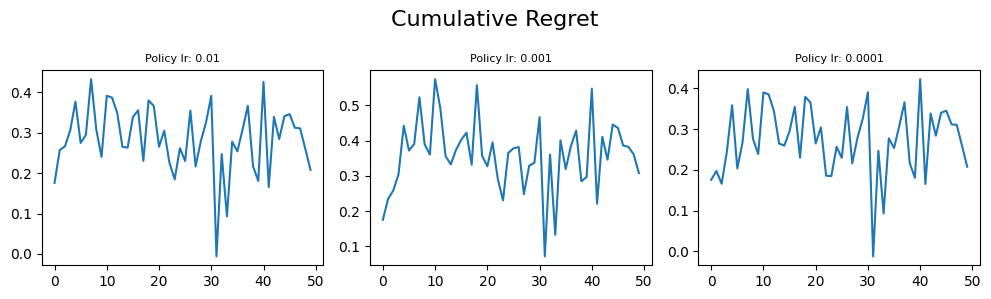

0.28411078
0.35846674
0.27402863


In [ ]:
plot_loss_dict(data_cumul_regrets, "Cumulative Regret")
for key, value in data_cumul_regrets.items():
    print(jnp.mean(jnp.array(value)))

# Solve Entire Problem

## Compute Exploitability

In [ ]:
def compute_exploitability(auction: BanditAuction,
                        mechanism_network,
                        mechanism_params,
                        policy_network,
                        num_epochs = 1000,
                        num_samples = 32,
                        learning_rate_exp = 1e-3,
                        print_iter = 50,
                        initial_truthful = True,
                        seed = SEED
                        ):
    cumul_regrets = []
    prng = hk.PRNGSequence(seed)

    # Initialize mechanism and policy params
    mechanism = Mechanism(mechanism_network, mechanism_params)
    policy_params = policy_network.init(next(prng), auction.get_initial_belief_state(auction.get_initial_state(next(prng))), auction)
    # if initial_truthful:
    #     policy_params = make_identity_policy_params(
    #                                         policy_params,
    #                                         buyer_layer_keys=buyer_layer_keys,
    #                                         buyer_hidden_keys=buyer_hidden_keys,
    #                                         marginal_proj_keys=marginal_proj_keys,
    #                                         num_types=auction.num_types,
    #                                     )
    # Create optimizer
    policy_optimizer = optax.adam(learning_rate_exp)
    policy_opt_state = policy_optimizer.init(policy_params)


    def temperature_schedule_exp(epoch, tau0=1.0, tau_min=0.1, decay_rate=0.005):
        return jnp.maximum(tau_min, tau0 * jnp.exp(-decay_rate * epoch))


    @jax.jit
    def cumulative_regret_loss(policy_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        policy = DiffPolicy(policy_network, policy_params, temperature)
        cumul_regret = AuctionSimulator.estimate_cumulative_regret(auction, mechanism, policy, num_samples, key)
        return cumul_regret


    @jax.jit
    def get_grads(policy_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        cumul_regret, policy_network_grad = jax.value_and_grad(cumulative_regret_loss)(policy_params, key, temperature)
        return cumul_regret, policy_network_grad


    @jax.jit
    def update_params(policy_params, policy_opt_state, key: jax.random.PRNGKey, temperature: float):
        cumul_regret, policy_network_grad = get_grads(policy_params, key, temperature)
        # print(jax.make_jaxpr(get_grads)(policy_params, key))

        # Print norm of policy_network_grad to check if the update is correctly implememted
        # print(f"Policy network grad: {jax.tree_map(lambda g: jnp.linalg.norm(g), policy_network_grad)}")


        # Policy Network Update
        policy_network_grad = jax.tree_util.tree_map(lambda x: -x, policy_network_grad)
        policy_updates, policy_opt_state = policy_optimizer.update(policy_network_grad, policy_opt_state, policy_params)
        policy_params = optax.apply_updates(policy_params, policy_updates)

        return cumul_regret, policy_params, policy_opt_state


    for epoch in range(num_epochs):
        key = next(prng)
        temperature = temperature_schedule_exp(epoch)

        cumul_regret, policy_params, policy_opt_state = update_params(policy_params, policy_opt_state, key, temperature)

        if epoch % print_iter == 0:
          print(f"\t==================== Exp Epoch {epoch} ====================")
          print(f"\tExploitability: {cumul_regret}")
        cumul_regrets.append(cumul_regret)

    policy = DiffPolicy(policy_network, policy_params, temperature)

    return cumul_regrets, policy

## Method 1: GDA for Min-Max Method
Do binary search on target principal objective value $\tau$, and for each $\tau$, use Gradient Descent Ascent to solve
$$ \min_{\theta} \max_{\pi} |f(\theta)-\tau| + g(\theta, \pi)$$
where $f(\theta)$ is the cumulative profit of the mechanism assuming the buyers always truthfully report, and $g(\theta, \pi)$ is the cumulative regret of policy $\pi$ respect to the truthful reporting policy, under mechanism $\theta$.

In [ ]:
def GDA_obj(auction: BanditAuction,
                        mechanism_network,
                        policy_network,
                        profit_goal,
                        num_epochs = 1000,
                        num_iters_per_batch = 1,
                        num_samples = 32,
                        learning_rates = (1e-4, 5e-6),
                        print_iter = 50,
                        alpha = 1e5,
                        beta = 1e3,
                        compute_exploit = False,
                        num_epochs_exp = 1000,
                        learning_rate_exp = 1e-3,
                        print_iter_exp = 50
                        ):
    profit_losses = []
    cumul_regret_losses = []
    ir_losses = []
    total_losses = []
    exploitabilities = []
    good_mechs = []

    prng = hk.PRNGSequence(SEED)

    # Initialize mechanism and policy params
    mechanism_params = mechanism_network.init(next(prng), auction.get_initial_state(next(prng)), jnp.zeros((auction.num_buyers, auction.num_goods)), auction)
    policy_params = policy_network.init(next(prng), auction.get_initial_belief_state(auction.get_initial_state(next(prng))), auction)
    # policy_params = make_identity_policy_params(
    #                                     policy_params,
    #                                     buyer_layer_keys=buyer_layer_keys,
    #                                     buyer_hidden_keys=buyer_hidden_keys,
    #                                     marginal_proj_keys=marginal_proj_keys,
    #                                     num_types=auction.num_types,
    #                                 )
    # Create optimizers
    mechanism_optimizer = optax.adam(learning_rates[0])
    mechanism_opt_state = mechanism_optimizer.init(mechanism_params)
    policy_optimizer = optax.adam(learning_rates[1])
    policy_opt_state = policy_optimizer.init(policy_params)


    def temperature_schedule_exp(epoch, tau0=1.0, tau_min=0.1, decay_rate=0.005):
        return jnp.maximum(tau_min, tau0 * jnp.exp(-decay_rate * epoch))


    @jax.jit
    def cumulative_regret_loss_fn(mechanism_params: hk.Params, policy_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        policy = DiffPolicy(policy_network, policy_params, temperature)
        cumul_regret = AuctionSimulator.estimate_cumulative_regret(auction, mechanism, policy, num_samples, key)
        return cumul_regret

    @jax.jit
    def ir_loss_fn(mechanism_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        policy = DiffPolicy(policy_network, policy_params, temperature)
        expected_cumul_rewards = AuctionSimulator.estimate_cumulative_rewards(auction, mechanism, num_samples, key)
        return jnp.sum(jnp.abs(expected_cumul_rewards))

    @jax.jit
    def profit_loss_fn(mechanism_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        policy = DiffPolicy(policy_network, policy_params, temperature)
        cumulative_profit = AuctionSimulator.estimate_cumulative_profit(auction, mechanism, num_samples, key)
        return profit_goal - cumulative_profit
        # return jnp.abs(profit_goal - cumulative_profit)

    @jax.jit
    def total_loss_fn(mechanism_params: hk.Params, policy_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        cumul_regret_loss = cumulative_regret_loss_fn(mechanism_params, policy_params, key, temperature)
        profit_loss = profit_loss_fn(mechanism_params, key, temperature)
        ir_loss = ir_loss_fn(mechanism_params, key, temperature)
        return alpha * cumul_regret_loss +  jnp.abs(profit_loss) + beta * ir_loss


    @jax.jit
    def get_grads(mechanism_params:  hk.Params, policy_params:  hk.Params, key: jax.random.PRNGKey, temperature: float):
        total_loss, (mechanism_network_grad, policy_network_grad) = jax.value_and_grad(total_loss_fn, argnums=[0, 1])(mechanism_params, policy_params, key, temperature)
        return total_loss, mechanism_network_grad, policy_network_grad


    @jax.jit
    def update_params(mechanism_params, policy_params, mechanism_opt_state, policy_opt_state, key: jax.random.PRNGKey, temperature: float):
        total_loss, mechanism_network_grad, policy_network_grad = get_grads(mechanism_params, policy_params, key, temperature)
        # mechanism Network Update
        mechanism_updates, mechanism_opt_state = mechanism_optimizer.update(mechanism_network_grad, mechanism_opt_state, mechanism_params)
        mechanism_params = optax.apply_updates(mechanism_params, mechanism_updates)

        # policy Network Update
        policy_network_grad = jax.tree_util.tree_map(lambda x: -x, policy_network_grad)
        policy_updates, policy_opt_state = policy_optimizer.update(policy_network_grad, policy_opt_state, policy_params)
        policy_params = optax.apply_updates(policy_params, policy_updates)

        return total_loss, (mechanism_params, policy_params), (mechanism_opt_state, policy_opt_state)


    for epoch in range(num_epochs):
        key = next(prng)
        temperature = temperature_schedule_exp(epoch)

        for _ in range(num_iters_per_batch):
            total_loss, (mechanism_params, policy_params), (mechanism_opt_state, policy_opt_state) = update_params(mechanism_params, policy_params, mechanism_opt_state, policy_opt_state, next(prng), temperature)

        if epoch % print_iter == 0:
          print(f"==================== Epoch {epoch} ====================")
          cumul_regret_loss = cumulative_regret_loss_fn(mechanism_params, policy_params, next(prng), temperature)
          profit_loss = profit_loss_fn(mechanism_params, next(prng), temperature)
          ir_loss = ir_loss_fn(mechanism_params, next(prng), temperature)
          print(f"Cumulative Regret Loss: {cumul_regret_loss}")
          print(f"Profit Loss: {profit_loss}")
          print(f"IR Loss: {ir_loss}")
          cumul_regret_losses.append(cumul_regret_loss)
          profit_losses.append(profit_loss)
          ir_losses.append(ir_loss)
          # total_losses.append(total_loss)

          if compute_exploit:
            exploits, _ = compute_exploitability(auction, mechanism_network, mechanism_params, policy_network, num_epochs_exp, num_samples, learning_rate_exp, print_iter_exp)
            avg_exploit = jnp.mean(jnp.array(exploits[-50:]))
            print(f"Exploitability: {avg_exploit}")
            exploitabilities.append(avg_exploit)

            if profit_loss <= 0.1 and ir_loss <= 0.1 and avg_exploit <= 0.1:
              good_mech_tuple = (mechanism_params, profit_loss, ir_loss, avg_exploit)
              good_mechs.append(good_mech_tuple)
              break

    mechanism = Mechanism(mechanism_network, mechanism_params)
    policy = DiffPolicy(policy_network, policy_params, temperature)

    return cumul_regret_losses, profit_losses, ir_losses, exploitabilities, good_mechs, mechanism, policy

In [ ]:
mech_lr_sweep = [1e-5]
policy_lr_sweep = [1e-5]
alpha_sweep = [0.5] # cumul_regret weight
beta_sweep = [1.25] # ir loss weight
profit_goal_sweep = [6.508866]

num_samples = 32
num_epochs = 10000
num_iters_per_batch = 2
print_iter = 10
# profit_goal = 6.508866

compute_exploit = True
num_epochs_exp = 1000
learning_rate_exp = 1e-3
print_iter_exp = 500


# Create Haiku networks
mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
# policy_network = hk.without_apply_rng(hk.transform(_policy_network))
policy_network = build_discrete_policy_net_minimal(
    proto_strength_init=1.0,   # how strong truthful proto is
    residual_init_std=1.0,      # 0 => exact truthful start
    stop_grad_truth=True        # freeze truthful part during training
)




# data_cumul_regret_loss_gda = {f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}": [] for mech_lr, policy_lr, alpha in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep)}
data_profit_loss_gda = {f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}": [] for mech_lr, policy_lr, alpha, beta, profit_goal in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep, beta_sweep, profit_goal_sweep)}
data_ir_loss_gda = {f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}": [] for mech_lr, policy_lr, alpha, beta, profit_goal in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep, beta_sweep, profit_goal_sweep)}
data_exploitability_gda = {f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}": [] for mech_lr, policy_lr, alpha, beta, profit_goal in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep, beta_sweep, profit_goal_sweep)}
data_mechanism_gda = {f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}": [] for mech_lr, policy_lr, alpha, beta, profit_goal in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep, beta_sweep, profit_goal_sweep)}
for mech_lr, policy_lr, alpha, beta, profit_goal  in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep, beta_sweep, profit_goal_sweep):
    print(f"==================== mech. lr: {mech_lr}, policy lr: {policy_lr}, alpha: {alpha}, beta: {beta}, profit goal: {profit_goal} ====================")
    cumul_regret_losses, profit_losses, ir_losses, exploitabilities, good_mechs, _, _= GDA_obj(auction, mechanism_network, policy_network, profit_goal, num_epochs,
                                                                     num_iters_per_batch, num_samples, (mech_lr, policy_lr), print_iter, alpha, beta,
                                                                     compute_exploit, num_epochs_exp, learning_rate_exp, print_iter_exp)
    # data_cumul_regret_loss_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}"] = cumul_regret_losses
    data_profit_loss_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"] = profit_losses
    data_ir_loss_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"] = ir_losses
    data_exploitability_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"] = exploitabilities
    data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"] = good_mechs

==================== mech. lr: 1e-05, policy lr: 1e-05, alpha: 0.5, beta: 1.25, profit goal: 6.508866 ====================
==================== Epoch 0 ====================
Cumulative Regret Loss: 0.4227530360221863
Profit Loss: 2.3636512756347656
IR Loss: 1.0999311208724976
	==================== Exp Epoch 0 ====================
	Exploitability: 0.5992271304130554
	==================== Exp Epoch 500 ====================
	Exploitability: 0.056296009570360184
Exploitability: 0.7304368615150452
==================== Epoch 10 ====================
Cumulative Regret Loss: 0.502539873123169
Profit Loss: 2.0284886360168457
IR Loss: 0.17643290758132935
	==================== Exp Epoch 0 ====================
	Exploitability: 0.4911569654941559
	==================== Exp Epoch 500 ====================
	Exploitability: 0.1541152000427246
Exploitability: 0.7210331559181213
==================== Epoch 20 ====================
Cumulative Regret Loss: 0.3427583575248718
Profit Loss: 1.3219523429870605
IR L

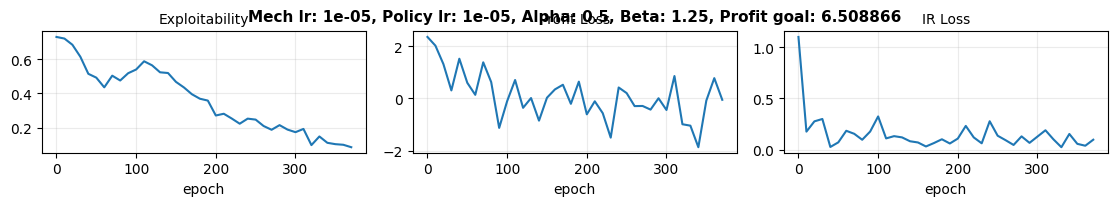

In [ ]:
plot_loss_dicts([data_exploitability_gda, data_profit_loss_gda, data_ir_loss_gda], print_iter, dict_names=['Exploitability', 'Profit Loss', 'IR Loss'])

In [ ]:
for mech_lr, policy_lr, alpha, beta, profit_goal in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep, beta_sweep, profit_goal_sweep):
    if len(data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"]) > 0:
        print(f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}", len(data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"]))
    for good_mech_tuple in data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"]:
        mechanism_params, profit_loss, ir_loss, exploitability = good_mech_tuple
        print(f"profit_loss: {profit_loss}, ir_loss: {ir_loss}, exploitability: {exploitability}, profit_goal: {profit_goal}")

Mech lr: 1e-05, Policy lr: 1e-05, Alpha: 0.5, Beta: 1.25, Profit goal: 6.508866 1
profit_loss: -0.050592899322509766, ir_loss: 0.09758321940898895, exploitability: 0.08506117761135101, profit_goal: 6.508866


In [ ]:
# Create the directory if it doesn't exist
save_dir = "data"
os.makedirs(save_dir, exist_ok=True)

# Define the filename
filename = os.path.join(save_dir, "single_item_data_mechanism_gda_3.pkl")

# Save the dictionary using pickle
with open(filename, 'wb') as f:
    pickle.dump(data_mechanism_gda, f)

print(f"Data saved to {filename}")


Data saved to data/single_item_data_mechanism_gda_3.pkl


### Test the output mechanism

In [ ]:
# Define the filename
save_dir = "data"
good_params_filename = os.path.join(save_dir, "single_item_data_mechanism_gda_3.pkl")

# Load the dictionary using pickle
try:
    with open(good_params_filename, 'rb') as f:
        data_mechanism_gda = pickle.load(f)
    print(f"Data loaded successfully from {good_params_filename}")
except FileNotFoundError:
    print(f"File not found: {good_params_filename}. Please ensure the file exists in the '{save_dir}' directory.")
except Exception as e:
    print(f"An error occurred while loading the file: {e}")

Data loaded successfully from data/single_item_data_mechanism_gda_3.pkl


In [ ]:
for item, value in data_mechanism_gda.items():
    print(item, len(value))

Mech lr: 1e-05, Policy lr: 1e-05, Alpha: 0.5, Beta: 1.25, Profit goal: 6.508866 1


In [ ]:
mech_lr_sweep = [1e-5]
policy_lr_sweep = [1e-5]
alpha_sweep = [0.5] # cumul_regret weight
beta_sweep = [1.25] # ir loss weight
profit_goal_sweep = [6.508866]

for mech_lr, policy_lr, alpha, beta, profit_goal in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep, beta_sweep, profit_goal_sweep):
    if len(data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"]) > 0:
        print(f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}", len(data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"]))
    for good_mech_tuple in data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"]:
        mechanism_params, profit_loss, ir_loss, exploitability = good_mech_tuple
        print(f"profit_loss: {profit_loss}, ir_loss: {ir_loss}, exploitability: {exploitability}, profit_goal: {profit_goal}")


Mech lr: 1e-05, Policy lr: 1e-05, Alpha: 0.5, Beta: 1.25, Profit goal: 6.508866 1
profit_loss: -0.050592899322509766, ir_loss: 0.09758321940898895, exploitability: 0.08506117761135101, profit_goal: 6.508866


In [ ]:
import random

mech_lr = 1e-5
policy_lr = 1e-5
alpha = 0.5
beta = 1.25
profit_goal = 6.508866
good_mech_tuples = data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"]
mechanism_params, profit_loss, ir_loss, exploitability = good_mech_tuples[0]
print(f"profit_loss: {profit_loss}, ir_loss: {ir_loss}, exploitability: {exploitability}")

policy_lr_sweep = [1e-3, 5e-4, 1e-4]
num_samples = 32
num_epochs = 1000
num_iters_per_batch = 1
print_iter = 10

# Create Haiku networks
mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
# policy_network = hk.without_apply_rng(hk.transform(_policy_network))
policy_network = build_discrete_policy_net_minimal(
    proto_strength_init=1.0,   # how strong truthful proto is
    residual_init_std=1.0,      # 0 => exact truthful start
    stop_grad_truth=True        # freeze truthful part during training
)


# Generate 30 random seeds
random_seeds = [random.getrandbits(32) for _ in range(30)]
exploitabilities = []
for random_seed in random_seeds:
  # data_cumul_regrets = {f"Policy lr: {policy_lr}": [] for policy_lr in policy_lr_sweep}
  highest_exploitability = -1e5
  for policy_lr in policy_lr_sweep:
      print(f"==================== Policy lr: {policy_lr} ====================")
      cumul_regrets, policy = maximize_cumul_regret(auction,
                          mechanism_network,
                          mechanism_params,
                          policy_network,
                          num_epochs,
                          num_iters_per_batch,
                          num_samples,
                          policy_lr,
                          print_iter,
                          initial_truthful=False,
                          seed = random_seed
                          )
      avg_exploit = jnp.mean(jnp.array(cumul_regrets[-5:]))
      print(f"avg_exploit: {avg_exploit}")
      if avg_exploit > highest_exploitability:
          highest_exploitability = avg_exploit
  print(f"Exploitability: {highest_exploitability}")
  exploitabilities.append(highest_exploitability)

Streaming output truncated to the last 5000 lines.
==================== Epoch 290 ====================
Cumulative Regret: -0.10073629766702652
==================== Epoch 300 ====================
Cumulative Regret: 0.03971146419644356
==================== Epoch 310 ====================
Cumulative Regret: -0.024058939889073372
==================== Epoch 320 ====================
Cumulative Regret: 0.03931096941232681
==================== Epoch 330 ====================
Cumulative Regret: 0.03246346488595009
==================== Epoch 340 ====================
Cumulative Regret: 0.057913731783628464
==================== Epoch 350 ====================
Cumulative Regret: 0.032020069658756256
==================== Epoch 360 ====================
Cumulative Regret: 0.029893692582845688
==================== Epoch 370 ====================
Cumulative Regret: 0.0367073155939579
==================== Epoch 380 ====================
Cumulative Regret: 0.04304277151823044
==================== Epoch 390 ===

In [ ]:
print(jnp.mean(jnp.array(exploitabilities)))

0.09384156


In [ ]:
print(exploitabilities)

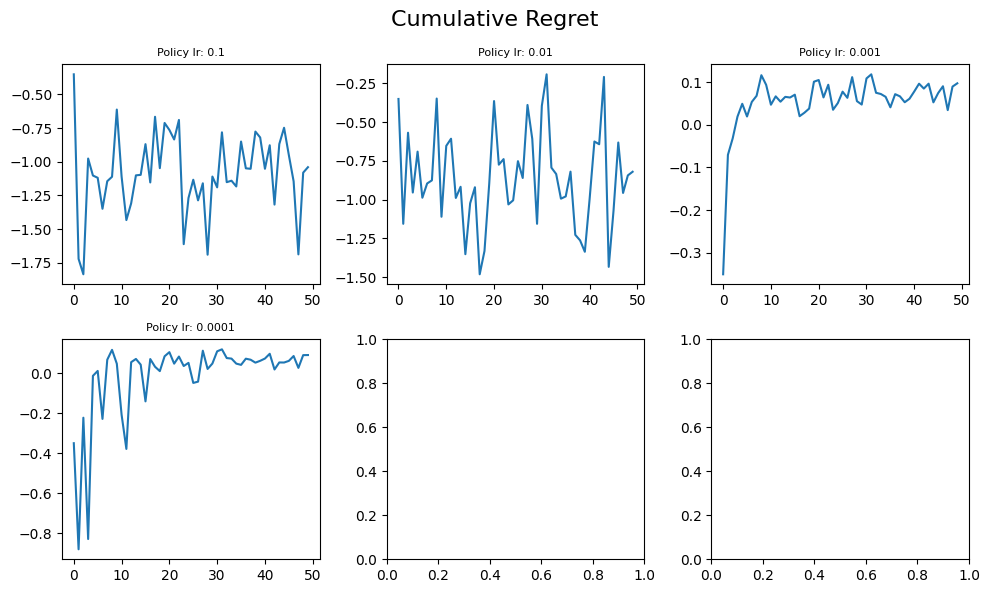

-1.0825688
-0.85738266
0.05506197
-0.017817587


In [ ]:
plot_loss_dict(data_cumul_regrets, "Cumulative Regret")
for key, value in data_cumul_regrets.items():
    print(jnp.mean(jnp.array(value[:50])))

In [ ]:
mech_lr = 1e-5
policy_lr = 1e-5
alpha = 0.5
beta = 1.25
good_mech_tuples = data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}"]
mechanism_params, profit_loss, ir_loss, exploitability = good_mech_tuples[0]
print(f"profit_loss: {profit_loss}, ir_loss: {ir_loss}, exploitability: {exploitability}")

policy_lr_sweep = [1e-1, 1e-2, 1e-3, 1e-4]
num_samples = 32
num_epochs = 1000
num_iters_per_batch = 1
print_iter = 20

# Create Haiku networks
mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
policy_network = hk.without_apply_rng(hk.transform(_policy_network))
# policy_network = build_discrete_policy_net_minimal(
#     proto_strength_init=1.0,   # how strong truthful proto is
#     residual_init_std=0.0,      # 0 => exact truthful start
#     stop_grad_truth=True        # freeze truthful part during training
# )


data_cumul_regrets = {f"Policy lr: {policy_lr}": [] for policy_lr in policy_lr_sweep}
for policy_lr in policy_lr_sweep:
    print(f"==================== Policy lr: {policy_lr} ====================")
    cumul_regrets, policy = maximize_cumul_regret(auction,
                        mechanism_network,
                        mechanism_params,
                        policy_network,
                        num_epochs,
                        num_iters_per_batch,
                        num_samples,
                        policy_lr,
                        print_iter,
                        initial_truthful=False,
                        seed = 1234567
                        )
    data_cumul_regrets[f"Policy lr: {policy_lr}"] = cumul_regrets

profit_loss: -0.5371623039245605, ir_loss: 0.023472707718610764, exploitability: 0.07064928114414215
==================== Policy lr: 0.1 ====================
==================== Epoch 0 ====================
Cumulative Regret: -1.1661953926086426
==================== Epoch 20 ====================
Cumulative Regret: -1.9375522136688232
==================== Epoch 40 ====================
Cumulative Regret: -2.045008659362793
==================== Epoch 60 ====================
Cumulative Regret: -2.022817611694336
==================== Epoch 80 ====================
Cumulative Regret: -1.1954197883605957
==================== Epoch 100 ====================
Cumulative Regret: -1.6906579732894897
==================== Epoch 120 ====================
Cumulative Regret: -1.6487622261047363
==================== Epoch 140 ====================
Cumulative Regret: -2.013154983520508
==================== Epoch 160 ====================
Cumulative Regret: -1.5730006694793701
==================== Epoch 180 =

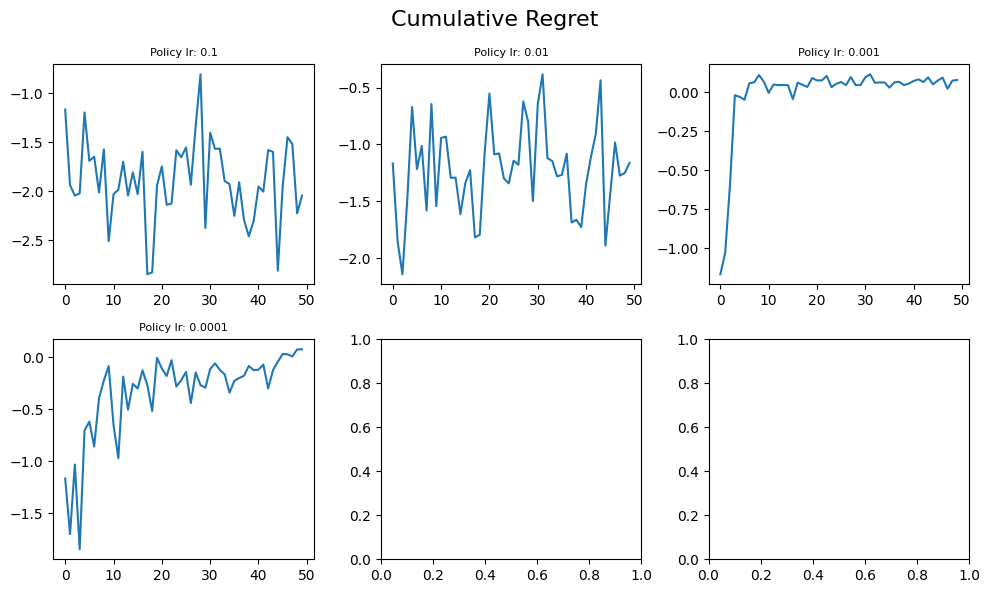

-1.8918359
-1.2201505
-0.003065943
-0.33081657


In [ ]:
plot_loss_dict(data_cumul_regrets, "Cumulative Regret")
for key, value in data_cumul_regrets.items():
    print(jnp.mean(jnp.array(value[:50])))

## Method 2: Nested GDA for Min-Max Method

In [ ]:
import jax
import jax.numpy as jnp
import haiku as hk
import optax


def _make_eval_keys(seed: int, n: int):
    return jax.random.split(jax.random.PRNGKey(seed), n)


# @jax.jit
def _heldout_profit_gap_stats(
    auction,
    mechanism_network,
    mechanism_params,
    profit_goal: float,
    num_samples_eval: int,
    keys,  # shape (K,2)
):
    mechanism = Mechanism(mechanism_network, mechanism_params)

    def one(k):
        prof = AuctionSimulator.estimate_cumulative_profit(
            auction, mechanism, num_samples=num_samples_eval, key=k
        )
        gap = profit_goal - prof
        return prof, gap

    profs, gaps = jax.vmap(one)(keys)
    return {
        "profit_mean": jnp.mean(profs),
        "profit_std": jnp.std(profs),
        "gap_mean": jnp.mean(gaps),
        "gap_std": jnp.std(gaps),
        "gap_plus_mean": jnp.mean(jnp.maximum(0.0, gaps)),
        "abs_gap_mean": jnp.mean(jnp.abs(gaps)),
    }


# @jax.jit
def _heldout_ic_ir_stats(
    auction,
    mechanism_network,
    mechanism_params,
    policy_network,
    policy_params,
    temperature: float,
    num_samples_eval: int,
    keys,
):
    mechanism = Mechanism(mechanism_network, mechanism_params)
    policy = DiffPolicy(policy_network, policy_params, temperature)

    def one(k):
        reg = AuctionSimulator.estimate_cumulative_regret(
            auction, mechanism, policy, num_samples=num_samples_eval, key=k
        )
        ir_vec = AuctionSimulator.estimate_cumulative_rewards(
            auction, mechanism, num_samples=num_samples_eval, key=k
        )
        ir = jnp.sum(jnp.abs(ir_vec))
        return reg, ir

    regs, irs = jax.vmap(one)(keys)
    return {
        "reg_mean": jnp.mean(regs),
        "reg_std": jnp.std(regs),
        "reg_plus_mean": jnp.mean(jnp.maximum(0.0, regs)),
        "ir_mean": jnp.mean(irs),
        "ir_std": jnp.std(irs),
    }


def nested_GD_obj(
    auction: BanditAuction,
    mechanism_network,
    policy_network,
    profit_goal: float,

    # Outer loop (mechanism)
    num_outer_epochs: int = 1000,
    outer_steps_per_epoch: int = 1,
    lr_theta: float = 1e-4,

    # Inner loop (policy oracle / regret maximizer)
    num_inner_steps: int = 200,
    lr_w: float = 3e-4,
    inner_opt_reset_each_outer: bool = False,

    # Monte Carlo (TRAIN)
    num_samples_train: int = 64,

    # Monte Carlo (EVAL / HELDOUT)
    num_samples_eval: int = 256,
    heldout_keys_seed: int = 999,
    heldout_num_keys: int = 16,
    eval_every: int = 50,

    # Loss weights
    alpha: float = 1e5,
    beta: float = 1e3,

    # Gumbel-softmax temperature schedule
    tau0: float = 1.0,
    tau_min: float = 0.1,
    tau_decay: float = 0.005,

    # Diagnostics
    print_iter: int = 50,

    # Early stopping
    early_stop: bool = True,
    tol: float = 0.1,
    patience: int = 10,
):
    prng = hk.PRNGSequence(SEED)

    # -------------------------
    # Init params
    # -------------------------
    key_init = next(prng)
    init_state = auction.get_initial_state(next(prng))
    mechanism_params = mechanism_network.init(
        key_init,
        init_state,
        jnp.zeros((auction.num_buyers, auction.num_goods)),
        auction,
    )

    policy_params = policy_network.init(
        next(prng),
        auction.get_initial_belief_state(init_state),
        auction,
    )

    # -------------------------
    # Optimizers
    # -------------------------
    theta_opt = optax.adam(lr_theta)
    theta_opt_state = theta_opt.init(mechanism_params)

    w_opt = optax.adam(lr_w)
    w_opt_state = w_opt.init(policy_params)

    # -------------------------
    # Held-out eval keys (fixed)
    # -------------------------
    heldout_keys = _make_eval_keys(heldout_keys_seed, heldout_num_keys)

    # -------------------------
    # Temperature schedule
    # -------------------------
    def temperature_schedule(epoch: int):
        return jnp.maximum(tau_min, tau0 * jnp.exp(-tau_decay * epoch))

    # -------------------------
    # TRAIN estimators (jitted)
    # -------------------------
    @jax.jit
    def cumulative_regret_train(mechanism_params, policy_params, key, temperature):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        policy = DiffPolicy(policy_network, policy_params, temperature)
        return AuctionSimulator.estimate_cumulative_regret(
            auction, mechanism, policy, num_samples=num_samples_train, key=key
        )

    # @jax.jit
    # def ir_loss_train(mechanism_params, key):
    #     mechanism = Mechanism(mechanism_network, mechanism_params)
    #     expected_cumul_rewards = AuctionSimulator.estimate_cumulative_rewards(
    #         auction, mechanism, num_samples=num_samples_train*5, key=key
    #     )
    #     return jnp.sum(jnp.abs(expected_cumul_rewards))

    @jax.jit
    def ir_loss_train(mechanism_params, key):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        abs_rewards = AuctionSimulator.estimate_relu_cumulative_rewards(
            auction,
            mechanism,
            num_samples=num_samples_train,
            key=key,
        )
        return jnp.sum(abs_rewards)

    @jax.jit
    def profit_gap_train(mechanism_params, key):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        cumulative_profit = AuctionSimulator.estimate_cumulative_profit(
            auction, mechanism, num_samples=num_samples_train, key=key
        )
        return profit_goal - cumulative_profit  # gap

    # -------------------------
    # Inner loop: approximate argmax_w Regret(theta, w)
    # -------------------------
    @jax.jit
    def inner_step(mechanism_params, policy_params, w_opt_state, key, temperature):
        reg, grad_w = jax.value_and_grad(cumulative_regret_train, argnums=1)(
            mechanism_params, policy_params, key, temperature
        )
        # ascent on w: optax does descent, so negate gradient
        grad_w_ascent = jax.tree_util.tree_map(lambda g: -g, grad_w)
        updates, w_opt_state = w_opt.update(grad_w_ascent, w_opt_state, policy_params)
        policy_params = optax.apply_updates(policy_params, updates)
        return reg, policy_params, w_opt_state

    def maximize_regret_oracle(mechanism_params, policy_params, w_opt_state, temperature, steps: int):
        reg = 0.0
        for _ in range(steps):
            key = next(prng)
            reg, policy_params, w_opt_state = inner_step(
                mechanism_params, policy_params, w_opt_state, key, temperature
            )
        return reg, policy_params, w_opt_state

    # -------------------------
    # Outer loop: update theta using w*(theta)
    #   IMPORTANT: split key so regret/profit/ir don't share randomness
    # -------------------------
    @jax.jit
    def total_loss_with_oracle(mechanism_params, policy_params_star, key, temperature):
        k1, k2, k3 = jax.random.split(key, 3)

        reg = cumulative_regret_train(mechanism_params, policy_params_star, k1, temperature)
        gap = profit_gap_train(mechanism_params, k2)
        ir  = ir_loss_train(mechanism_params, k3)

        # hinge penalties consistent with feasibility-style objective
        reg_plus = jnp.maximum(0.0, reg)
        gap_plus = jnp.maximum(0.0, gap)

        loss = alpha * reg_plus + gap_plus + beta * ir
        return loss, (reg, gap, ir, reg_plus, gap_plus)

    @jax.jit
    def outer_step(mechanism_params, theta_opt_state, policy_params_star, key, temperature):
        (loss, aux), grad_theta = jax.value_and_grad(
            total_loss_with_oracle, argnums=0, has_aux=True
        )(mechanism_params, policy_params_star, key, temperature)
        updates, theta_opt_state = theta_opt.update(grad_theta, theta_opt_state, mechanism_params)
        mechanism_params = optax.apply_updates(mechanism_params, updates)
        return loss, aux, mechanism_params, theta_opt_state

    # -------------------------
    # Logs
    # -------------------------
    logs = {
        "loss": [],
        "reg": [],
        "gap": [],
        "ir": [],
        "reg_plus": [],
        "gap_plus": [],
        "good_mech": [],
        # heldout snapshots
        "heldout_profit_mean": [],
        "heldout_gap_plus_mean": [],
        "heldout_reg_plus_mean": [],
        "heldout_ir_mean": [],
        "heldout_epoch": [],
    }

    sat_count = 0

    # -------------------------
    # Training
    # -------------------------
    for outer_epoch in range(num_outer_epochs):
        temperature = float(temperature_schedule(outer_epoch))

        if inner_opt_reset_each_outer and outer_epoch > 0:
            init_state = auction.get_initial_state(next(prng))
            policy_params = policy_network.init(
                next(prng),
                auction.get_initial_belief_state(init_state),
                auction,
            )
            w_opt_state = w_opt.init(policy_params)

        # --- Inner oracle ---
        reg_star, policy_params, w_opt_state = maximize_regret_oracle(
            mechanism_params, policy_params, w_opt_state, temperature, num_inner_steps
        )
        policy_params_star = policy_params

        # --- Outer update(s) ---
        for _ in range(outer_steps_per_epoch):
            key_outer = next(prng)
            loss, (reg, gap, ir, reg_plus, gap_plus), mechanism_params, theta_opt_state = outer_step(
                mechanism_params, theta_opt_state, policy_params_star, key_outer, temperature
            )

        # to python floats
        loss_val = float(loss)
        reg_val = float(reg)
        gap_val = float(gap)
        ir_val  = float(ir)
        regp_val = float(reg_plus)
        gapp_val = float(gap_plus)

        logs["loss"].append(loss_val)
        logs["reg"].append(reg_val)
        logs["gap"].append(gap_val)
        logs["ir"].append(ir_val)
        logs["reg_plus"].append(regp_val)
        logs["gap_plus"].append(gapp_val)

        # --- Print training diagnostics ---
        if outer_epoch % print_iter == 0:
            print(f"==================== Outer Epoch {outer_epoch} ====================")
            print(f"temperature:        {temperature:.4f}")
            print(f"oracle regret*:     {float(reg_star):.6f}")
            print(f"reg (train):        {reg_val:.6f}   reg_+={regp_val:.6f}")
            print(f"gap (train):        {gap_val:.6f}   gap_+={gapp_val:.6f}")
            print(f"ir (train):         {ir_val:.6f}")
            print(f"total loss:         {loss_val:.6f}")

        # # --- Held-out eval (fixed keys, bigger samples) ---
        # if (eval_every is not None) and (outer_epoch % eval_every == 0):
        #     pstats = _heldout_profit_gap_stats(
        #         auction, mechanism_network, mechanism_params, profit_goal,
        #         num_samples_eval, heldout_keys
        #     )
        #     # for IC/IR held-out, evaluate using CURRENT oracle params and current temp
        #     cstats = _heldout_ic_ir_stats(
        #         auction, mechanism_network, mechanism_params,
        #         policy_network, policy_params_star, temperature,
        #         num_samples_eval, heldout_keys
        #     )

        #     logs["heldout_profit_mean"].append(float(pstats["profit_mean"]))
        #     logs["heldout_gap_plus_mean"].append(float(pstats["gap_plus_mean"]))
        #     logs["heldout_reg_plus_mean"].append(float(cstats["reg_plus_mean"]))
        #     logs["heldout_ir_mean"].append(float(cstats["ir_mean"]))
        #     logs["heldout_epoch"].append(int(outer_epoch))

        #     print("[HELDOUT EVAL]",
        #           f"profit_mean={float(pstats['profit_mean']):.6f}",
        #           f"gap_plus_mean={float(pstats['gap_plus_mean']):.6f}",
        #           f"reg_plus_mean={float(cstats['reg_plus_mean']):.6f}",
        #           f"ir_mean={float(cstats['ir_mean']):.6f}")

        # --- Early stopping (use + parts consistently) ---
        if early_stop:
            ok = (reg_val <= tol) and (ir_val <= tol*10) and (gap_val <= tol)
            sat_count = sat_count + 1 if ok else 0
            if ok:
                logs["good_mech"].append((mechanism_params, policy_params_star, reg_val, ir_val, gap_val))
            if sat_count >= patience:
                print(
                    f"[EARLY STOP] satisfied for {patience} consecutive epochs at outer_epoch={outer_epoch}\n"
                    f"  reg_+={regp_val:.6f}, ir={ir_val:.6f}, gap_+={gapp_val:.6f} (tol={tol})"
                )
                break

    # mechanism = Mechanism(mechanism_network, mechanism_params)
    policy_oracle = DiffPolicy(policy_network, policy_params, float(temperature_schedule(outer_epoch)))
    return logs, mechanism_params, policy_params


### Train

In [ ]:
SEED = 42

# Create Haiku networks
mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
# policy_network = hk.without_apply_rng(hk.transform(_policy_network))
policy_network = build_discrete_policy_net_minimal(
    proto_strength_init=1.0,   # how strong truthful proto is
    residual_init_std=1.0,      # 0 => exact truthful start
    stop_grad_truth=True        # freeze truthful part during training
)
# -------------------------
# 3) Run nested training
# -------------------------
# profit_goal = 6.508866  # <-- set your δ (target profit) here (same meaning as in your draft)
profit_goal = 7.5

logs, trained_mechanism_params, trained_oracle_policy_params = nested_GD_obj(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    profit_goal=profit_goal,

    num_outer_epochs=2000,
    outer_steps_per_epoch=1,
    lr_theta=1e-4,

    num_inner_steps=500,
    lr_w=5e-3,

    num_samples_train=64,
    num_samples_eval=256,
    heldout_num_keys=16,
    eval_every=50,

    alpha=1,
    beta=1,

    tau0=1.0,
    tau_min=0.1,
    tau_decay=0.005,

    print_iter=50,

    early_stop=True,
    tol=0.01,
    patience=10,
)

==================== Outer Epoch 0 ====================
temperature:        1.0000
oracle regret*:     0.766432
reg (train):        0.710564   reg_+=0.710564
gap (train):        3.508153   gap_+=3.508153
ir (train):         0.115605
total loss:         4.334322
==================== Outer Epoch 50 ====================
temperature:        0.7788
oracle regret*:     -0.518187
reg (train):        -0.592751   reg_+=0.000000
gap (train):        -0.208213   gap_+=0.000000
ir (train):         0.220566
total loss:         0.220566
==================== Outer Epoch 100 ====================
temperature:        0.6065
oracle regret*:     -0.579709
reg (train):        -0.502733   reg_+=0.000000
gap (train):        0.022222   gap_+=0.022222
ir (train):         0.130571
total loss:         0.152793
==================== Outer Epoch 150 ====================
temperature:        0.4724
oracle regret*:     -0.585653
reg (train):        -0.519701   reg_+=0.000000
gap (train):        -0.225239   gap_+=0.0000

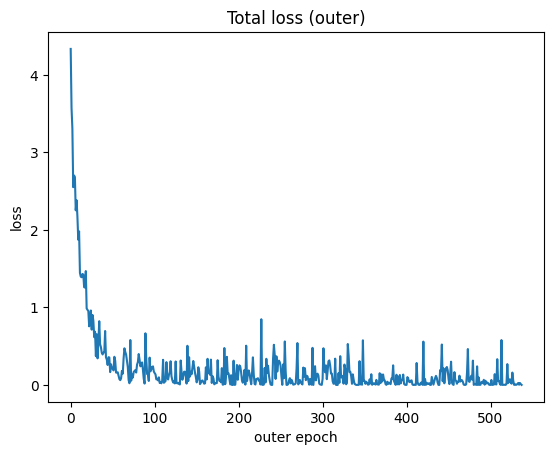

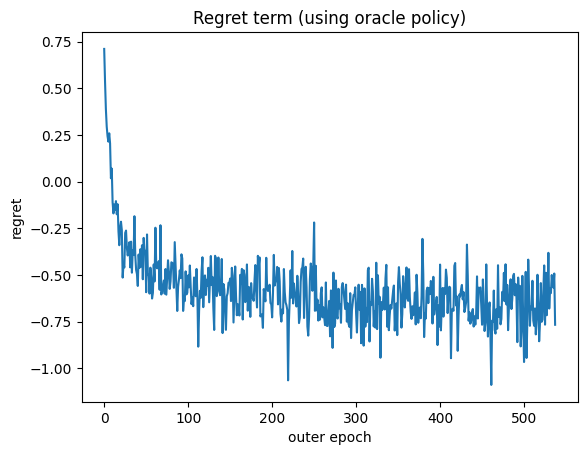

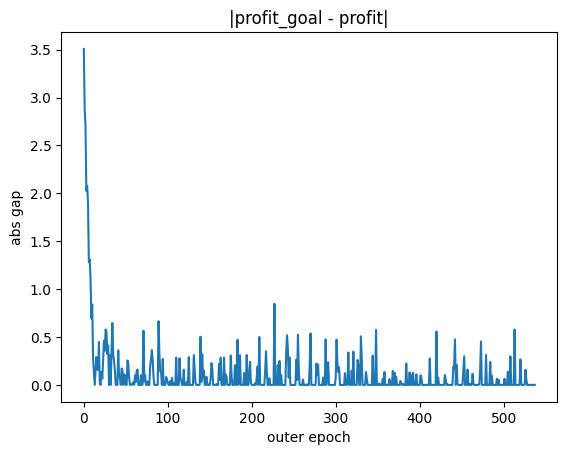

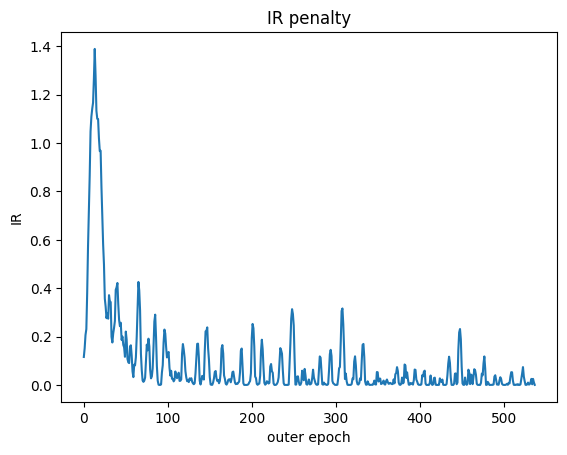

In [ ]:
# -------------------------
# 4) Quick diagnostics after training
# -------------------------
import matplotlib.pyplot as plt

plt.figure()
plt.plot(logs["loss"])
plt.title("Total loss (outer)")
plt.xlabel("outer epoch")
plt.ylabel("loss")
plt.show()

plt.figure()
plt.plot(logs["reg"])
plt.title("Regret term (using oracle policy)")
plt.xlabel("outer epoch")
plt.ylabel("regret")
plt.show()

plt.figure()
plt.plot([jnp.maximum(0.0, x) for x in logs["gap"]])
plt.title("|profit_goal - profit|")
plt.xlabel("outer epoch")
plt.ylabel("abs gap")
plt.show()

plt.figure()
plt.plot(logs["ir"])
plt.title("IR penalty")
plt.xlabel("outer epoch")
plt.ylabel("IR")
plt.show()

In [ ]:
print(len(logs["good_mech"]))

255


In [ ]:
import os, pickle

save_dir = "./_runs/nested/discrete_single_7_5"
os.makedirs(save_dir, exist_ok=True)

logs_path = os.path.join(save_dir, "discrete_single_logs.pkl")
mech_params_path = os.path.join(save_dir, "discrete_single_mech_params.pkl")
policy_params_path = os.path.join(save_dir, "discrete_single_policy_params.pkl")

with open(logs_path, "wb") as f:
    pickle.dump(logs, f)

with open(mech_params_path, "wb") as f:
    pickle.dump(trained_mechanism_params, f)

with open(policy_params_path, "wb") as f:
    pickle.dump(trained_oracle_policy_params, f)

print("Saved:")
print(" ", logs_path)
print(" ", mech_params_path)
print(" ", policy_params_path)

Saved:
  ./_runs/nested/discrete_single_7_5/discrete_single_logs.pkl
  ./_runs/nested/discrete_single_7_5/discrete_single_mech_params.pkl
  ./_runs/nested/discrete_single_7_5/discrete_single_policy_params.pkl


### Test the output mechanism

#### IR: 0.015249730087816715

In [ ]:
all_saved_mech_params = [x[0] for x in logs["good_mech"]]

def select_lowest_ir_discrete(
    auction,
    mechanism_network,
    mech_params_list,
    num_samples: int = 256,
    num_keys: int = 32,
    seed: int = 0,
):
    """
    Discrete + single-item
    IR loss = sum_i |E[U_i]| under truthful reporting
    """

    keys = jax.random.split(jax.random.PRNGKey(seed), num_keys)

    best_idx = None
    best_ir = float("inf")
    all_stats = []

    for i, params in enumerate(mech_params_list):
        mechanism = Mechanism(mechanism_network, params)

        ir_vals = []
        for k in keys:
            rewards = AuctionSimulator.estimate_relu_cumulative_rewards(
                auction=auction,
                mechanism=mechanism,
                num_samples=num_samples,
                key=k,
            )
            ir_vals.append(jnp.sum(rewards))

        ir_vals = jnp.stack(ir_vals)

        stats = {
            "idx": i,
            "ir_mean": float(ir_vals.mean()),
            "ir_std": float(ir_vals.std()),
            "ir_max": float(ir_vals.max()),
            "ir_p95": float(jnp.quantile(ir_vals, 0.95)),
        }
        all_stats.append(stats)

        if stats["ir_mean"] < best_ir:
            best_ir = stats["ir_mean"]
            best_idx = i

    return best_idx, mech_params_list[best_idx], all_stats


best_idx, best_mech_params, ir_stats = select_lowest_ir_discrete(
    auction=auction,
    mechanism_network=mechanism_network,
    mech_params_list=all_saved_mech_params,
    num_samples=256,
    num_keys=32,
    seed=123,
)

print("Best mechanism index:", best_idx)
print("IR stats:", ir_stats[best_idx])
good_mechanism_params, good_oracle_policy_params, reg_val, ir_val, gap_val = logs["good_mech"][best_idx]
print(reg_val, ir_val, gap_val)

Best mechanism index: 66
IR stats: {'idx': 66, 'ir_mean': 0.0, 'ir_std': 0.0, 'ir_max': 0.0, 'ir_p95': 0.0}
-0.572864830493927 0.00017813868180382997 -0.06167125701904297


In [ ]:
low_ir_indices = []
for idx in range(len(all_saved_mech_params)):
    if ir_stats[idx]["ir_mean"] < 0.05:
        low_ir_indices.append(idx)

#### Profit: 7.032876968383789

In [ ]:
import jax
import jax.numpy as jnp
import optax
import haiku as hk

# -----------------------------
# Utilities
# -----------------------------
def _tree_l2_norm(pytree):
    leaves = jax.tree_util.tree_leaves(pytree)
    return float(jnp.sqrt(sum([jnp.sum(x * x) for x in leaves])))

def _stack(xs):
    return jnp.stack([jnp.asarray(x) for x in xs])

def _summary_stats(x: jnp.ndarray):
    return {
        "mean": float(jnp.mean(x)),
        "std": float(jnp.std(x)),
        "min": float(jnp.min(x)),
        "max": float(jnp.max(x)),
        "median": float(jnp.median(x)),
    }

def make_keys(base_seed: int, K: int):
    return jax.random.split(jax.random.PRNGKey(base_seed), K)


# ============================================================
# 1) Unbiased multi-key evaluation for fixed mechanism + (optional) fixed oracle policy
# ============================================================

def eval_mechanism_multikey(
    auction,
    mechanism_network,
    mechanism_params,
    profit_goal: float,
    num_samples: int = 256,
    keys=None,            # list/array of PRNGKeys, shape (K,2)
    base_seed: int = 0,
    K: int = 32,
    # IC evaluation:
    policy_network=None,
    policy_params=None,
    temperature: float = 0.2,
):
    """
    Evaluates:
      - profit (and profit_gap = profit_goal - profit)
      - IR loss = sum_i |U_i|
      - IC loss proxy = regret (and reg_+)

    If policy_network/policy_params are provided, IC regret is computed using that policy.
    Otherwise returns IC fields as None.

    Returns a dict with per-key arrays and summary stats.
    """
    if keys is None:
        keys = make_keys(base_seed, K)

    mechanism = Mechanism(mechanism_network, mechanism_params)
    policy = None
    if (policy_network is not None) and (policy_params is not None):
        policy = DiffPolicy(policy_network, policy_params, temperature)

    profits = []
    gaps = []
    ir_losses = []
    regrets = []

    for k in keys:
        prof = AuctionSimulator.estimate_cumulative_profit(
            auction, mechanism, num_samples=num_samples, key=k
        )
        gap = profit_goal - prof

        rewards = AuctionSimulator.estimate_cumulative_rewards(
            auction, mechanism, num_samples=num_samples, key=k
        )
        ir = jnp.sum(jnp.abs(rewards))

        profits.append(prof)
        gaps.append(gap)
        ir_losses.append(ir)

        if policy is not None:
            reg = AuctionSimulator.estimate_cumulative_regret(
                auction, mechanism, policy, num_samples=num_samples, key=k
            )
            regrets.append(reg)

    profits = _stack(profits)
    gaps = _stack(gaps)
    ir_losses = _stack(ir_losses)

    out = {
        "profit": profits,
        "profit_stats": _summary_stats(profits),
        "gap": gaps,
        "gap_stats": _summary_stats(gaps),
        "gap_plus": jnp.maximum(0.0, gaps),
        "gap_plus_stats": _summary_stats(jnp.maximum(0.0, gaps)),
        "abs_gap": jnp.abs(gaps),
        "abs_gap_stats": _summary_stats(jnp.abs(gaps)),
        "ir_loss": ir_losses,
        "ir_loss_stats": _summary_stats(ir_losses),
        "theta_norm": _tree_l2_norm(mechanism_params),
        "K": int(len(keys)),
        "num_samples": int(num_samples),
    }

    if policy is not None:
        regrets = _stack(regrets)
        out.update({
            "regret": regrets,
            "regret_stats": _summary_stats(regrets),
            "ic_loss": regrets,  # raw proxy (can be negative)
            "ic_plus": jnp.maximum(0.0, regrets),
            "ic_plus_stats": _summary_stats(jnp.maximum(0.0, regrets)),
            "abs_regret": jnp.abs(regrets),
            "abs_regret_stats": _summary_stats(jnp.abs(regrets)),
        })
    else:
        out.update({
            "regret": None,
            "regret_stats": None,
            "ic_plus": None,
            "ic_plus_stats": None,
        })

    return out


# ============================================================
# 2) Strong IC check: multi-restart oracle maximization over LR/steps/seeds,
#    then evaluate regret of the BEST oracle using multiple keys.
# ============================================================

def maximize_regret_oracle_once(
    auction,
    mechanism_network,
    mechanism_params,
    policy_network,
    init_policy_params,
    temperature: float,
    num_samples_inner: int,
    steps: int,
    lr: float,
    key_seed: int,
):
    """
    Runs gradient ASCENT on policy params to maximize cumulative regret for a fixed mechanism.
    Returns:
      - final_policy_params
      - final_regret_estimate (on last step key)
      - trajectory of regrets (python list of floats)
    """
    prng = hk.PRNGSequence(key_seed)
    mechanism = Mechanism(mechanism_network, mechanism_params)

    # optax does descent; we negate gradients for ascent
    opt = optax.adam(lr)
    opt_state = opt.init(init_policy_params)

    def regret_est(policy_params, key):
        policy = DiffPolicy(policy_network, policy_params, temperature)
        return AuctionSimulator.estimate_cumulative_regret(
            auction, mechanism, policy, num_samples=num_samples_inner, key=key
        )

    # jit only the grad step (no non-array args passed in; closure captures objects)
    @jax.jit
    def step_fn(policy_params, opt_state, key):
        reg, grad = jax.value_and_grad(regret_est)(policy_params, key)
        grad_ascent = jax.tree_util.tree_map(lambda g: -g, grad)
        updates, opt_state = opt.update(grad_ascent, opt_state, policy_params)
        policy_params = optax.apply_updates(policy_params, updates)
        return reg, policy_params, opt_state

    regs = []
    policy_params = init_policy_params
    reg_last = 0.0
    for _ in range(steps):
        key = next(prng)
        reg_last, policy_params, opt_state = step_fn(policy_params, opt_state, key)
        regs.append(float(reg_last))

    return policy_params, float(reg_last), regs


def strong_ic_evaluation(
    auction,
    mechanism_network,
    mechanism_params,
    policy_network,
    profit_goal: float,

    # Outer evaluation (unbiased multi-key)
    eval_num_samples: int = 256,
    eval_K: int = 32,
    eval_seed: int = 2026,

    # Oracle search grid
    temperature: float = 0.2,
    num_samples_inner: int = 64,
    steps_grid=(100, 200),
    lr_grid=(1e-4, 3e-4, 1e-3),
    num_restarts: int = 5,
    restart_seeds=(0, 1, 2, 3, 4),  # length >= num_restarts

    # Policy init
    policy_init_seed: int = 777,
):
    """
    1) Evaluates profit_gap and IR unbiasedly with multi-key.
    2) Searches for a high-regret oracle policy via multiple restarts and lr/steps grid.
    3) Evaluates IC regret of the best-found oracle unbiasedly with multi-key.
    """
    # fixed eval keys
    eval_keys = make_keys(eval_seed, eval_K)

    # Initialize a baseline policy params (same init each time unless you want randomness)
    prng_init = hk.PRNGSequence(policy_init_seed)
    init_state = auction.get_initial_state(next(prng_init))
    init_belief = auction.get_initial_belief_state(init_state)
    base_policy_params = policy_network.init(next(prng_init), init_belief, auction)

    # --- Oracle search ---
    best = {
        "policy_params": base_policy_params,
        "reg_last": -1e30,
        "lr": None,
        "steps": None,
        "seed": None,
        "reg_traj": None,
    }

    # choose seeds
    seeds = list(restart_seeds)[:num_restarts] if restart_seeds is not None else list(range(num_restarts))

    for s in seeds:
        # optionally re-init policy each restart with different seed
        prng_r = hk.PRNGSequence(policy_init_seed + 1000 + s)
        init_state_r = auction.get_initial_state(next(prng_r))
        init_belief_r = auction.get_initial_belief_state(init_state_r)
        init_params_r = policy_network.init(next(prng_r), init_belief_r, auction)

        for steps in steps_grid:
            for lr in lr_grid:
                pol, reg_last, reg_traj = maximize_regret_oracle_once(
                    auction=auction,
                    mechanism_network=mechanism_network,
                    mechanism_params=mechanism_params,
                    policy_network=policy_network,
                    init_policy_params=init_params_r,
                    temperature=temperature,
                    num_samples_inner=num_samples_inner,
                    steps=steps,
                    lr=lr,
                    key_seed=10_000 + s * 100 + int(steps) + int(lr * 1e6),
                )
                if reg_last > best["reg_last"]:
                    best.update({
                        "policy_params": pol,
                        "reg_last": reg_last,
                        "lr": lr,
                        "steps": steps,
                        "seed": s,
                        "reg_traj": reg_traj,
                    })

    # --- Unbiased evaluation with best oracle across many keys ---
    eval_out = eval_mechanism_multikey(
        auction=auction,
        mechanism_network=mechanism_network,
        mechanism_params=mechanism_params,
        profit_goal=profit_goal,
        num_samples=eval_num_samples,
        keys=eval_keys,
        policy_network=policy_network,
        policy_params=best["policy_params"],
        temperature=temperature,
    )

    # Attach oracle search info
    eval_out["oracle_search"] = {
        "best_reg_last_step_estimate": best["reg_last"],
        "best_lr": best["lr"],
        "best_steps": best["steps"],
        "best_restart_seed": best["seed"],
        "best_reg_traj_last10": best["reg_traj"][-10:] if best["reg_traj"] is not None else None,
        "inner_num_samples": num_samples_inner,
        "temperature": temperature,
    }

    return eval_out


# ============================================================
# 3) Pretty printer for results
# ============================================================

def print_eval_report(eval_out):
    ps = eval_out["profit_stats"]
    gs = eval_out["gap_stats"]
    gps = eval_out["gap_plus_stats"]
    irs = eval_out["ir_loss_stats"]

    print("===== Mechanism evaluation (multi-key) =====")
    print(f"K keys: {eval_out['K']}, num_samples per key: {eval_out['num_samples']}")
    print(f"theta ||.||_2: {eval_out['theta_norm']:.6f}")
    print("")
    print("[Profit]")
    print("  mean/std/min/max:", ps["mean"], ps["std"], ps["min"], ps["max"])
    print("[Gap = profit_goal - profit]")
    print("  mean/std/min/max:", gs["mean"], gs["std"], gs["min"], gs["max"])
    print("[Gap_+]")
    print("  mean/std/min/max:", gps["mean"], gps["std"], gps["min"], gps["max"])
    print("[IR loss = sum_i |U_i|]")
    print("  mean/std/min/max:", irs["mean"], irs["std"], irs["min"], irs["max"])

    if eval_out.get("regret") is not None:
        rs = eval_out["regret_stats"]
        rps = eval_out["ic_plus_stats"]
        print("")
        print("[IC proxy (regret)]")
        print("  mean/std/min/max:", rs["mean"], rs["std"], rs["min"], rs["max"])
        print("[IC loss = regret_+]")
        print("  mean/std/min/max:", rps["mean"], rps["std"], rps["min"], rps["max"])

    if "oracle_search" in eval_out:
        os = eval_out["oracle_search"]
        print("")
        print("===== Oracle robustness check =====")
        print("Best inner-run last-step regret estimate:", os["best_reg_last_step_estimate"])
        print("Best (lr, steps, restart_seed):", os["best_lr"], os["best_steps"], os["best_restart_seed"])
        print("Inner num_samples:", os["inner_num_samples"], "temperature:", os["temperature"])
        print("Last 10 regrets during best inner run:", os["best_reg_traj_last10"])

In [ ]:
good_mech_params = all_saved_mech_params[best_idx]

In [ ]:
keys = make_keys(2026, 32)

out = eval_mechanism_multikey(
    auction=auction,
    mechanism_network=mechanism_network,
    mechanism_params=good_mechanism_params,   # <-- your trained theta
    profit_goal=profit_goal,
    num_samples=256,
    keys=keys,
    policy_network=policy_network,
    policy_params=good_oracle_policy_params,
    temperature=0.2,
)

print_eval_report(out)

===== Mechanism evaluation (multi-key) =====
K keys: 32, num_samples per key: 256
theta ||.||_2: 25.978048

[Profit]
  mean/std/min/max: 7.374680519104004 0.10117297619581223 7.13615608215332 7.663164138793945
[Gap = profit_goal - profit]
  mean/std/min/max: 0.12531957030296326 0.10117297619581223 -0.1631641387939453 0.3638439178466797
[Gap_+]
  mean/std/min/max: 0.13405831158161163 0.08255261927843094 0.0 0.3638439178466797
[IR loss = sum_i |U_i|]
  mean/std/min/max: 0.36327266693115234 0.008467630483210087 0.34815478324890137 0.38649892807006836

[IC proxy (regret)]
  mean/std/min/max: -0.15600620210170746 0.00523402402177453 -0.16726192831993103 -0.14694157242774963
[IC loss = regret_+]
  mean/std/min/max: 0.0 0.0 0.0 0.0


In [ ]:
keys = make_keys(2026, 32)

highest_profit = 0.0
highest_idx = -1
highest_prof_std = 0.0
for i in range(len(low_ir_indices)):
    idx = low_ir_indices[i]
    if i % 10 == 0:
        print(f"{i}/{len(low_ir_indices)}......")
    out = eval_mechanism_multikey(
        auction=auction,
        mechanism_network=mechanism_network,
        mechanism_params=all_saved_mech_params[idx],
        profit_goal=profit_goal,
        num_samples=256,
        keys=keys,
        policy_network=policy_network,
        policy_params=good_oracle_policy_params,
        temperature=0.2,
    )
    if out["profit_stats"]["max"] > highest_profit:
        highest_profit = out["profit_stats"]["mean"] > highest_profit
        highest_profit = out["profit_stats"]["mean"]
        highest_idx = idx
        higest_prof_std = out["profit_stats"]["std"]

print(highest_profit, highest_prof_std)
print(ir_stats[highest_idx]["ir_mean"], ir_stats[highest_idx]["ir_std"])

print(out["profit_stats"]["std"], out["profit_stats"]["std"])
print(ir_stats[highest_idx]["ir_mean"], ir_stats[highest_idx]["ir_std"])

0/223......
10/223......
20/223......
30/223......
40/223......
50/223......
60/223......
70/223......
80/223......
90/223......
100/223......
110/223......
120/223......
130/223......
140/223......
150/223......
160/223......
170/223......
180/223......
190/223......
200/223......
210/223......
220/223......
7.583173751831055 0.0
2.826609488693066e-05 3.430191645747982e-05
0.107141874730587 0.107141874730587
2.826609488693066e-05 3.430191645747982e-05


#### IC: 0.024281515

In [ ]:
good_mech_params = all_saved_mech_params[highest_idx]

In [ ]:
import random
policy_lr_sweep = [1e-3, 5e-4, 1e-4]
num_samples = 32
num_epochs = 1000
num_iters_per_batch = 1
print_iter = 10

# Create Haiku networks
mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
# policy_network = hk.without_apply_rng(hk.transform(_policy_network))
policy_network = build_discrete_policy_net_minimal(
    proto_strength_init=1.0,   # how strong truthful proto is
    residual_init_std=1.0,      # 0 => exact truthful start
    stop_grad_truth=True        # freeze truthful part during training
)


# Generate 30 random seeds
random_seeds = [random.getrandbits(32) for _ in range(10)]
exploitabilities = []
for random_seed in random_seeds:
  # data_cumul_regrets = {f"Policy lr: {policy_lr}": [] for policy_lr in policy_lr_sweep}
  highest_exploitability = -1e5
  for policy_lr in policy_lr_sweep:
      print(f"==================== Policy lr: {policy_lr} ====================")
      cumul_regrets, policy = maximize_cumul_regret(auction,
                          mechanism_network,
                          good_mechanism_params,
                          policy_network,
                          num_epochs,
                          num_iters_per_batch,
                          num_samples,
                          policy_lr,
                          print_iter,
                          initial_truthful=False,
                          seed = random_seed
                          )
      avg_exploit = jnp.mean(jnp.array(cumul_regrets[-5:]))
      print(f"avg_exploit: {avg_exploit}")
      if avg_exploit > highest_exploitability:
          highest_exploitability = avg_exploit
  print(f"Exploitability: {highest_exploitability}")
  exploitabilities.append(highest_exploitability)

Streaming output truncated to the last 5000 lines.
==================== Epoch 290 ====================
Cumulative Regret: 0.8697134256362915
==================== Epoch 300 ====================
Cumulative Regret: 0.8713792562484741
==================== Epoch 310 ====================
Cumulative Regret: 0.8977782726287842
==================== Epoch 320 ====================
Cumulative Regret: 0.8616324663162231
==================== Epoch 330 ====================
Cumulative Regret: 0.9154906868934631
==================== Epoch 340 ====================
Cumulative Regret: 0.9223424196243286
==================== Epoch 350 ====================
Cumulative Regret: 0.8429518342018127
==================== Epoch 360 ====================
Cumulative Regret: 0.8236797451972961
==================== Epoch 370 ====================
Cumulative Regret: 0.8968467712402344
==================== Epoch 380 ====================
Cumulative Regret: 0.884526252746582
==================== Epoch 390 ===================

In [ ]:
print(jnp.mean(jnp.array(exploitabilities)))
print(jnp.std(jnp.array(exploitabilities)))

0.87569743
0.02533593


## Method 3: Penalty

# Benchmark: Index Policy for One Good

## Compute Indices

In [ ]:
def compute_indices(auction: BanditAuction, state: State, hazard_rates: jnp.ndarray, num_samples: int, key: jax.random.PRNGKey):
    virtual_indices = []
    current_time_step = state.time_step
    keys = jax.random.split(key, num=num_samples)
    # print(f"Computing index for state...")
    for buyer in jnp.arange(auction.num_buyers):
        # Find the optimal stopping time
        values = {}
        for stopping_time in range(current_time_step, auction.num_horizons):
          # Initiate an empty list a store values for stopping_time
          values[stopping_time] = []
          # Similuate the process num_samples times to estimate the expected value
          for key in keys:
            numerator = 0.0
            denominator = 0.0
            for tau in range(current_time_step, stopping_time + 1):
                current_type = state.current_type.flatten()
                allocation_cost = auction.allocation_cost.flatten()
                numerator += auction.discount ** tau * (current_type[buyer] - allocation_cost[buyer] - 1/hazard_rates[buyer])
                denominator += auction.discount ** tau
                # Report is truthful
                report = state.current_type
                # Allocate to buyer i
                allocation = jnp.zeros((auction.num_buyers, auction.num_goods))
                allocation = jax.lax.dynamic_update_index_in_dim(allocation, jnp.array([1.0]), buyer, axis=0)
                # Move to the next state
                state = auction.get_next_state(state, report, allocation, key)
            values[stopping_time].append(numerator/denominator)
        # Find the optimal value
        optimal_value = max([jnp.sum(jnp.array(ls)) for ls in values.values()])
        virtual_indices.append(optimal_value)
    return jnp.array(virtual_indices)

In [ ]:
prng = hk.PRNGSequence(SEED)
initial_states_list = []
for profile in auction.type_profiles:
    initial_state = State(
        time_step=0,
        allocation_history=jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods)),
        current_type=profile,
        report_history=jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods))
    )
    initial_states_list.append(initial_state)

harzard_rate_list = [compute_hazard_rates(auction, initial_state) for initial_state in initial_states_list]

index_dict = {}
for profile in auction.type_profiles:
    for time_step in range(auction.num_horizons):
        for harzard_rate in harzard_rate_list:
            print(f"Computing index for profile: {profile}, time_step: {time_step}, harzard_rate: {harzard_rate}")
            state = State(
                time_step=time_step,
                allocation_history=jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods)),
                current_type=profile,
                report_history=jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods))
            )
            index = compute_indices(auction, state, harzard_rate, 20, next(prng))
            key = (tuple(profile.flatten().tolist()), time_step, tuple(harzard_rate.flatten().tolist()))
            index_dict[key] = index
            print(f"profile: {profile}, time_step: {time_step}, harzard_rate: {harzard_rate}, index: {index}")

Computing index for profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.50000006 0.50000006]
profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.50000006 0.50000006], index: [-20.999996 -21.999996]
Computing index for profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.50000006 1.0000001 ]
profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.50000006 1.0000001 ], index: [14.000009 -1.999998]
Computing index for profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.50000006        inf]
profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.50000006        inf], index: [-2.9999948 17.999996 ]
Computing index for profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [1.0000001  0.50000006]
profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [1.0000001  0.50000006], index: [  5.000002 -21.999996]
Computing index for profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [1.0000001 1.0000001]
profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [1.0000001 1.0000001], index: [23.       -1.999998

In [ ]:
# Create the directory if it doesn't exist
save_dir = "data"
os.makedirs(save_dir, exist_ok=True)

# Define the filename
filename = os.path.join(save_dir, "index_dict.pkl")

# Save the dictionary using pickle
with open(filename, 'wb') as f:
    pickle.dump(index_dict, f)

print(f"Data saved to {filename}")

Data saved to data/index_dict.pkl


In [ ]:
# Define the filename
save_dir = "data"
filename = os.path.join(save_dir, "index_dict.pkl")

# Load the dictionary using pickle
try:
    with open(filename, 'rb') as f:
        index_dict = pickle.load(f)
    print(f"Data loaded successfully from {filename}")
except FileNotFoundError:
    print(f"File not found: {filename}. Please ensure the file exists in the '{save_dir}' directory.")
except Exception as e:
    print(f"An error occurred while loading the file: {e}")


Data loaded successfully from data/index_dict.pkl


In [ ]:
for key, value in index_dict.items():
    print(key, value)

((1.0, 1.0), 0, (0.5000000596046448, 0.5000000596046448)) [-20.999996 -21.999996]
((1.0, 1.0), 0, (0.5000000596046448, 1.0000001192092896)) [14.000009 -1.999998]
((1.0, 1.0), 0, (0.5000000596046448, inf)) [-2.9999948 17.999996 ]
((1.0, 1.0), 0, (1.0000001192092896, 0.5000000596046448)) [  5.000002 -21.999996]
((1.0, 1.0), 0, (1.0000001192092896, 1.0000001192092896)) [23.       -1.999998]
((1.0, 1.0), 0, (1.0000001192092896, inf)) [1.9073486e-06 1.7999996e+01]
((1.0, 1.0), 0, (inf, 0.5000000596046448)) [ 32.999996 -21.999996]
((1.0, 1.0), 0, (inf, 1.0000001192092896)) [26.999998 -1.999998]
((1.0, 1.0), 0, (inf, inf)) [58.00001  17.999996]
((1.0, 1.0), 1, (0.5000000596046448, 0.5000000596046448)) [  6.000008 -21.999994]
((1.0, 1.0), 1, (0.5000000596046448, 1.0000001192092896)) [13.00001   -1.9999981]
((1.0, 1.0), 1, (0.5000000596046448, inf)) [13.00001  17.999996]
((1.0, 1.0), 1, (1.0000001192092896, 0.5000000596046448)) [ 35.000004 -21.999994]
((1.0, 1.0), 1, (1.0000001192092896, 1.0000

### Compute Indices for Auction2

In [ ]:
prng = hk.PRNGSequence(SEED)
initial_states_list = []
for profile in auction_2.type_profiles:
    initial_state = State(
        time_step=0,
        allocation_history=jnp.zeros((auction_2.num_horizons, auction_2.num_buyers, auction_2.num_goods)),
        current_type=profile,
        report_history=jnp.zeros((auction_2.num_horizons, auction_2.num_buyers, auction_2.num_goods))
    )
    initial_states_list.append(initial_state)

harzard_rate_list = [compute_hazard_rates(auction_2, initial_state) for initial_state in initial_states_list]

index_dict_2 = {}
for profile in auction_2.type_profiles:
    for time_step in range(auction_2.num_horizons):
        for harzard_rate in harzard_rate_list:
            print(f"Computing index for profile: {profile}, time_step: {time_step}, harzard_rate: {harzard_rate}")
            state = State(
                time_step=time_step,
                allocation_history=jnp.zeros((auction_2.num_horizons, auction_2.num_buyers, auction_2.num_goods)),
                current_type=profile,
                report_history=jnp.zeros((auction_2.num_horizons, auction_2.num_buyers, auction_2.num_goods))
            )
            index = compute_indices(auction_2, state, harzard_rate, 20, next(prng))
            key = (tuple(profile.flatten().tolist()), time_step, tuple(harzard_rate.flatten().tolist()))
            index_dict_2[key] = index
            print(f"profile: {profile}, time_step: {time_step}, harzard_rate: {harzard_rate}, index: {index}")

Computing index for profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.11111111 0.11111111]
profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.11111111 0.11111111], index: [-128.66498 -162.00002]
Computing index for profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.11111111 0.125     ]
profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.11111111 0.125     ], index: [-141.66599 -141.99998]
Computing index for profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.11111111 0.14285713]
profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.11111111 0.14285713], index: [-127.66598 -121.99998]
Computing index for profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.11111111 0.16666667]
profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.11111111 0.16666667], index: [-154.33499 -101.99998]
Computing index for profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.11111111 0.19999999]
profile: [[1.]
 [1.]], time_step: 0, harzard_rate: [0.11111111 0.19999999], index: [-126.66698   

KeyboardInterrupt: 

In [ ]:
# Create the directory if it doesn't exist
save_dir = "data"
os.makedirs(save_dir, exist_ok=True)

# Define the filename
filename = os.path.join(save_dir, "index_dict_2.pkl")

# Save the dictionary using pickle
with open(filename, 'wb') as f:
    pickle.dump(index_dict_2, f)

print(f"Data saved to {filename}")

## New Compute Payment

In [ ]:
def compute_alloc(auction: BanditAuction, state: State, index_dict: dict, hazard_rates: jnp.ndarray):
    profile = state.current_type
    time_step = state.time_step
    dict_key = (tuple(profile.flatten().tolist()), time_step, tuple(hazard_rates.flatten().tolist()))
    virtual_indices = index_dict[dict_key]
    virtual_indices = jnp.concatenate([virtual_indices, jnp.array([0.0])])
    allocated_buyer = jnp.argmax(virtual_indices)
    allocation = jnp.zeros((auction.num_buyers, auction.num_goods))
    if allocated_buyer < auction.num_buyers:
        allocation = jax.lax.dynamic_update_index_in_dim(allocation, jnp.array([1.0]), allocated_buyer, axis=0)

    return allocated_buyer, allocation

def estimate_D_it(auction: BanditAuction, hazard_rates: jnp.ndarray, last_state: State, last_alloc: jnp.ndarray, buyer: int, buyer_type: jnp.ndarray, index_dict: dict, num_samples: int, key: jax.random.PRNGKey):
    total_D_list = []
    keys = jax.random.split(key, num=num_samples)
    for key in keys:
        total_D = 0.0
        if last_state is None:
            state = auction.get_initial_state(key)
        else:
            state = auction.get_next_state(last_state, last_state.current_type, last_alloc, key)
        state = state.replace_buyer_type(buyer, buyer_type)
        for t in range(state.time_step, auction.num_horizons):
            ##### Compute allocation
            allocated_buyer, allocation = compute_alloc(auction, state, index_dict, hazard_rates)
            x_it = float(allocated_buyer == buyer)
            total_D += x_it * auction.discount ** t
            state = auction.get_next_state(state, state.current_type, allocation, key)

        total_D_list.append(total_D)
    return jnp.mean(jnp.array(total_D_list))

def compute_Q_it(auction: BanditAuction, buyer: int, buyer_type: jnp.ndarray, D_it: jnp.ndarray):
    Q_it = 0.0
    current_type_index = jnp.where(auction.buyer_types[buyer] == buyer_type)[0][0]
    if current_type_index == 0:
        return 0.0
    else:
        for type_index in range(current_type_index):
            Q_it += (D_it[type_index] + D_it[type_index+1])/2 * (auction.buyer_types[buyer][type_index][0] - auction.buyer_types[buyer][type_index+1][0])
    return Q_it




def new_compute_payment(auction: BanditAuction, state: State, last_state: State, last_alloc: jnp.ndarray, hazard_rates: jnp.ndarray, index_dict: dict, key: jax.random.PRNGKey, num_samples: int):
    # Compute D_it(\theta_it) for each buyer, each type
    D_t = np.zeros((auction.num_buyers, auction.num_types))
    for buyer in range(auction.num_buyers):
        for type_index in range(auction.num_types):
            buyer_type = auction.buyer_types[buyer][type_index]
            D_t[buyer][type_index] = estimate_D_it(auction, hazard_rates, last_state, last_alloc, buyer, buyer_type, index_dict, 10, key)
            # print(f"D_{buyer}{state.time_step}({buyer_type})={D_t[buyer][type_index]}")
    # Compute Q_it(\theta_it) for each buyer
    Q_t = np.zeros(auction.num_buyers)
    for buyer in range(auction.num_buyers):
        Q_t[buyer] = compute_Q_it(auction, buyer, state.current_type[buyer], D_t[buyer])
        # print(f"Q_{buyer}{state.time_step}({buyer_type})={Q_t[buyer]}")

    # Compute expected Q_it+1(\theta') and u_it(\theta') for each buyer
    Q_t1 = []
    u_t = []
    keys = jax.random.split(key, num=num_samples)
    for buyer in range(auction.num_buyers):
        Q_t1_buyer = []
        u_t_buyer = []
        for key in keys:
            D_t1 = np.zeros((auction.num_types))
            # Sample \theta_t' (but with fixed \theta_it) and x_t'
            if last_state is None:
                state_prime = auction.get_initial_state(key)
            else:
                state_prime = auction.get_next_state(last_state, last_state.current_type, last_alloc, key)
            # \theta_t'
            state_prime = state_prime.replace_buyer_type(buyer, state.current_type[buyer])
            # x_t'
            allocated_buyer_prime, alloc_prime = compute_alloc(auction, state_prime, index_dict, hazard_rates)
            # For each \theta_it+1, compute D_it+1(\theta_t', \theta_it+1)
            for type_index in range(auction.num_types):
                buyer_type = auction.buyer_types[buyer][type_index]
                D_t1[type_index] = estimate_D_it(auction, hazard_rates, state_prime, alloc_prime, buyer, buyer_type, index_dict, 10, key)
            next_state = auction.get_next_state(state_prime, state_prime.current_type, alloc_prime, key)
            # Compute Q_it+1(\theta_t', \theta_it+1)
            Q_t1_buyer.append(compute_Q_it(auction, buyer, next_state.current_type[buyer], D_t1))
            # Compute u_it(\theta_t', x_t')
            u_t_buyer.append(state_prime.current_type[buyer] * alloc_prime[buyer])
        Q_t1.append(jnp.mean(jnp.array(Q_t1_buyer)))
        # print(f"Q_{buyer}{state.time_step+1}(theta_it+1')={Q_t1[buyer]}")
        u_t.append(jnp.mean(jnp.array(u_t_buyer)))
        # print(f"u_{buyer}{state.time_step}(theta_it')={u_t[buyer]}")
    # Compute payment
    payment = np.zeros(auction.num_buyers)
    for buyer in range(auction.num_buyers):
        payment[buyer] = auction.discount ** (-1 * state.time_step) *Q_t[buyer] - auction.discount ** (-1 * state.time_step) * Q_t1[buyer] - u_t[buyer]
    return payment





In [ ]:
key = jax.random.PRNGKey(42)
last_state = auction.get_initial_state(key)
last_alloc = jnp.zeros((auction_2.num_buyers, auction_2.num_goods))
hazard_rates = compute_hazard_rates(auction, last_state)
state = auction.get_next_state(last_state, last_state.current_type, last_alloc, key)
payment = new_compute_payment(auction, state, last_state, last_alloc, hazard_rates, index_dict, key, 10)
print(payment)

D_01([1.])=1.3786200284957886
D_01([2.])=1.5171300172805786
D_01([3.])=2.1587398052215576
D_11([1.])=0.0
D_11([2.])=0.0
D_11([3.])=2.217059850692749
Q_01([3.])=-1.4478750228881836
Q_11([3.])=0.0
Q_02(theta_it+1')=-1.3301414251327515
u_01(theta_it')=0.0
Q_12(theta_it+1')=0.0
u_11(theta_it')=0.0
[-0.13081503  0.        ]


## Compute Payment

<!-- 1. Weight selection at $t=0$
Given the reported $s_{i0}$, fix  
$$
\alpha_i,\qquad \beta_i(\cdot)
$$
by  
$$
\alpha_i(s_{i0})=
\begin{cases}
1-\dfrac{1-F_i(s_{i0})}{f_i(s_{i0})}\dfrac{A_i'(s_{i0})}{A_i(s_{i0})}, & \text{multiplicative},\\[8pt]
1, & \text{additive},
\end{cases}
\qquad
\beta_i(a)=
\begin{cases}
0, & \text{multiplicative},\\[8pt]
-\dfrac{1-F_i(s_{i0})}{f_i(s_{i0})}A_i'(s_{i0})\,C_{it}(a), & \text{additive}.
\end{cases}
$$

---

2. Weighted‑social‑welfare value function
For any post‑period‑0 state $s_t$,
$$
W(s_t)=\max_{a\in\mathcal A_t}
\Bigl\{
g_t(a,s_t)+\gamma\,\mathbb E\!\bigl[\,W(s_{t+1})\mid s_t,a\bigr]
\Bigr\},
$$
where  
$$
g_t(a,s_t)=\sum_{k=1}^{n}\bigl[\alpha_k v_{kt}(a,s_t)+\beta_k(a)\bigr]-c_t(a).
$$
The allocation rule is  
$$
a_t^\star(s_t)\in\arg\max_{a} \Bigl\{\,g_t(a,s_t)+\gamma\mathbb E[W(s_{t+1})\mid s_t,a]\Bigr\}.
$$

To solve for $a_t^\star$ for all $t$, should we solve for the optimal allocation policy?

---

3. Buyer continuation value
For type $s$, buyer $i$’s gross discounted value is  
$$
V_i(s)=
\mathbb E\!\Bigl[
\sum_{t=0}^{\infty}\gamma^{t}v_{it}\bigl(a_t^\star,S_t\bigr)
\bigm|\,s_{i0}=s
\Bigr].
$$

---

4. Up‑front information‑rent
With lowest signal $\underline s$ normalised to zero utility,  
$$
p_i^{\star}(s)=
V_i(s)-
\int_{\underline s}^{s} V_i'(z)\,dz.
$$
If $s_{i0}$ is discrete with support $s^{(1)}<\dots<s^{(K)}$,  
$$
p_i^{\star}\!\bigl(s^{(k)}\bigr)=
V_i\!\bigl(s^{(k)}\bigr)-
\sum_{\ell=1}^{k}\bigl[V_i(s^{(\ell)})-V_i(s^{(\ell-1)})\bigr].
$$
and
$$
p_{i,0}(\hat{s}_0) = p_i^{\star}(\hat{s}_0) - \mathbb{E}\Big[
  \sum_{t=1}^\infty \delta^t p_{i,t}(s_i^t) \mid s_0 =  \hat{s}_0
  \Big]
$$

---

5. Dynamic pivot payments
**(a) Value without buyer $i$**  
$$
m_{i,t}=g(a^*_t,\hat{s}_t)
-
(W_{-i}(a^*_{t-1},\hat{s}_t) - \delta \mathbb{E}[W_{-i}(a^*_{-i,t},s_{t+1}) \mid s^t=\hat{s}^t]
)
$$

**(c) Period‑$t$ transfer**  
$$
p_{it}=v_{it}\!\bigl(a_t^\star,s_t\bigr)-\dfrac{m_{i,t}}{\alpha_i}.
$$ -->


In [ ]:
def get_all_alloc_histories(auction: BanditAuction, time_step: int):
    if time_step == 0:
        return [jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods))]
    else:
      alloc_histories = []
      # enumerate all the possible allocation history at time_step
      alloc_combinations = itertools.product(auction.allocation_profiles, repeat=time_step)
      for comb_hist in alloc_combinations:
          remaining_hist = jnp.zeros((auction.num_horizons-time_step, auction.num_buyers, auction.num_goods))
          total_hist = jnp.concatenate([jnp.array(comb_hist), remaining_hist], axis=0)
          alloc_histories.append(total_hist)
      return alloc_histories


def compute_stage_weighted_welfare(auction: BanditAuction, state: State, hazard_rates: jnp.ndarray, allocation: jnp.ndarray):
    return jnp.sum((state.current_type - 1/hazard_rates - auction.allocation_cost) * allocation)

In [ ]:
def compute_optimal_allocation(auction: BanditAuction, hazard_rates: jnp.ndarray):
    # Compute the optimal allocation policy that maximizes the weighted welfare using backward induction
    vfunc = {}
    opt_policy = {}
    default_report_history = jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods))
    for t in reversed(range(auction.num_horizons)):
        print(f"\t\tComputing optimal allocation at time step {t}")
        alloc_histories = get_all_alloc_histories(auction, t)
        # Iterate all the possible states
        for type_profile in auction.type_profiles:
            for alloc_history in alloc_histories:
                # The state at time step t
                state = State(t, alloc_history, type_profile, default_report_history)
                if t == auction.num_horizons - 1:
                    opt_allocation = jnp.zeros((auction.num_buyers, auction.num_goods))
                    opt_qfunc = -jnp.inf
                    for allocation in auction.allocation_profiles:
                        qfunc = compute_stage_weighted_welfare(auction, state, hazard_rates, allocation)
                        if qfunc > opt_qfunc:
                            opt_qfunc = qfunc
                            opt_allocation = allocation
                    vfunc[state] = opt_qfunc
                    opt_policy[state] = opt_allocation
                else:
                    opt_allocation = jnp.zeros((auction.num_buyers, auction.num_goods))
                    opt_qfunc = -jnp.inf
                    # Iterate all the possible allocations
                    for allocation in auction.allocation_profiles:
                        qfunc = compute_stage_weighted_welfare(auction, state, hazard_rates, allocation)
                        # Iterate all the s'
                        for next_type_profile in auction.type_profiles:
                            next_alloc_history = alloc_history.at[t].set(allocation)
                            next_state = State(t+1, next_alloc_history, next_type_profile, default_report_history)
                            qfunc += auction.get_transition_prob(auction, t, type_profile, alloc_history, next_type_profile) * vfunc[next_state]
                        # print(f"q({t}+{type_profile}+{alloc_history}, {allocation})={qfunc}")
                        # Update the optimal allocation if the current allocation is better
                        if qfunc > opt_qfunc:
                            opt_qfunc = qfunc
                            opt_allocation = allocation
                    vfunc[state] = opt_qfunc
                    opt_policy[state] = opt_allocation
    return opt_policy, vfunc




# @jax.jit
# def simulate_V_i(auction: BanditAuction, buyer: int, state: State, belief_state: BeliefState, hazard_rates: jnp.ndarray, opt_policy, key: jax.random.PRNGKey):
#     discount = auction.discount
#     init_cumul_rewards = jnp.repeat(0.0, repeats = auction.num_buyers)
#     init_state = (state, belief_state)
#     init_val  = (init_cumul_rewards, init_state, key)

#     @jax.jit
#     def episode_step(episode_num, episode_state):
#         cumul_reward, (state, belief_state), key = episode_state
#         key1, key2 = jax.random.split(key)
#         report = jnp.zeros((auction.num_buyers, auction.num_goods))
#         allocation = opt_policy[state]
#         reward = state.current_type[buyer][0] * allocation[buyer]
#         cumul_reward += (discount**episode_num)*reward
#         next_state = AuctionSimulator.step(auction, state, belief_state, report, allocation, key)

#         return (cumul_reward, next_state, key)

#     cumul_reward, state, key = jax.lax.fori_loop(0, auction.num_horizons, episode_step, init_val)

# @jax.jit
def simulate_V_i(auction: BanditAuction, buyer: int, state: State, belief_state: BeliefState, hazard_rates: jnp.ndarray, opt_policy, key: jax.random.PRNGKey):
    discount = auction.discount
    cumul_reward = 0.0
    current_state = state
    # current_belief_state = belief_state
    current_key = key

    for episode_num in range(auction.num_horizons):
        current_key, _ = jax.random.split(current_key)
        report = jnp.zeros((auction.num_buyers, auction.num_goods))
        allocation = opt_policy[current_state]
        reward = current_state.current_type[buyer][0] * allocation[buyer]
        cumul_reward += (discount**episode_num) * reward
        next_state = auction.get_next_state(state, report, allocation, current_key)
        current_state = next_state
        # current_belief_state = next_belief_state
    return cumul_reward

# def estimate_V_i(auction: BanditAuction, buyer:int, buyer_initial_type: float, hazard_rates, num_samples, opt_policy, key: jax.random.PRNGKey):
#     key1, key2 = jax.random.split(key)
#     keys = jax.random.split(key1, num=num_samples)
#     init_state_samples = jax.vmap(lambda key: auction.get_initial_state(key).replace_buyer_type(buyer, buyer_initial_type))(keys)
#     belief_state = auction.get_initial_belief_state()

#     def value_fn(state):
#         state = state.replace_buyer_type(buyer, buyer_initial_type)
#         return simulate_V_i(auction, buyer, state, belief_state, hazard_rates, opt_policy, key2)

#     V_i_samples = jax.vmap(value_fn)(init_state_samples)
#     mean_V_i = jnp.mean(V_i_samples, axis=0)
#     return mean_V_i

def estimate_V_i(auction: BanditAuction, buyer:int, buyer_initial_type: float, hazard_rates, num_samples, opt_policy, key: jax.random.PRNGKey):
    keys = jax.random.split(key)
    V_i_samples = []
    for key in keys:
        state = auction.get_initial_state(key)
        state = state.replace_buyer_type(buyer, buyer_initial_type)
        belief_state = auction.get_initial_belief_state(state)
        V_i_samples.append(simulate_V_i(auction, buyer, state, belief_state, hazard_rates, opt_policy, key))
    print(f"V_{buyer}({buyer_initial_type})={jnp.mean(jnp.array(V_i_samples))}")
    return jnp.mean(jnp.array(V_i_samples))

In [ ]:
def compute_tail_prob(auction: BanditAuction, type_index:int):
    return ((auction.num_types - type_index)/auction.num_types) / (1/auction.num_types)

def compute_p_stars(auction: BanditAuction, initial_report: jnp.ndarray, hazard_rates: jnp.ndarray, opt_policy, num_samples: int, key: jax.random.PRNGKey):
    p_stars = []
    for buyer in range(auction.num_buyers):
        # Find the index of initial_report[buyer] in buyer_types[buyer]
        print(f"\t\tComputing p_star for buyer {buyer}...")
        index = jnp.where(auction.buyer_types[buyer] == initial_report[buyer])[0][0]
        integral = 0.0
        for i in range(index):
            integral += (estimate_V_i(auction, buyer, auction.buyer_types[buyer][i+1], hazard_rates, num_samples, opt_policy, key)
                         - estimate_V_i(auction, buyer, auction.buyer_types[buyer][i], hazard_rates, num_samples, opt_policy, key))  * compute_tail_prob(auction, i)
        p_i_star = estimate_V_i(auction, buyer, auction.buyer_types[buyer][index], hazard_rates, num_samples, opt_policy, key) - integral
        print(f"\t\tp_{buyer}_star = {p_i_star}")
        p_stars.append(p_i_star)
    return p_stars

In [ ]:
def compute_payment(
    auction: BanditAuction,
    state: State,
    report: jnp.ndarray,
    mechanism: Mechanism,
    key: jax.random.PRNGKey,
    num_samples: int,
    buyer: int
):
    """
    Compute the payment φ_{i,t} for a buyer in the dynamic mechanism.

    Args:
        auction: BanditAuction object.
        state: Current State.
        report: Reported types.
        mechanism: Mechanism.
        key: PRNGKey.
        num_samples: Number of Monte Carlo samples.
        buyer: Index of the buyer (int).

    Returns:
        payment: Scalar float.
    """
    discount = auction.discount
    t = state.time_step

    # For reproducibility, split keys
    keys = jax.random.split(key, num_samples * 2)
    keys_next = keys[:num_samples]
    keys_future = keys[num_samples:]

    ### 1. Compute expected utility this period ###
    def single_util_sample(k):
        alloc, _ = mechanism(state, report, auction)
        utility = alloc[buyer] * state.current_type[buyer]
        return utility

    utils = jax.vmap(single_util_sample)(keys[:num_samples])
    expected_current_utility = jnp.mean(utils)

    ### 2. Compute Q_i(theta^t) (future utility starting from current state) ###
    def compute_future_utility(k):
        s = state
        cumul = 0.0
        d = 1.0
        # Initialize report trajectory
        r = report

        for step in range(t, auction.num_horizons):
            alloc, _ = mechanism(s, r, auction)
            reward = alloc[buyer] * s.current_type[buyer]
            cumul += d * reward
            # Transition to next state
            s = auction.get_next_state(s, r, alloc, k)
            d *= discount

        return cumul

    Q_current = jnp.mean(jax.vmap(compute_future_utility)(keys_next))

    ### 3. Compute Q_i(theta^{t+1}) (future utility after transitioning) ###
    # First, sample next state
    def sample_next_state(k):
        alloc, _ = mechanism(state, report, auction)
        s_next = auction.get_next_state(state, report, alloc, k)
        return s_next

    next_states = jax.vmap(sample_next_state)(keys_next)

    def compute_future_utility_from_next(s, k):
        cumul = 0.0
        d = 1.0
        r = report

        for step in range(s.time_step, auction.num_horizons):
            alloc, _ = mechanism(s, r, auction)
            reward = alloc[buyer] * s.current_type[buyer]
            cumul += d * reward
            s = auction.get_next_state(s, r, alloc, k)
            d *= discount
        return cumul

    Q_next = jnp.mean(jax.vmap(compute_future_utility_from_next, in_axes=(0,0))(next_states, keys_future))

    ### 4. Combine terms ###
    payment = discount * (Q_current - Q_next) - expected_current_utility

    return payment


In [ ]:
my_auction = auction
my_state = my_auction.get_initial_state(jax.random.PRNGKey(0))
my_report = jnp.zeros((my_auction.num_buyers, my_auction.num_goods))

payment = compute_payment(
    auction=my_auction,
    state=my_state,
    report=my_report,
    mechanism=my_mechanism,
    key=jax.random.PRNGKey(0),
    num_samples=64,
    buyer=0
)

## Simulate Benchmark (Kakade)

In [ ]:
def simulate_benchmark(auction: BanditAuction, num_epochs: int, num_samples: int, key: jax.random.PRNGKey):
    total_revenues = []
    keys = jax.random.split(key, num_epochs)
    for epoch in range(num_epochs):
        key = keys[epoch]
        print(f"----------------------------- Epoch {epoch+1} ------------------------------")
        state = auction.get_initial_state(key)
        print(f"\t\tInitial type: {state.current_type.flatten()}")
        hazard_rates = auction.compute_hazard_rates(auction, state)
        # print("\tComputing payment...")
        opt_policy, vfunc = compute_optimal_allocation(auction, hazard_rates)
        # print(opt_policy)
        # p_stars = compute_p_stars(auction, state.current_type, hazard_rates, opt_policy, num_samples, key)
        # total_payment = jnp.sum(jnp.array(p_stars).clip(0.0))
        # opt_policy = None
        print("\tSimulating allocation process...")
        total_revenue = 0.0
        for time_step in range(auction.num_horizons):
            key, _ = jax.random.split(key)
            # virtual_indices = compute_indices(auction, state, hazard_rates, num_samples, key)
            # # Append 0 to the end of virtual_indices to represent the virtual index of the seller
            # virtual_indices = jnp.concatenate([virtual_indices, jnp.array([0.0])])
            # # Find the buyer with the highest virtual index
            # allocated_buyer = jnp.argmax(virtual_indices)
            # allocation = jnp.zeros((auction.num_buyers, auction.num_goods))

            # if allocated_buyer < auction.num_buyers:
            #   allocation = jax.lax.dynamic_update_index_in_dim(allocation, jnp.array([1.0]), allocated_buyer, axis=0)
            allocation = opt_policy[state]
            print(f"current_type={state.current_type.flatten()}, allocation={allocation.flatten()}")
            total_revenue += (auction.discount**time_step) * jnp.sum((state.current_type - 1/hazard_rates - auction.allocation_cost) * allocation)
            # report = state.current_type
            report = jnp.zeros((auction.num_buyers, auction.num_goods))
            state = auction.get_next_state(state, report, allocation, key)

        print(f"\tEpoch {epoch + 1}: Total revenue: {total_revenue}")
        total_revenues.append(total_revenue)
    return total_revenues


In [ ]:
total_revenues =  simulate_benchmark(auction, 20, 20, jax.random.PRNGKey(SEED))
print(jnp.mean(jnp.array(total_revenues)))

----------------------------- Epoch 1 ------------------------------
		Initial type: [3. 3.]
		Computing optimal allocation at time step 4
		Computing optimal allocation at time step 3
		Computing optimal allocation at time step 2
		Computing optimal allocation at time step 1
		Computing optimal allocation at time step 0
	Simulating allocation process...
current_type=[3. 3.], allocation=[1. 0.]
current_type=[2. 3.], allocation=[0. 1.]
current_type=[2. 1.], allocation=[1. 0.]
current_type=[3. 1.], allocation=[1. 0.]
current_type=[3. 1.], allocation=[1. 0.]
	Epoch 1: Total revenue: 13.94137954711914
----------------------------- Epoch 2 ------------------------------
		Initial type: [2. 3.]
		Computing optimal allocation at time step 4
		Computing optimal allocation at time step 3
		Computing optimal allocation at time step 2
		Computing optimal allocation at time step 1
		Computing optimal allocation at time step 0
	Simulating allocation process...
current_type=[2. 3.], allocation=[0. 1

## Simulate Benchmark (Pavan)

In [ ]:
def compute_V_i(auction: BanditAuction, index_dict: dict, buyer: int, state: State, hazard_rates: jnp.ndarray, num_samples: int, key: jax.random.PRNGKey):
    discount = auction.discount
    cumul_reward = 0.0
    last_state = None
    last_alloc = None
    current_state = state
    for episode_num in range(auction.num_horizons):
        current_key, _ = jax.random.split(key)
        allocated_buyer, allocation = compute_alloc(auction, current_state, index_dict, hazard_rates)
        reward = current_state.current_type[buyer][0] * allocation[buyer]
        payments = new_compute_payment(auction, current_state, last_state, last_alloc, hazard_rates, index_dict, key, num_samples)
        cumul_reward += (discount**episode_num) * (reward + payments[buyer])
        next_state = auction.get_next_state(current_state, current_state.current_type, allocation, current_key)
        last_state = current_state
        last_alloc = allocation
        current_state = next_state

    return cumul_reward

def estimate_V_0(auction: BanditAuction, num_samples: int, key: jax.random.PRNGKey):
    V_i0s = np.zeros(auction.num_buyers)
    for buyer in range(auction.num_buyers):
        state_values = []
        keys = jax.random.split(key, num_samples)
        for key in keys:
            # Sample initial state given \theta_i0 = low_theta_i0
            state = auction.get_initial_state(key)
            state = state.replace_buyer_type(buyer, auction.buyer_types[buyer][0])
            hazard_rates = auction.compute_hazard_rates(auction, state)
            # Compute cumulative return for the given sample
            V_i0 = compute_V_i(auction, index_dict, buyer, state, hazard_rates, num_samples, key)
            print(f"\t Sampled V_{buyer}0(low_theta_i0) = {V_i0}")
            state_values.append(V_i0)
        # Estimate V_i0(low_theta_i0)=expected cumulative return given theta_i0=low_theta_i0
        V_i0s[buyer] = jnp.mean(jnp.array(state_values))
        print(f"\tV_{buyer}0(low_theta_i0) = {V_i0[buyer]}")
    return V_i0s

In [ ]:
key = jax.random.PRNGKey(SEED)
V_i0s = estimate_V_0(auction, 10, key)

In [ ]:
def simulate_benchmark_pavan(auction: BanditAuction, num_epochs: int, num_samples: int, key: jax.random.PRNGKey, index_dict: dict, V_0s: jnp.ndarray):
    mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
    total_revenues = []
    computed_total_revenues = []
    keys = jax.random.split(key, num_epochs)
    # Compute V_i0(low_theta_i0) for each buyer i
    state_list = []
    allocations_list = []
    payments_list = []
    for epoch in range(num_epochs):
        print(f"----------------------------- Epoch {epoch+1} ------------------------------")
        key = keys[epoch]
        state = auction.get_initial_state(key)
        print(f"\t\tInitial type: {state.current_type.flatten()}")
        hazard_rates = auction.compute_hazard_rates(auction, state)
        inverse_hazard_rates = 1/hazard_rates
        print(f"\t\tHazard rates: {hazard_rates.flatten()}")
        print(f"\t\tInverse Hazard Rates: {inverse_hazard_rates.flatten()}")
        print("\tSimulating allocation process...")
        total_revenue = 0.0
        computed_total_revenue = 0.0
        last_state = None
        last_alloc = None
        for time_step in range(auction.num_horizons):
            key, _ = jax.random.split(key)
            allocated_buyer, allocation = compute_alloc(auction, state, index_dict, hazard_rates)
            print(f"current_type={state.current_type.flatten()}, allocation={allocation.flatten()}")
            total_revenue += (auction.discount**time_step) * jnp.sum((state.current_type[:,0] - 1/hazard_rates - auction.allocation_cost[:,0]) * allocation[:,0])
            print(f"Increased revenue={(auction.discount**time_step) * jnp.sum((state.current_type[:,0] - 1/hazard_rates - auction.allocation_cost[:,0]) * allocation[:,0])}")
            # payments = new_compute_payment(auction, state, last_state, last_alloc, hazard_rates, index_dict, key, num_samples)
            # print(f"payments: {payments}")
            # computed_total_revenue += (auction.discount**time_step) * (-1* auction.allocation_cost[allocated_buyer] - jnp.sum(payments))
            state_list.append(state)
            allocations_list.append(allocation)
            # payments_list.append(payments)


            last_state = state
            last_alloc = allocation
            state = auction.get_next_state(state, state.current_type, allocation, key)


        total_revenue = total_revenue - np.sum(V_0s)
        print(f"\tEpoch {epoch + 1}: Total revenue: {total_revenue}")
        total_revenues.append(total_revenue)
        print(f"\tEpoch {epoch + 1}: Computed total revenue: {computed_total_revenue}")
        computed_total_revenues.append(computed_total_revenue)

        # # Compare with computed policy
        # key = keys[epoch]
        # state = auction.get_initial_state(key)
        # print("\tSimulating computed mechanism process...")
        # computed_total_revenue = 0.0
        # for time_step in range(auction.num_horizons):
        #     key, _ = jax.random.split(key)
        #     computed_mechanism =  Mechanism(mechanism_network, mechanism_params)
        #     computed_allocation, computed_payment = computed_mechanism(state, state.current_type, auction)
        #     print(f"current_type={state.current_type.flatten()}, allocation={computed_allocation.flatten()}")
        #     computed_total_revenue += (auction.discount**time_step) * (jnp.sum(computed_payment) - jnp.sum(computed_allocation*auction.allocation_cost))
        #     state = auction.get_next_state(state, state.current_type, computed_allocation, key)
        # print(f"\tEpoch {epoch + 1}: Computed total revenue: {computed_total_revenue}")
        # computed_total_revenues.append(computed_total_revenue)
    return total_revenues, computed_total_revenues, state_list, allocations_list, payments_list

In [ ]:
V_0s = jnp.array([0.0, 0.0])
total_revenues, computed_total_revenues, state_list, allocations_list, payments_list =  simulate_benchmark_pavan(auction, 100, 100, jax.random.PRNGKey(SEED), index_dict, V_0s)

----------------------------- Epoch 1 ------------------------------
		Initial type: [3. 3.]
		Hazard rates: [inf inf]
		Inverse Hazard Rates: [0. 0.]
	Simulating allocation process...
current_type=[3. 3.], allocation=[0. 1.]
Increased revenue=2.9000000953674316
current_type=[3. 3.], allocation=[0. 1.]
Increased revenue=2.6100001335144043
current_type=[3. 2.], allocation=[1. 0.]
Increased revenue=2.3489999771118164
current_type=[2. 2.], allocation=[0. 1.]
Increased revenue=1.3850998878479004
current_type=[2. 2.], allocation=[1. 0.]
Increased revenue=1.2465898990631104
	Epoch 1: Total revenue: 10.490690231323242
	Epoch 1: Computed total revenue: 0.0
----------------------------- Epoch 2 ------------------------------
		Initial type: [2. 3.]
		Hazard rates: [1.0000001       inf]
		Inverse Hazard Rates: [0.9999999 0.       ]
	Simulating allocation process...
current_type=[2. 3.], allocation=[0. 1.]
Increased revenue=2.9000000953674316
current_type=[2. 3.], allocation=[0. 1.]
Increased rev

In [ ]:
for i in range(len(total_revenues)):
    print(f"Epoch {i+1}: Total revenue: {total_revenues[i]}, Computed total revenue: {computed_total_revenues[i]}, Diff: {total_revenues[i]-computed_total_revenues[i]}")

print(jnp.mean(jnp.array(total_revenues)))
print(jnp.mean(jnp.array(computed_total_revenues)))
print(jnp.mean(jnp.array(total_revenues)) - jnp.mean(jnp.array(computed_total_revenues)))

Epoch 1: Total revenue: 10.490690231323242, Computed total revenue: 0.0, Diff: 10.490690231323242
Epoch 2: Total revenue: 11.8757905960083, Computed total revenue: 0.0, Diff: 11.8757905960083
Epoch 3: Total revenue: 7.070690155029297, Computed total revenue: 0.0, Diff: 7.070690155029297
Epoch 4: Total revenue: 3.6855902671813965, Computed total revenue: 0.0, Diff: 3.6855902671813965
Epoch 5: Total revenue: 1.6855905055999756, Computed total revenue: 0.0, Diff: 1.6855905055999756
Epoch 6: Total revenue: 5.685589790344238, Computed total revenue: 0.0, Diff: 5.685589790344238
Epoch 7: Total revenue: 5.685589790344238, Computed total revenue: 0.0, Diff: 5.685589790344238
Epoch 8: Total revenue: 5.97068977355957, Computed total revenue: 0.0, Diff: 5.97068977355957
Epoch 9: Total revenue: 5.88068962097168, Computed total revenue: 0.0, Diff: 5.88068962097168
Epoch 10: Total revenue: 11.8757905960083, Computed total revenue: 0.0, Diff: 11.8757905960083
Epoch 11: Total revenue: 4.17069005966186

In [ ]:
# Create the directory if it doesn't exist
save_dir = "data"
os.makedirs(save_dir, exist_ok=True)

# Define the filename
state_list_filename = os.path.join(save_dir, "state_list.pkl")
allocations_list_filename = os.path.join(save_dir, "allocations_list.pkl")
payments_list_filename = os.path.join(save_dir, "payments_list.pkl")

# Save the dictionary using pickle
with open(state_list_filename, 'wb') as f:
    pickle.dump(state_list, f)
print(f"Data saved to {state_list_filename}")
with open(allocations_list_filename, 'wb') as f:
    pickle.dump(allocations_list, f)
print(f"Data saved to {allocations_list_filename}")
with open(payments_list_filename, 'wb') as f:
    pickle.dump(payments_list, f)
print(f"Data saved to {payments_list_filename}")


Data saved to data/state_list.pkl
Data saved to data/allocations_list.pkl
Data saved to data/payments_list.pkl


In [ ]:
# Define the filename
save_dir = "data"
state_list_filename = os.path.join(save_dir, "state_list.pkl")
allocations_list_filename = os.path.join(save_dir, "allocations_list.pkl")
payments_list_filename = os.path.join(save_dir, "payments_list.pkl")

# Load the dictionary using pickle
try:
    with open(state_list_filename, 'rb') as f:
        state_list = pickle.load(f)
    print(f"Data loaded successfully from {state_list_filename}")
except FileNotFoundError:
    print(f"File not found: {filename}. Please ensure the file exists in the '{save_dir}' directory.")
except Exception as e:
    print(f"An error occurred while loading the file: {e}")

try:
    with open(allocations_list_filename, 'rb') as f:
        allocations_list = pickle.load(f)
    print(f"Data loaded successfully from {allocations_list_filename}")
except FileNotFoundError:
    print(f"File not found: {filename}. Please ensure the file exists in the '{save_dir}' directory.")
except Exception as e:
    print(f"An error occurred while loading the file: {e}")


try:
    with open(payments_list_filename, 'rb') as f:
        payments_list = pickle.load(f)
    print(f"Data loaded successfully from {payments_list_filename}")
except FileNotFoundError:
    print(f"File not found: {filename}. Please ensure the file exists in the '{save_dir}' directory.")
except Exception as e:
    print(f"An error occurred while loading the file: {e}")

Data loaded successfully from data/state_list.pkl
Data loaded successfully from data/allocations_list.pkl
Data loaded successfully from data/payments_list.pkl


In [ ]:
new_allocations_list = [None] * len(state_list)
for i in range(len(state_list)):
    allocation = allocations_list[i]
    payment = payments_list[i]
    allocation_to_principal = 1 - jnp.sum(allocation)
    allocation = jnp.concatenate([allocation, jnp.array([allocation_to_principal]).reshape(-1, auction.num_goods)])
    new_allocations_list[i] = allocation
    print(f"state={state_list[i].current_type.flatten()}, allocation={allocation.flatten()}, payment={payment.flatten()}")

state=[3. 3.], allocation=[0. 1. 0.], payment=[-3.51705575 -5.13145161]
state=[3. 3.], allocation=[0. 1. 0.], payment=[ 0.12644535 -4.45346022]
state=[3. 2.], allocation=[1. 0. 0.], payment=[-3.08974981 -0.00585   ]
state=[2. 2.], allocation=[0. 1. 0.], payment=[-0.61700016 -0.5       ]
state=[2. 2.], allocation=[1. 0. 0.], payment=[-2.4000001  0.       ]
state=[2. 3.], allocation=[0. 1. 0.], payment=[-0.40485221 -5.17023659]
state=[2. 3.], allocation=[0. 1. 0.], payment=[ 0.3190951  -4.70007038]
state=[2. 3.], allocation=[0. 1. 0.], payment=[-0.17375    -4.37759972]
state=[2. 3.], allocation=[0. 1. 0.], payment=[ 0.063      -4.50000048]
state=[2. 3.], allocation=[0. 1. 0.], payment=[ 0.  -4.5]
state=[3. 2.], allocation=[1. 0. 0.], payment=[-5.66412592  0.        ]
state=[1. 2.], allocation=[1. 0. 0.], payment=[0.2195003 0.       ]
state=[1. 2.], allocation=[1. 0. 0.], payment=[-0.829  0.   ]
state=[2. 2.], allocation=[1. 0. 0.], payment=[-3.00000048  0.        ]
state=[2. 2.], allocat

#### Benchmark for Auction2

In [ ]:
V_0s = jnp.array([0.0, 0.0])
total_revenues, computed_total_revenues =  simulate_benchmark_pavan(auction_2, 20, 10, jax.random.PRNGKey(SEED), index_dict_2, V_0s)

In [ ]:
for i in range(len(total_revenues)):
    print(f"Epoch {i+1}: Total revenue: {total_revenues[i]}, Computed total revenue: {computed_total_revenues[i]}, Diff: {total_revenues[i]-computed_total_revenues[i]}")

print(jnp.mean(jnp.array(total_revenues)))
print(jnp.mean(jnp.array(computed_total_revenues)))
print(jnp.mean(jnp.array(total_revenues)) - jnp.mean(jnp.array(computed_total_revenues)))

# Train network for benchmark

In [ ]:
from functools import partial
from typing import List, Any, Dict, Iterator

# ============= 1) Wrap your mechanism network =============
def mech_forward(state, auction):
    # ensure shape (num_buyers, num_goods)
    num_buyers, num_goods = auction.num_buyers, auction.num_goods
    report = state.current_type.reshape(num_buyers, num_goods)
    alloc_probs, payment = _mechanism_network(state, report, auction)
    return alloc_probs, payment

mech = hk.transform(mech_forward)


# ============= 2) Utilities =============
def tree_stack(list_of_pytrees):
    return jax.tree_util.tree_map(lambda *xs: jnp.stack(xs, axis=0), *list_of_pytrees)

def make_dataset(states_list, allocations_list, payments_list, batch_size, shuffle=True):
    N   = len(states_list)
    idx = jnp.arange(N)
    key = jax.random.PRNGKey(0)

    X_targets = jnp.stack(allocations_list, axis=0)  # (N, K, G)
    P_targets = jnp.stack(payments_list,   axis=0)   # (N, B)

    while True:
        if shuffle:
            key, sub = jax.random.split(key)
            idx = jax.random.permutation(sub, idx)   # jnp.ndarray

        for start in range(0, N, batch_size):
            end = min(start + batch_size, N)

            # 1) Python list of ints for pytrees (States)
            batch_idx_list = list(map(int, idx[start:end]))
            # 2) JAX array for array indexing
            batch_idx = jnp.asarray(batch_idx_list)

            yield {
                'state'   : jax.tree_util.tree_map(lambda *xs: jnp.stack(xs, axis=0),
                                                   *[states_list[i] for i in batch_idx_list]),
                'x_onehot': X_targets[batch_idx],
                'p'       : P_targets[batch_idx],
            }


# ============= 3) Losses =============
def alloc_cross_entropy(pred_probs, target_onehot, eps: float = 1e-8):
    """
    pred_probs:   (B, K, G), already softmaxed by your network
    target_onehot:(B, K, G) one-hot or soft labels
    """
    logp = jnp.log(jnp.clip(pred_probs, eps, 1 - eps))
    ce = -jnp.sum(target_onehot * logp, axis=1)     # (B, G)
    return jnp.mean(jnp.sum(ce, axis=1))            # scalar

def huber_payment(pred_p, true_p, delta: float = 1.0):
    err = pred_p - true_p
    abs_err = jnp.abs(err)
    quadratic = jnp.minimum(abs_err, delta)
    linear = abs_err - quadratic
    huber = 0.5 * quadratic**2 + delta * linear     # (B, num_buyers)
    return jnp.mean(jnp.sum(huber, axis=1))         # scalar


# ============= 4) Batched apply =============
def apply_batched(params, rng, state_batch, auction):
    def single_apply(state):
        return mech.apply(params, rng, state, auction)
    # vmap only here (training/eval), not during init
    return jax.vmap(single_apply, in_axes=0, out_axes=0)(state_batch)

# ============= 5) Loss fn & training step =============
@partial(jax.jit, static_argnums=(4,5,6))
def loss_and_metrics(params, rng, batch, auction,
                     lambda_alloc=1.0, lambda_pay=0.5, entropy_coef=0.0):
    alloc_probs, payments = apply_batched(params, rng, batch['state'], auction)

    L_alloc = alloc_cross_entropy(alloc_probs, batch['x_onehot'])
    L_pay   = huber_payment(payments, batch['p'])

    if entropy_coef > 0.0:
        ent = -jnp.sum(alloc_probs * jnp.log(jnp.clip(alloc_probs, 1e-8, 1-1e-8)), axis=1)  # (B, G)
        entropy = jnp.mean(jnp.sum(ent, axis=1))
        loss = lambda_alloc * L_alloc + lambda_pay * L_pay - entropy_coef * entropy
    else:
        entropy = 0.0
        loss = lambda_alloc * L_alloc + lambda_pay * L_pay

    metrics = {'loss': loss, 'alloc_ce': L_alloc, 'pay_huber': L_pay, 'entropy': entropy}
    return loss, metrics

def train_mechanism_clone(auction,
                          state_list: List[Any],
                          allocations_list: List[jnp.ndarray],
                          payments_list: List[jnp.ndarray],
                          num_steps: int = 50000,
                          batch_size: int = 64,
                          lr: float = 3e-4,
                          lambda_alloc: float = 1.0,
                          lambda_pay: float = 0.5,
                          entropy_coef: float = 0.0,
                          seed: int = 0):
    """
    Trains params to replicate M from (s_t, x_t, p_t).
    """
    rng = jax.random.PRNGKey(seed)
    init_state = state_list[0]
    params = mech.init(rng, init_state, auction)


    tx = optax.chain(
        optax.clip_by_global_norm(1.0),
        optax.adam(lr),
    )
    opt_state = tx.init(params)

    dataset = make_dataset(state_list, allocations_list, payments_list, batch_size)
    print("Successfully made data set!")

    @jax.jit
    def step(params, opt_state, batch, rng):
        (loss, metrics), grads = jax.value_and_grad(loss_and_metrics, has_aux=True)(
            params, rng, batch, auction, lambda_alloc, lambda_pay, entropy_coef
        )
        updates, opt_state = tx.update(grads, opt_state, params)
        params = optax.apply_updates(params, updates)
        return params, opt_state, metrics

    for t in range(num_steps):
        batch = next(dataset)
        rng, sub = jax.random.split(rng)
        params, opt_state, metrics = step(params, opt_state, batch, sub)

        if (t + 1) % 500 == 0:
            print(f"[{t+1}] loss={float(metrics['loss']):.4f} "
                  f"alloc_ce={float(metrics['alloc_ce']):.4f} "
                  f"pay_huber={float(metrics['pay_huber']):.4f} "
                  f"H={float(metrics['entropy']):.4f}")

    return params


# ============= 6) Quick evaluation =============
def eval_metrics(params, auction,
                 state_list: List[Any],
                 allocations_list: List[jnp.ndarray],
                 payments_list: List[jnp.ndarray],
                 batch_size: int = 256):
    """
    Allocation top-1 accuracy and payment MAE.
    """
    def batched_iter():
        N = len(state_list)
        for i in range(0, N, batch_size):
            j = min(i + batch_size, N)
            yield {
                'state':   tree_stack(state_list[i:j]),
                'x_onehot': jnp.stack(allocations_list[i:j], axis=0),
                'p':        jnp.stack(payments_list[i:j], axis=0),
            }

    rng = jax.random.PRNGKey(42)
    total = 0
    correct = 0
    pay_abs_err = 0.0

    for batch in batched_iter():
        alloc_probs, pred_p = apply_batched(params, rng, batch['state'], auction)
        y_true = jnp.argmax(batch['x_onehot'], axis=1)         # (B, G)
        y_pred = jnp.argmax(alloc_probs, axis=1)               # (B, G)
        correct += jnp.sum(y_true == y_pred)
        total   += y_true.size
        pay_abs_err += jnp.sum(jnp.abs(pred_p - batch['p']))

    acc = float(correct) / float(total)
    mae = float(pay_abs_err) / float(len(state_list) * payments_list[0].shape[0])
    print(f"Eval — allocation acc={acc:.4f}, payment MAE={mae:.4f}")


In [ ]:
trained_params = train_mechanism_clone(
    auction,
    state_list,       # <— use the normalized states
    new_allocations_list,        # (B+1, G) one-hot/soft labels
    payments_list,           # (B,)
    num_steps=20000,
    batch_size=128,
    lr=3e-4,
    lambda_alloc=1.0,
    lambda_pay=0.5,
    entropy_coef=1e-3,
    seed=0,
)

Successfully made data set!
[500] loss=0.8198 alloc_ce=0.5437 pay_huber=0.5532 H=0.5907
[1000] loss=0.8752 alloc_ce=0.6141 pay_huber=0.5234 H=0.5870
[1500] loss=0.6687 alloc_ce=0.4446 pay_huber=0.4493 H=0.5201
[2000] loss=0.7671 alloc_ce=0.5085 pay_huber=0.5181 H=0.5013
[2500] loss=0.6428 alloc_ce=0.3952 pay_huber=0.4960 H=0.4429
[3000] loss=0.6204 alloc_ce=0.3995 pay_huber=0.4428 H=0.4312
[3500] loss=0.6298 alloc_ce=0.4056 pay_huber=0.4492 H=0.4102
[4000] loss=0.6484 alloc_ce=0.4016 pay_huber=0.4944 H=0.4279
[4500] loss=0.7195 alloc_ce=0.4466 pay_huber=0.5467 H=0.4538
[5000] loss=0.6187 alloc_ce=0.4048 pay_huber=0.4286 H=0.4250
[5500] loss=0.4936 alloc_ce=0.3029 pay_huber=0.3820 H=0.3727
[6000] loss=0.5579 alloc_ce=0.3453 pay_huber=0.4261 H=0.3663
[6500] loss=0.5806 alloc_ce=0.3766 pay_huber=0.4089 H=0.3884
[7000] loss=0.5385 alloc_ce=0.3162 pay_huber=0.4452 H=0.3218
[7500] loss=0.5295 alloc_ce=0.3053 pay_huber=0.4491 H=0.3474
[8000] loss=0.5464 alloc_ce=0.3364 pay_huber=0.4207 H=0.32

In [ ]:
# Create the directory if it doesn't exist
save_dir = "data"
os.makedirs(save_dir, exist_ok=True)

# Define the filename
trained_paramms_filename = os.path.join(save_dir, "trained_params.pkl")

# Save the dictionary using pickle
with open(trained_paramms_filename, 'wb') as f:
    pickle.dump(trained_params, f)
print(f"Data saved to {trained_paramms_filename}")


Data saved to data/trained_params.pkl
